# Orizonturi lungi și istoric explicit în microstructura BTCUSDT

**Studiu complementar, exploratoriu** · `btcusdt_v2` · Binance USDⓈ-M BTCUSDT perpetual · iulie 2025 – octombrie 2026 · `time_1m` și `volume_50btc` (plus `volume_adapt60s` pentru reconciliere)

## Rezumat

**Scop.** Clarific dacă există informație predictivă la 15–60 de minute și dacă istoricul explicit adaugă valoare peste features dintr-un singur rând, după ce explic de ce rezultate mai vechi păreau să contrazică primul studiu. Toate rezultatele sunt `EXPLORATORII` (istoricul iul. 2025 – oct. 2026 a fost deja folosit) și cer confirmare pe date de după 2026-10-31.

**Răspunsuri.**

1. **Rezultatele aparent contradictorii sunt explicate.** Corelațiile din `predictibility_test*.ipynb` se reproduc exact. Ele nu contrazic primul studiu: (a) pe `time_1m`, 20 de bare înseamnă 20 de minute, dincolo de cele 10 minute ale primului studiu; (b) ținta pe ultimul trade introduce bounce mecanic: pe mid, corelațiile de tip reversie scad la jumătate, iar pe `volume_adapt60s` tiparele dispar aproape complet (de ex. `pressure_sell_5bps_5s` 0,015 → 0,001); (c) corelațiile de ~0,02–0,05 sunt la nivelul celor obținute pe o țintă placebo prin selecție dintre ~634 de coloane și sunt dominate de câteva zile (Spearman ≈ 0 pentru features de volatilitate); (d) out-of-sample, ca feature unic, niciuna nu dă R² utilizabil. Rămâne reală doar o **reversie lentă foarte slabă** din randamentele și poziția prețului pe 15 min – 1 h (corelații −0,006 … −0,015 pe mid, cu intervale care exclud zero).
2. **La 15–60 de minute nu am găsit avantaj predictiv în configurațiile testate.** Singurul rezultat pozitiv cu interval peste zero este `qi_1` pe `time_1m` (R² 0,025% la 15 minute, 0,012% la 30, 0,007% la 60), adică efectul din primele secunde, diluat. Niciun model complet și niciun model de context lent (bază, funding, OI, lichidări) nu are R² cu interval peste zero, iar LightGBM e negativ peste tot; intervalele 10–30 și 30–60 de minute nu sunt previzibile; SFI nu găsește niciun feature individual semnificativ la 30–60 de minute. Pe `volume_50btc`, ridge complet e pozitiv doar în perioada târzie și dominat de câteva zile: indiciu, nu dovadă.
3. **Importanța se schimbă de la „concentrată” la „absentă”, nu de la rapid la lent.** La 1–4 minute domină starea nivelului 1 din book (`time_1m`) și fluxul agresiv (`volume_50btc`); la 15–60 de minute nicio familie nu are contribuție robustă, iar familiile lente nu preiau rolul (OI are R² individual negativ; funding, bază și lichidări sunt ≈ 0 sau negative, fără niciun feature semnificativ).
4. **Istoricul explicit nu îmbunătățește predicția.** Pe `time_1m` la 2 minute, rezumatele ultimelor 10 minute aduc cel mult +0,02 pp (nesemnificativ), iar valorile ordonate nu bat rezumatele; pe `volume_50btc` istoricul scade R² în majoritatea variantelor (până la −0,23 pp) și nu-l crește semnificativ în niciuna; la 30 de minute (control) niciun R² nu are interval peste zero. Singura diferență „semnificativă” (+3,40 pp, ordonat vs rezumat pe 60 min) vine din prăbușirea variantei cu rezumate, nu din informația ordinii. Nu am rulat un model secvențial: nimic nu indică o limită a reprezentării prin lag-uri.
5. **Pasul următor justificat:** un singur experiment sub-secundă (secțiunea 7), motivat de corecția de latență: pe `time_1m`, mișcarea de după prima secundă rămâne previzibilă (R² 0,07% pe 1 s → 2 min, reantrenat), dar dispare după 5 s, iar istoricul la rezoluția barelor nu ajută.

| Întrebare | Dovadă principală | Statut |
|---|---|---|
| Rezultatele vechi contrazic primul studiu? | reproducere exactă; mid, placebo, top-zile, OOS | **Explicat** (orizont, preț, selecție, cozi) |
| Reversie lentă la 15–60 min | corr −0,006 … −0,015 pe mid, IC exclude zero; OOS ≈ 0 | Reală, dar prea slabă pentru predicție |
| Avantaj la 15–60 min | doar `qi_1` diluat (≤ 0,025%); niciun model cu IC peste zero; intervale ulterioare ≈ 0 | **Negativ** în configurațiile testate |
| Familii lente la orizonturi lungi | SFI: zero features semnificative la 30–60 min; CTX fără R² peste zero | **Negativ** până la 60 min |
| Istoric explicit (10 și 60 min) | ΔR² ≤ +0,02 pp (n.s.) pe time, negativ sau n.s. pe volume | **Negativ** la rezoluția barelor |
| Informație după întârziere | 1 s → 2 min: 0,07% (time), 0 (volume); 5 s: 0 | Corecție: informația durează 1–5 s pe time |

## 1. Setup și dependențe

Notebook-ul continuă `btcusdt_v2_predictive_information_horizons.ipynb` și îi **citește cache-ul** (features transformate, ținte, predicții și SFI pentru 1–10 minute) din `~/.cache/quantforge/predictive_horizons/v1`, fără să-l modifice. Rezultatele noi stau în `.../v2_long_history`; toate calculele grele se salvează acolo, deci o reluare citește doar rezultatele. Paralelismul este limitat la `PIH2_WORKERS` procese (implicit 7, 6 pentru matricile cu istoric), fiecare cu un singur fir LightGBM/BLAS. Protocolul de validare, modelele și bugetul de calibrare sunt cele din primul studiu; funcțiile comune sunt copiate neschimbat în celula următoare.

In [1]:
import os, re, json, sys, time, gc, warnings, platform, resource, pickle, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import lightgbm as lgb
import sklearn, scipy
from scipy.stats import spearmanr
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
T0 = time.time()
SEED = 20261110
WORKERS = int(os.environ.get("PIH2_WORKERS", "7"))
BASE_CACHE = Path(os.environ.get("PIH_CACHE", str(Path.home() / ".cache/quantforge/predictive_horizons")))
CACHE1 = BASE_CACHE / "v1"                         # cache of btcusdt_v2_predictive_information_horizons.ipynb (read only)
CACHE2 = BASE_CACHE / "v2_long_history"            # this notebook
CACHE2.mkdir(parents=True, exist_ok=True)


def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/cryptohftdata/derived/datasets/btcusdt_v2/manifest.json").exists():
            return p
    raise FileNotFoundError("Rulează notebook-ul din interiorul repository-ului QuantForge.")


ROOT = find_repo_root()
CHDDS = ROOT / "data/cryptohftdata"
DATA = CHDDS / "derived/datasets/btcusdt_v2"
GRID = CHDDS / "derived/book_grid/btcusdt_v2/grid100ms"
sys.path.insert(0, str(CHDDS))
from chdds.dataset import incident_rows, META_COLS, QUALITY_COLS
MAN = json.loads((DATA / "manifest.json").read_text())
SID = {v["name"]: k for k, v in MAN["bar_sets"].items()}
for s in ["time_1m", "volume_50btc"]:
    assert (CACHE1 / f"feat_{s}" / "X.npy").exists() and (CACHE1 / f"targets_{s}.pkl").exists(), \
        "Lipsește cache-ul primului notebook: rulează întâi btcusdt_v2_predictive_information_horizons.ipynb."


def source_fingerprint():
    files = [DATA / "manifest.json"] + sorted(GRID.glob("*.parquet"))
    for s in ["time_1m", "volume_50btc", "volume_adapt60s"]:
        files += sorted((DATA / SID[s]).glob("*.parquet"))
    return (len(files), sum(f.stat().st_size for f in files), max(f.stat().st_mtime_ns for f in files))


FINGERPRINT_START = source_fingerprint()


def cached(name, fn):
    p = CACHE2 / f"{name}.pkl"
    if p.exists():
        return pickle.loads(p.read_bytes())
    out = fn()
    tmp = p.with_suffix(".tmp")
    tmp.write_bytes(pickle.dumps(out, protocol=5))
    tmp.replace(p)
    return out


C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948")
INK, INK2, MUTED, GRIDC, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRIDC, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "lines.linewidth": 2.0, "lines.markersize": 6, "legend.frameon": False, "legend.fontsize": 9})
DIVERGING = LinearSegmentedColormap.from_list("bluered", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#a32b2a"]).reversed()   # blue = positive
pd.set_option("display.width", 240, "display.max_columns", 40, "display.max_rows", 200)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | LightGBM {lgb.__version__} | scikit-learn {sklearn.__version__} | workers {WORKERS}")
print(f"Cache v1 (citire): {CACHE1} | cache v2: {CACHE2}")

Python 3.11.13 | pandas 2.3.3 | LightGBM 4.6.0 | scikit-learn 1.7.2 | workers 7
Cache v1 (citire): /home/octa/.cache/quantforge/predictive_horizons/v1 | cache v2: /home/octa/.cache/quantforge/predictive_horizons/v2_long_history


In [2]:
UTC = "UTC"
NS = 10**9
SETS2 = ["time_1m", "volume_50btc"]
LABEL = {"time_1m": "time 1m", "volume_50btc": "volume 50 BTC", "volume_adapt60s": "volume adaptiv 60 s"}
COLOR = {"time_1m": C["blue"], "volume_50btc": C["orange"]}
START = pd.Timestamp("2025-07-22", tz=UTC)
END = pd.Timestamp("2026-11-01", tz=UTC)
INIT_END = pd.Timestamp("2025-10-01", tz=UTC)
FOLD_EDGES = ["2025-10-01", "2025-12-01", "2026-02-01", "2026-04-01", "2026-06-01", "2026-08-01", "2026-10-01", "2026-11-01"]
FOLDS = [(pd.Timestamp(a, tz=UTC), pd.Timestamp(b, tz=UTC)) for a, b in zip(FOLD_EDGES[:-1], FOLD_EDGES[1:])]
DEV_END = pd.Timestamp("2026-06-01", tz=UTC)
CRASH = (pd.Timestamp("2025-10-08 23:00", tz=UTC), pd.Timestamp("2025-10-12 00:00", tz=UTC))
LONG_H = [15, 30, 60]                              # minutes, cumulative mid-price targets
LONG_SEG = [(10, 30), (30, 60)]                    # later intervals, information fixed at the decision
PLACEBO_LAG = 7 * 86400 * NS + 13 * 60 * NS

In [3]:
# Helpers reused verbatim from btcusdt_v2_predictive_information_horizons.ipynb (families, grid lookup, ridge pipeline, purged folds, block bootstrap).
B_BOOT, BLOCK = 1000, 5
EVAL_DAYS = pd.date_range(FOLDS[0][0], FOLDS[-1][1] - pd.Timedelta(days=1), freq="D", tz=UTC)
DAY0 = EVAL_DAYS[0].value // (86400 * NS)
ND = len(EVAL_DAYS)
FAMILY_RULES = [   # (family code, block, regex) — first match wins; definitions are fixed before any target is seen
    ("calendar", "PVC", r"^(hour_of_day_|day_of_week_|is_weekend|funding_phase_)"),
    ("funding", "DERIV", r"^(funding_|settle_)"),
    ("open_interest", "DERIV", r"^(oi_|turnover_to_oi_)"),
    ("lichidări", "DERIV", r"^(liq_|log1p_liq_|time_since_)"),
    ("bază_index", "DERIV", r"^(basis_|tw_basis_|std_basis_|ret_index_|ret_mark_|ret_trade_minus_index_)"),
    ("presiune_book_flux", "MICRO", r"^(pressure_|tfi_over_tw_depth1_|tfi_ratio_x_)"),
    ("calitate_execuție", "MICRO", r"^(eff_spread_|markout_)"),
    ("ofi", "MICRO", r"^(ofi_|mlofi_|add_|rem_)"),
    ("imbalance_book", "MICRO", r"^(qi_|tw_qi_|weighted_mid_offset)"),
    ("lichiditate_book", "MICRO", r"^(spread_bps|qty_|gap_|depth_|conc_|cost_|tw_spread|tw_depth|max_spread|min_depth)"),
    ("flux_semnat", "MICRO", r"^(tfi_|count_imbalance_|signed_large_flow_|bar_tfi_|bar_count_imbalance|run_|sign_acf_)"),
    ("volatilitate", "PVC", r"^(rv_|bv_|jump_|max_abs_ret_|range_log_|bar_range_log|ticker_range_log|lrvb_)"),
    ("randamente_traiectorie", "PVC", r"^(ret_trade_|bar_return_log|bar_oc_log|path_efficiency_|close_location_|bar_close_location|drawdown_from_high_|rebound_from_low_|vwap_distance_|ticker_return|ticker_range_position|ticker_vwap_distance|cusum_)"),
    ("activitate_volum", "PVC", r"^(trade_count_|volume_|mean_trade_size_|size_concentration_|large_trade_share_|trade_size_p|burstiness_|notional_rate_ratio_|notional_15m_vs_slot|activity_vs_ticker24h_|ticker_quote_rate|ticker_avg_fill|ticker_base_volume|bar_n_trades|bar_volume_btc|bar_mean_trade_size|bar_duration_s|bar_overshoot)"),
]
FAMILY_ORDER = [f for f, _, _ in FAMILY_RULES]
BLOCK_OF = {f: b for f, b, _ in FAMILY_RULES}
FAMILY_LABEL = {"randamente_traiectorie": "randamente și traiectorie", "volatilitate": "volatilitate", "activitate_volum": "activitate și volum",
                "calendar": "calendar", "flux_semnat": "flux de tranzacții semnat", "imbalance_book": "imbalance în book",
                "lichiditate_book": "lichiditate și formă book", "ofi": "OFI și adăugări/retrageri", "calitate_execuție": "spread efectiv / markout",
                "presiune_book_flux": "presiune flux vs book", "bază_index": "bază, mark, index", "funding": "funding",
                "open_interest": "open interest", "lichidări": "lichidări"}
PVC_FAMILIES = ["randamente_traiectorie", "volatilitate", "activitate_volum", "calendar"]
FAMILY_DISPLAY_ORDER = PVC_FAMILIES + ["flux_semnat", "imbalance_book", "lichiditate_book", "ofi", "calitate_execuție", "presiune_book_flux",
                                       "bază_index", "funding", "open_interest", "lichidări"]


def family_of(c):
    for f, _, pat in FAMILY_RULES:
        if re.search(pat, c):
            return f
    return None


def trailing_mean(times_ns, x, window_ns, min_count):
    """Mean of x over (t - window, t), strictly before t (closed left), via cumulative sums; NaN-aware."""
    v = np.isfinite(x)
    cs = np.r_[0.0, np.cumsum(np.where(v, x, 0.0))]
    cn = np.r_[0, np.cumsum(v)]
    lo = np.searchsorted(times_ns, times_ns - window_ns, side="right")
    hi = np.searchsorted(times_ns, times_ns, side="left")          # excludes rows at exactly t (and t itself)
    n = cn[hi] - cn[lo]
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(n >= min_count, (cs[hi] - cs[lo]) / np.maximum(n, 1), np.nan), n


def grid_lookup(q_ns):
    """Mid (USDT) and level-1 queue imbalance at the last 100 ms grid point <= q. A grid point carries the book after every message with
    effective time <= that point. Valid only in states 0 (anchored) and 9 (rebuilt, certified top); state 2 means market age > 1 s
    (stale quote) and returns NaN, so no quote older than 1 s (+ < 100 ms of grid flooring) is ever used."""
    q = np.asarray(q_ns, np.int64)
    g = (q // 100_000_000) * 100_000_000
    day = (g - 1) // (86400 * NS)                    # a day file covers (day 00:00, day+1 00:00]
    mid = np.full(q.size, np.nan)
    qi = np.full(q.size, np.nan)
    order = np.argsort(day, kind="stable")
    ds = day[order]
    cuts = np.flatnonzero(np.r_[True, ds[1:] != ds[:-1], True])
    for a, b in zip(cuts[:-1], cuts[1:]):
        f = GRID / f"{pd.Timestamp(int(ds[a]) * 86400 * NS, tz=UTC):%Y-%m-%d}.parquet"
        if not f.exists():
            continue
        t = pq.read_table(f, columns=["t_ns", "state", "mid2_ticks", "qty_bid1_e3", "qty_ask1_e3"])
        tn, st, m2 = (t.column(c).to_numpy() for c in ("t_ns", "state", "mid2_ticks"))
        qb, qa = t.column("qty_bid1_e3").to_numpy().astype(np.float64), t.column("qty_ask1_e3").to_numpy().astype(np.float64)
        idx = order[a:b]
        j = np.minimum(np.searchsorted(tn, g[idx]), tn.size - 1)
        hit = (tn[j] == g[idx]) & ((st[j] == 0) | (st[j] == 9)) & (m2[j] > 0)
        mid[idx[hit]] = m2[j[hit]] * 0.05            # tick = 0.1 USDT, mid2 = bid + ask in ticks
        with np.errstate(invalid="ignore", divide="ignore"):
            qi[idx[hit]] = ((qb[j] - qa[j]) / (qb[j] + qa[j]))[hit]
    return mid, qi


class RidgePipe:
    """Train-only preprocessing (winsorizing, median imputation, missing indicators, standardization) + ridge without intercept."""

    def fit_prep(self, X, rng):
        sub = X[rng.choice(len(X), min(len(X), 200_000), replace=False)] if len(X) > 200_000 else X
        self.lo, self.hi = np.nanpercentile(sub, 0.1, axis=0), np.nanpercentile(sub, 99.9, axis=0)
        self.med = np.nanmedian(sub, axis=0)
        self.med = np.where(np.isfinite(self.med), self.med, 0.0)
        miss = np.isnan(sub)
        cand = np.flatnonzero(miss.mean(0) > 0.02)
        self.ind = []
        if cand.size:                                    # one indicator per missingness pattern (patterns with phi >= 0.95 merged)
            M = miss[:, cand].astype(np.float32)
            Mc = (M - M.mean(0)) / np.maximum(M.std(0), 1e-9)
            phi = (Mc.T @ Mc) / len(M)
            for a, j in enumerate(cand):
                if all(abs(phi[a, b]) < 0.95 for b in [list(cand).index(k) for k in self.ind]):
                    self.ind.append(j)
        Z = self._raw(sub)
        self.mu, self.sd = Z.mean(0), Z.std(0)
        self.sd[self.sd == 0] = 1.0
        return self

    def _raw(self, X):
        Z = np.clip(X.astype(np.float64), self.lo, self.hi)
        nan = np.isnan(Z)
        Z = np.where(nan, self.med, Z)
        if self.ind:
            Z = np.hstack([Z, nan[:, self.ind].astype(np.float64)])
        return Z

    def design(self, X):
        return (self._raw(X) - self.mu) / self.sd


def gram(pipe, X, y, chunk=100_000):
    p = len(pipe.mu)
    G, c = np.zeros((p, p)), np.zeros(p)
    for a in range(0, len(X), chunk):
        Z = pipe.design(X[a:a + chunk])
        G += Z.T @ Z
        c += Z.T @ y[a:a + chunk]
    return G, c


def ridge_select_fit(X, cidx, idx_in, y_in, idx_va, y_va, idx_full, y_full, rng):
    """Penalty chosen on the purged inner validation (closed form over the whole grid), then refit on the full training window.
    Arrays are materialized one at a time to bound the memory of each worker."""
    Xa = take(X, idx_in, cidx)
    pipe = RidgePipe().fit_prep(Xa, rng)
    G, c = gram(pipe, Xa, y_in)
    del Xa
    w, V = np.linalg.eigh(G)
    B = V @ ((V.T @ c)[:, None] / (np.maximum(w, 0)[:, None] + ALPHAS[None, :] * len(y_in)))      # p x A
    sse = np.zeros(len(ALPHAS))
    for a in range(0, len(idx_va), 50_000):
        P = pipe.design(take(X, idx_va[a:a + 50_000], cidx)) @ B
        sse += ((P - y_va[a:a + 50_000, None]) ** 2).sum(0)
    mse = sse / len(idx_va)
    ia = int(np.argmin(mse))
    Xa = take(X, idx_full, cidx)
    pipe = RidgePipe().fit_prep(Xa, rng)                                                       # refit on the full training window
    G, c = gram(pipe, Xa, y_full)
    del Xa
    beta = np.linalg.solve(G + ALPHAS[ia] * len(y_full) * np.eye(len(c)), c)
    return pipe, beta, ALPHAS[ia], float(mse[ia]), float(np.mean(y_va ** 2))


def fold_rows(tns, t1, y, ok_train, ok_test, a, b):
    fin = np.isfinite(y)
    tr = np.flatnonzero(ok_train & fin & (tns >= START.value) & (t1 < a.value))       # purge on the real end of each label
    te = np.flatnonzero(ok_test & fin & (tns >= a.value) & (tns < b.value))
    return tr, te


def block_weights(nd, b=B_BOOT, block=BLOCK, seed=SEED):
    """Circular moving-block bootstrap over calendar days (5-day blocks): returns a (b, nd) matrix of day multiplicities.
    The same matrix is used for every cell, so paired differences between models share the resampled days."""
    rng = np.random.default_rng(seed)
    nb = int(np.ceil(nd / block))
    W = np.zeros((b, nd))
    starts = rng.integers(0, nd, size=(b, nb))
    for k in range(block):
        idx = (starts + k) % nd
        for i in range(b):
            np.add.at(W[i], idx[i], 1.0)
    return W[:, :nd] * (nd / W.sum(1, keepdims=True))


def daily_sums(d, f):
    ok = ~d["crash"].to_numpy() & np.isfinite(d["y"].to_numpy()) & np.isfinite(f)
    day, y, f = d["day"].to_numpy()[ok], d["y"].to_numpy()[ok], f[ok]
    A = np.bincount(day, y * y, ND)
    Bm = np.bincount(day, (y - f) ** 2, ND)
    return A, Bm


def r2_stats(d, model, base=None):
    """OOS R² against the zero forecast, its 95% block-bootstrap interval and the months with R² > 0. With `base` (another model's forecast
    on the same rows) it returns the paired difference R²(model) - R²(base) instead."""
    f = d[model].to_numpy() if isinstance(model, str) else model
    A, Bm = daily_sums(d, f)
    if base is not None:
        A0, B0 = daily_sums(d, base)
        assert np.allclose(A, A0)
        stat = (B0.sum() - Bm.sum()) / A.sum()
        boot = (WBOOT @ (B0 - Bm)) / (WBOOT @ A)
    else:
        stat = 1 - Bm.sum() / A.sum()
        boot = 1 - (WBOOT @ Bm) / (WBOOT @ A)
    mon = pd.Series(A - Bm if base is None else B0 - Bm, index=EVAL_DAYS).groupby(EVAL_DAYS.strftime("%Y-%m")).sum()
    return {"r2": 100 * stat, "lo": 100 * np.percentile(boot, 2.5), "hi": 100 * np.percentile(boot, 97.5), "p": float(np.mean(boot <= 0)),
            "luni_poz": f"{int((mon > 0).sum())}/{int((mon != 0).sum())}"}


def ic_stats(d, model):
    ok = ~d["crash"].to_numpy() & np.isfinite(d["y"].to_numpy()) & np.isfinite(d[model].to_numpy())
    f, y = d[model].to_numpy()[ok], d["y"].to_numpy()[ok]
    ic = np.corrcoef(f, y)[0, 1]
    slope = (f * y).sum() / (f * f).sum() if (f * f).sum() > 0 else np.nan
    return {"IC": ic, "panta_calibrare": slope, "RMSE (bps)": np.sqrt(np.mean((y - f) ** 2)), "RMSE zero (bps)": np.sqrt(np.mean(y ** 2)),
            "|f| mediu (bps)": np.abs(f).mean(), "n": int(ok.sum())}


def holm(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    adj = np.empty_like(p)
    run = 0.0
    for r, i in enumerate(o):
        run = max(run, (len(p) - r) * p[i])
        adj[i] = min(1.0, run)
    return adj


def bh(p):
    p = np.asarray(p, float)
    n = len(p)
    o = np.argsort(p)
    q = np.empty(n)
    prev = 1.0
    for r in range(n - 1, -1, -1):
        i = o[r]
        prev = min(prev, p[i] * n / (r + 1))
        q[i] = prev
    return q
WBOOT = block_weights(ND)


def take(X, idx, cols_idx):
    """Rows idx and columns cols_idx of a (memory-mapped) matrix, materialized as one contiguous float32 block."""
    if len(cols_idx) == X.shape[1]:
        return np.ascontiguousarray(X[idx])
    out = np.empty((len(idx), len(cols_idx)), np.float32)
    for a in range(0, len(idx), 50_000):
        out[a:a + 50_000] = X[idx[a:a + 50_000]][:, cols_idx]
    return out

In [4]:
# Same walk-forward protocol and budget as the first notebook: expanding window, purge on the real end of each label, train-only
# preprocessing, ridge (penalty on a purged inner validation) and LightGBM (two capacities + early stopping on the same slice).
LGB_BASE = dict(objective="regression", learning_rate=0.05, feature_fraction=0.8, bagging_fraction=0.7, bagging_freq=1, lambda_l2=10.0,
                max_bin=63, num_threads=1, deterministic=True, force_col_wise=True, verbosity=-1, seed=SEED, boost_from_average=False)
LGB_CONFIGS = {"superficial": dict(num_leaves=7, min_data_in_leaf=2000), "mediu": dict(num_leaves=31, min_data_in_leaf=1000)}
MAX_ROUNDS, EARLY_STOP = 800, 25
N_LGB_TRAIN, N_LGB_VAL, N_RIDGE, N_MDA = 200_000, 150_000, 300_000, 30_000
ALPHAS = np.logspace(-5, 3, 17)
VAL_SHARE = 0.2
CELLS2 = CACHE2 / "cells"
CELLS2.mkdir(exist_ok=True)
CTX = {}
BLOCKS = {"stare book (imbalance + lichiditate)": {"imbalance_book", "lichiditate_book"},
          "tot book-ul": {"imbalance_book", "lichiditate_book", "ofi", "presiune_book_flux", "calitate_execuție"},
          "PVC (preț, volum, calendar)": set(PVC_FAMILIES), "derivate și piața extinsă": {"bază_index", "funding", "open_interest", "lichidări"},
          "toată microstructura": {"flux_semnat", "imbalance_book", "lichiditate_book", "ofi", "presiune_book_flux", "calitate_execuție"}}


def mda_groups(cols, fam):
    """Families, economic blocks and history blocks present in a feature set (for grouped permutation importance)."""
    g = {}
    for i, c in enumerate(cols):
        g.setdefault(f"familie: {fam[c]}", []).append(i)
    for b, fs in BLOCKS.items():
        gi = [i for i, c in enumerate(cols) if fam[c] in fs]
        if gi:
            g[f"bloc: {b}"] = gi
    hist = [i for i, c in enumerate(cols) if fam[c].startswith("istoric")]
    if hist:
        g["bloc: tot istoricul"] = hist
    return g


def run_cell2(job):
    s, target, fset = job
    out_p = CELLS2 / f"{CTX.get('prefix', '')}{s}__{target}__{fset}.pkl"
    if out_p.exists():
        return out_p.name
    threadpool_limits(1)
    X, tns, Y, T1 = CTX["X"], CTX["tns"], CTX["Y"], CTX["T1"]
    y_all, t1 = Y[target].astype(np.float64), T1[target]
    cols = CTX["fsets"][fset]
    cidx = np.array([CTX["col_index"][c] for c in cols])
    fam = CTX["family"]
    rng = np.random.default_rng(int(hashlib.md5(repr((SEED, s, target, fset)).encode()).hexdigest()[:8], 16))
    groups = mda_groups(cols, fam) if (fset == "FULL" or fset.startswith("FULL+")) else {}
    preds, folds = [], []
    for fi, (a, b) in enumerate(FOLDS):
        if fi not in CTX.get("fold_list", range(len(FOLDS))):
            continue
        tr, te = fold_rows(tns, t1, y_all, CTX["ok_train"], CTX["ok_test"], a, b)
        if len(tr) < 5000 or len(te) < 500:
            continue
        lo, hi = np.percentile(y_all[tr], [0.1, 99.9])
        ytr = np.clip(y_all[tr], lo, hi)
        cut = tns[tr][int((1 - VAL_SHARE) * len(tr))]
        inner, val = tr[t1[tr] < cut], tr[tns[tr] >= cut]
        yin, yva = np.clip(y_all[inner], lo, hi), np.clip(y_all[val], lo, hi)
        rin = np.sort(rng.choice(len(inner), min(len(inner), N_RIDGE), replace=False))
        rfull = np.sort(rng.choice(len(tr), min(len(tr), N_RIDGE), replace=False))
        t_fold = time.time()
        pipe, beta, alpha, rmse_va, ry2_va = ridge_select_fit(X, cidx, inner[rin], yin[rin], val, yva, tr[rfull], ytr[rfull], rng)
        t_ridge = time.time() - t_fold
        Xte = take(X, te, cidx)
        p_ridge = np.concatenate([pipe.design(Xte[k:k + 50_000]) @ beta for k in range(0, len(te), 50_000)])
        lin = np.sort(rng.choice(len(inner), min(len(inner), N_LGB_TRAIN), replace=False))
        lva = np.sort(rng.choice(len(val), min(len(val), N_LGB_VAL), replace=False))
        Xin, Xva = take(X, inner[lin], cidx), take(X, val[lva], cidx)
        best = None
        for cname, cfg in (LGB_CONFIGS.items() if fset != "QI" else [("superficial", LGB_CONFIGS["superficial"])]):
            dtr = lgb.Dataset(Xin, yin[lin], free_raw_data=False)
            dva = lgb.Dataset(Xva, yva[lva], reference=dtr)
            bst = lgb.train({**LGB_BASE, **cfg}, dtr, MAX_ROUNDS, valid_sets=[dva], callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
            sc = bst.best_score["valid_0"]["l2"]
            if best is None or sc < best[1]:
                best = (cname, sc, bst)
        cname, lmse_va, bst = best
        p_lgb = bst.predict(Xte, num_iteration=bst.best_iteration)
        rec = {"fold": fi, "n_train": len(tr), "n_test": len(te), "alpha": alpha, "lgb_cfg": cname, "lgb_iter": bst.best_iteration,
               "clip": (lo, hi), "sec_ridge": t_ridge, "sec_total": time.time() - t_fold, "n_cols": len(cols)}
        if groups:
            pool = te[~CTX["crash"][te]]
            ms = np.sort(rng.choice(pool, min(len(pool), N_MDA), replace=False))
            Xm, ym = take(X, ms, cidx), y_all[ms]
            base_r = ((pipe.design(Xm) @ beta - ym) ** 2).sum()
            base_l = ((bst.predict(Xm, num_iteration=bst.best_iteration) - ym) ** 2).sum()
            dr, dl = {}, {}
            for g, gi in groups.items():
                vr, vl = [], []
                for rep in range(2):
                    sh = int(rng.integers(len(ms) // 4, 3 * len(ms) // 4))
                    Xp = Xm.copy()
                    Xp[:, gi] = np.roll(Xm[:, gi], sh, axis=0)          # circular shift of the whole group in the test sample
                    vr.append(((pipe.design(Xp) @ beta - ym) ** 2).sum() - base_r)
                    vl.append(((bst.predict(Xp, num_iteration=bst.best_iteration) - ym) ** 2).sum() - base_l)
                dr[g], dl[g] = np.mean(vr), np.mean(vl)
            rec.update({"mda_y2": float((ym ** 2).sum()), "mda_base_ridge": base_r, "mda_base_lgb": base_l, "mda_ridge": dr, "mda_lgb": dl})
            rec["sec_total"] = time.time() - t_fold
        folds.append(rec)
        preds.append(pd.DataFrame({"row": te, "fold": fi, "ridge": p_ridge.astype(np.float32), "lgb": p_lgb.astype(np.float32)}))
        del Xin, Xva, Xte
    res = {"job": job, "cols": cols, "folds": folds, "pred": pd.concat(preds, ignore_index=True) if preds else None}
    tmp = out_p.with_suffix(".tmp")
    tmp.write_bytes(pickle.dumps(res, protocol=5))
    tmp.replace(out_p)
    return out_p.name


WEIGHT = {"QI": 0.1, "PVC": 1, "CTX": 1.5}


def run_jobs2(jobs, workers=WORKERS):
    todo = [j for j in jobs if not (CELLS2 / f"{j[0]}__{j[1]}__{j[2]}.pkl").exists()]
    if not todo:
        return 0.0
    todo.sort(key=lambda j: -WEIGHT.get(j[2], 3))
    t0 = time.time()
    with ProcessPoolExecutor(max_workers=min(workers, len(todo)), mp_context=mp.get_context("fork")) as ex:
        list(ex.map(run_cell2, todo))
    return (time.time() - t0) / 60


def load_cell2(s, target, fset):
    return pickle.loads((CELLS2 / f"{s}__{target}__{fset}.pkl").read_bytes())


def cell_data2(s, target, fset):
    r = load_cell2(s, target, fset)
    P = r["pred"]
    rows = P["row"].to_numpy()
    tns = TNS[s][rows]
    d = pd.DataFrame({"row": rows, "tns": tns, "y": TG2[s]["Y"][target][rows].astype(np.float64), "ridge": P["ridge"].astype(np.float64),
                      "lgb": P["lgb"].astype(np.float64), "fold": P["fold"].to_numpy(), "crash": TG2[s]["crash"][rows]})
    d["day"] = (d["tns"] // (86400 * NS) - DAY0).astype(int)
    clip = {f["fold"]: f["clip"] for f in r["folds"]}
    d["yc"] = np.clip(d["y"].to_numpy(), d["fold"].map(lambda k: clip[k][0]).to_numpy(), d["fold"].map(lambda k: clip[k][1]).to_numpy())
    return d


def results_table2(sets, targets, fsets, models=("ridge", "lgb"), dev_only=False):
    rows = []
    for s in sets:
        for t in targets:
            for fs in fsets:
                if not (CELLS2 / f"{s}__{t}__{fs}.pkl").exists():
                    continue
                d = cell_data2(s, t, fs)
                if dev_only:
                    d = d[d["tns"] < DEV_END.value]
                for m in models:
                    rc = r2_stats(d.assign(y=d["yc"]), m)
                    rows.append({"set": s, "țintă": t, "features": fs, "model": m, **r2_stats(d, m), **ic_stats(d, m),
                                 "r2_clip": rc["r2"], "lo_clip": rc["lo"], "hi_clip": rc["hi"]})
    return pd.DataFrame(rows)


def paired(s, t, fs_a, fs_b, m, clip=False):
    """R²(fs_a) − R²(fs_b) on identical rows, with the shared day-block bootstrap."""
    da, db = cell_data2(s, t, fs_a), cell_data2(s, t, fs_b)
    assert np.array_equal(da["row"].to_numpy(), db["row"].to_numpy())
    if clip:
        da, db = da.assign(y=da["yc"]), db.assign(y=db["yc"])
    return r2_stats(da, m, base=db[m].to_numpy())

## 2. De la ce pornesc

**Ce a stabilit primul studiu (1–10 minute):** informația predictivă despre randamentul pe mid trăiește în primele secunde după decizie (imbalance-ul nivelului 1 pe `time_1m`, fluxul agresiv la închiderea barelor de evenimente); intervalele de după 30 s au R² ≈ 0; pe un ceas comun, nicio reprezentare prin bare nu adaugă informație.

**Ce rămăsese deschis:**

1. Notebook-urile tale `predictibility_test*.ipynb` și primul notebook exploratoriu arătau features ale căror corelații **cresc sau își schimbă semnul** la 10–20 de bare, iar primul notebook și cel despre volatilitate și bariere vedeau o reversie lentă la 15–60 de minute. Primul studiu s-a oprit la 10 minute și nu a explicat diferența.
2. Orizonturile de 15–60 de minute nu fuseseră testate.
3. Istoricul explicit era doar o propunere.

**Statutul rezultatelor.** Toată perioada a fost deja explorată de studiile anterioare, deci totul de aici este `EXPLORATORIU`; foldurile de dezvoltare (F1–F4, până în mai 2026) servesc la deciziile de design, iar F5–F7 sunt replicare internă, nu holdout. Confirmarea cere date de după 2026-10-31.

## 3. Reconcilierea cu rezultatele anterioare

Reproduc exact procedura din `predictibility_test.ipynb` (`time_1m`) și `predictibility_test_volume.ipynb` (`volume_adapt60s`): randamentul logaritmic al lui `bar_close` (prețul ultimului trade) peste k bare, valid doar dacă barele dintre capete sunt complete și în același segment; corelația Pearson pe coloanele brute, perechi complete, minimum 1.000; un rând la fiecare `ceil(n / 300.000)` bare (3 pe `time_1m`, 5 pe `volume_adapt60s`); toată perioada, inclusiv crash-ul. În paralel calculez același tabel față de o **țintă placebo** (randamentul de k bare care începe la 7 zile și 13 minute după decizie), ca să măsor cât de mari pot fi corelațiile doar prin selecție dintre ~634 de coloane.

In [5]:
USER_EXCLUDE = {"bar_id", "decision_time_ns", "eval_time_ns", "t_start_ns", "t_end_ns", "t_open_recv_ns", "t_close_recv_ns", "m_open_ms",
                "m_close_ms", "first_seq", "last_seq", "first_trade_id", "last_trade_id", "seg", "close_reason", "threshold_int",
                "oi_reference_ts_ns", "complete", "feed_complete"}
RECON_K = [1, 10, 20]


def user_targets(bar_id, close, complete, seg, horizons):
    """Exact copy of create_forward_returns() from predictibility_test*.ipynb: log return of bar_close over k bars, null if any bar in
    [t, t+k] is incomplete/invalid or if bar_id/segment breaks in between."""
    n = len(close)
    valid_price = np.isfinite(close) & (close > 0)
    lp = np.full(n, np.nan)
    np.log(close, out=lp, where=valid_price)
    invalid = ~valid_price | ~(complete == 1)
    breaks = np.zeros(n, bool)
    breaks[1:] = (np.diff(bar_id) != 1) | (seg[1:] != seg[:-1])
    ic, bc = np.cumsum(invalid), np.cumsum(breaks)
    out = {}
    for k in horizons:
        y = np.full(n, np.nan)
        ok = ~invalid[:-k] & (ic[k:] == ic[:-k]) & (bc[k:] == bc[:-k])
        y[:-k] = np.where(ok, lp[k:] - lp[:-k], np.nan)
        out[k] = y
    return out


def mid_targets(mid, horizons):
    lm = np.log(mid)
    out = {}
    for k in horizons:
        y = np.full(len(lm), np.nan)
        y[:-k] = 1e4 * (lm[k:] - lm[:-k])
        out[k] = y
    return out


def reproduce_user(s):
    """Correlation table of predictibility_test*.ipynb (Pearson, raw columns, every ceil(n/300k)-th bar, pairwise-complete, >= 1000 pairs),
    plus the same table against a placebo target (the k-bar return that starts 7 days and 13 minutes later) to measure selection by chance."""
    files = sorted((DATA / SID[s]).glob("*.parquet"))
    base_cols = ["bar_id", "decision_time_ns", "bar_close", "complete", "seg", "mid"]
    B = pd.concat([pq.read_table(f, columns=base_cols).to_pandas() for f in files], ignore_index=True).sort_values("bar_id").reset_index(drop=True)
    n = len(B)
    step = int(np.ceil(n / 300_000))
    pick = np.arange(0, n, step)
    Y = user_targets(B["bar_id"].to_numpy(), B["bar_close"].to_numpy(np.float64), B["complete"].to_numpy(), B["seg"].to_numpy(), RECON_K)
    tns = B["decision_time_ns"].to_numpy()
    jp = np.searchsorted(tns, tns + PLACEBO_LAG)
    okp = jp < n
    YP = {k: np.where(okp, Y[k][np.minimum(jp, n - 1)], np.nan) for k in RECON_K}
    parts, start = [], 0
    for f in files:
        t = pq.read_table(f).to_pandas()
        m = len(t)
        sel = pick[(pick >= start) & (pick < start + m)] - start
        num = t.iloc[sel].select_dtypes(include=["number", "bool"])
        parts.append(num[[c for c in num.columns if c not in USER_EXCLUDE]].astype(np.float32))
        start += m
        del t, num
    F = pd.concat(parts, ignore_index=True)
    corr, corrp, npair = {}, {}, {}
    for k in RECON_K:
        y, yp = pd.Series(Y[k][pick]), pd.Series(YP[k][pick])
        Xd = F.astype(np.float64)
        corr[k] = Xd.corrwith(y)
        corrp[k] = Xd.corrwith(yp)
        npair[k] = Xd.notna().mul(y.notna(), axis=0).sum()
    corr = pd.DataFrame(corr).where(pd.DataFrame(npair) >= 1000)
    corrp = pd.DataFrame(corrp)
    dur = {k: np.nanpercentile((tns[k:] - tns[:-k]) / NS, [10, 50, 90]) for k in RECON_K}
    return {"corr": corr, "corr_placebo": corrp, "step": step, "n_rows": n, "n_sample": len(pick), "dur": dur}


REPRO = {s: cached(f"repro_{s}", lambda s=s: reproduce_user(s)) for s in ["time_1m", "volume_adapt60s"]}
for s, R in REPRO.items():
    print(f"{LABEL[s]}: {R['n_rows']:,} bare, eșantion la fiecare {R['step']}-a bară = {R['n_sample']:,} rânduri, {R['corr'].shape[0]} coloane numerice. "
          f"Durata reală a k bare (p10 / mediana / p90, s): " + "; ".join(f"k={k}: {d[0]:.0f} / {d[1]:.0f} / {d[2]:.0f}" for k, d in R["dur"].items()))

time 1m: 707,040 bare, eșantion la fiecare 3-a bară = 235,680 rânduri, 645 coloane numerice. Durata reală a k bare (p10 / mediana / p90, s): k=1: 60 / 60 / 60; k=10: 600 / 600 / 600; k=20: 1200 / 1200 / 1200
volume adaptiv 60 s: 1,390,444 bare, eșantion la fiecare 5-a bară = 278,089 rânduri, 647 coloane numerice. Durata reală a k bare (p10 / mediana / p90, s): k=1: 0 / 15 / 79; k=10: 27 / 190 / 719; k=20: 66 / 402 / 1394


In [6]:
# Features visible in the saved outputs of predictibility_test*.ipynb (top of the k = 10 / 20 lists and the global table) whose correlation grows or
# flips with the horizon; the table above has the full recomputed lists, from which up to four more of each pattern are added by rule.
VISIBLE_OLD = {"time_1m": ["pressure_net_5bps_15m", "liq_long_to_bid_depth_10bps_15m", "settle_est_index_bps_p2", "liq_notional_long_2m_usdt",
                           "ret_trade_15m", "rv_neg_trade_15m_grid1s", "tw_spread_bps_15m", "liq_long_to_bid_depth_10bps_1h", "liq_to_oi_15m",
                           "pressure_net_5bps_2m"],
               "volume_adapt60s": ["pressure_sell_5bps_5s", "drawdown_from_high_2m", "max_spread_bps_1s", "rv_asym_trade_15m_grid1s", "rv_trade_24h_grid1m"]}


def pick_examples(R, s, k_long=20, top_n=80, per_type=4):
    c = R["corr"]
    top = c[k_long].abs().sort_values(ascending=False).index[:top_n]
    grow = [f for f in top if abs(c.at[f, k_long]) >= max(0.015, 1.5 * abs(c.at[f, 1]))]
    flip = [f for f in top if c.at[f, 1] * c.at[f, k_long] < 0 and min(abs(c.at[f, 1]), abs(c.at[f, k_long])) >= 0.008]
    vis = [f for f in VISIBLE_OLD[s] if f in c.index]
    ex = list(dict.fromkeys(vis + [f for f in flip if f not in vis][:per_type] + [f for f in grow if f not in vis][:per_type]))
    return ex, grow, flip, vis


EXAMPLES = {}
rows = []
for s, R in REPRO.items():
    ex, grow, flip, vis = pick_examples(R, s)
    EXAMPLES[s] = ex
    for f in ex:
        rows.append({"set": LABEL[s], "feature": f, "sursa": "vizibil în notebook-ul vechi" if f in vis else "regulă pe tabelul reprodus",
                     "tipar": "schimbă semnul" if f in flip else ("crește cu orizontul" if f in grow else "—"),
                     **{f"corr k={k}": R["corr"].at[f, k] for k in RECON_K}})
    for k in RECON_K:
        cp = R["corr_placebo"][k].abs()
        rows_null = (R["corr"][k].abs() > cp.max()).sum()
        print(f"{LABEL[s]}, k = {k}: max |corr| real {R['corr'][k].abs().max():.4f} ({R['corr'][k].abs().idxmax()}), max |corr| pe ținta placebo "
              f"{cp.max():.4f}; coloane reale peste maximul placebo: {rows_null} din {R['corr'][k].notna().sum()}.")
RECON_EX = pd.DataFrame(rows)
display(Markdown("**Exemplele analizate:** cele vizibile în output-urile notebook-urilor vechi, plus până la patru din fiecare tipar găsite prin regulă în tabelul "
                 "reprodus (top-80 la k = 20 bare: corelația crește de cel puțin 1,5 ori și trece de 0,015, sau își schimbă semnul cu |corr| ≥ 0,008 la ambele capete)."))
display(RECON_EX.set_index(["set", "feature"]).round(4))

time 1m, k = 1: max |corr| real 0.0794 (qi_top10), max |corr| pe ținta placebo 0.0086; coloane reale peste maximul placebo: 178 din 634.
time 1m, k = 10: max |corr| real 0.0309 (pressure_net_5bps_15m), max |corr| pe ținta placebo 0.0253; coloane reale peste maximul placebo: 2 din 634.
time 1m, k = 20: max |corr| real 0.0478 (pressure_net_5bps_15m), max |corr| pe ținta placebo 0.0355; coloane reale peste maximul placebo: 1 din 634.
volume adaptiv 60 s, k = 1: max |corr| real 0.1517 (run_sign), max |corr| pe ținta placebo 0.0253; coloane reale peste maximul placebo: 37 din 634.
volume adaptiv 60 s, k = 10: max |corr| real 0.0508 (run_sign), max |corr| pe ținta placebo 0.0415; coloane reale peste maximul placebo: 1 din 634.
volume adaptiv 60 s, k = 20: max |corr| real 0.0343 (run_sign), max |corr| pe ținta placebo 0.0480; coloane reale peste maximul placebo: 0 din 634.


**Exemplele analizate:** cele vizibile în output-urile notebook-urilor vechi, plus până la patru din fiecare tipar găsite prin regulă în tabelul reprodus (top-80 la k = 20 bare: corelația crește de cel puțin 1,5 ori și trece de 0,015, sau își schimbă semnul cu |corr| ≥ 0,008 la ambele capete).

sursa                tipar  corr k=1  corr k=10  corr k=20
set                 feature                                                                                                           
time 1m             pressure_net_5bps_15m            vizibil în notebook-ul vechi  crește cu orizontul   -0.0059    -0.0309    -0.0478
                    liq_long_to_bid_depth_10bps_15m  vizibil în notebook-ul vechi  crește cu orizontul    0.0051     0.0280     0.0350
                    settle_est_index_bps_p2          vizibil în notebook-ul vechi  crește cu orizontul    0.0144     0.0250     0.0269
                    liq_notional_long_2m_usdt        vizibil în notebook-ul vechi  crește cu orizontul    0.0061     0.0242     0.0213
                    ret_trade_15m                    vizibil în notebook-ul vechi                    —   -0.0149    -0.0239    -0.0220
                    rv_neg_trade_15m_grid1s          vizibil în notebook-ul vechi  crește cu orizontul   -0.0072     0.0191     0.0307
                    tw_spread_bps_15m                vizibil în notebook-ul vechi  crește cu orizontul   -0.0070     0.0179     0.0300
                    liq_long_to_bid_depth_10bps_1h   vizibil în notebook-ul vechi  crește cu orizontul   -0.0035     0.0204     0.0300
                    liq_to_oi_15m                    vizibil în notebook-ul vechi  crește cu orizontul    0.0037     0.0152     0.0200
                    pressure_net_5bps_2m             vizibil în notebook-ul vechi  crește cu orizontul   -0.0085    -0.0103    -0.0201
                    pressure_sell_5bps_15m             regulă pe tabelul reprodus       schimbă semnul   -0.0101     0.0111     0.0292
                    bv_trade_15m_grid1s                regulă pe tabelul reprodus       schimbă semnul   -0.0100     0.0160     0.0284
                    rv_neg_trade_24h_grid1m            regulă pe tabelul reprodus       schimbă semnul   -0.0260     0.0144     0.0252
                    rv_trade_15m_grid1s                regulă pe tabelul reprodus       schimbă semnul   -0.0096     0.0136     0.0248
                    ret_trade_1h                       regulă pe tabelul reprodus  crește cu orizontul   -0.0021    -0.0226    -0.0293
                    ret_mark_1h                        regulă pe tabelul reprodus  crește cu orizontul   -0.0031    -0.0219    -0.0292
                    ret_index_1h                       regulă pe tabelul reprodus  crește cu orizontul   -0.0027    -0.0215    -0.0289
volume adaptiv 60 s pressure_sell_5bps_5s            vizibil în notebook-ul vechi       schimbă semnul   -0.0103     0.0096     0.0150
                    drawdown_from_high_2m            vizibil în notebook-ul vechi  crește cu orizontul   -0.0001    -0.0118    -0.0152
                    max_spread_bps_1s                vizibil în notebook-ul vechi  crește cu orizontul   -0.0007     0.0128     0.0154
                    rv_asym_trade_15m_grid1s         vizibil în notebook-ul vechi  crește cu orizontul   -0.0020    -0.0119    -0.0152
                    rv_trade_24h_grid1m              vizibil în notebook-ul vechi  crește cu orizontul   -0.0026     0.0110     0.0154
                    count_imbalance_2m                 regulă pe tabelul reprodus       schimbă semnul    0.0091    -0.0080    -0.0117
                    ret_index_2m                       regulă pe tabelul reprodus  crește cu orizontul   -0.0046    -0.0164    -0.0193
                    ret_mark_2m                        regulă pe tabelul reprodus  crește cu orizontul   -0.0043    -0.0163    -0.0193
                    ret_trade_2m                       regulă pe tabelul reprodus  crește cu orizontul    0.0014    -0.0121    -0.0166
                    rv_neg_trade_24h_grid1m            regulă pe tabelul reprodus  crește cu orizontul   -0.0031     0.0116     0.0163

**Reproducerea e exactă.** Valorile din notebook-ul tău se regăsesc la a patra zecimală (de exemplu `pressure_net_5bps_15m` −0,0309 la 10 bare și −0,0478 la 20; `liq_long_to_bid_depth_10bps_15m` +0,028 / +0,035; `settle_est_index_bps_p2` +0,025; `rv_neg_trade_15m_grid1s` +0,031; `tw_spread_bps_15m` +0,030).

**Primul indiciu: selecția.** Pe ținta placebo, cea mai mare |corelație| dintre ~634 de coloane ajunge la 0,025 (10 bare) și 0,036 (20 bare) pe `time_1m`, respectiv 0,042 și 0,048 pe `volume_adapt60s`. Dintre coloanele reale, doar 2 (10 bare) și 1 (20 bare) depășesc acest maxim pe `time_1m`, iar pe `volume_adapt60s` la 20 de bare niciuna. La o bară, dimpotrivă, 178 de coloane reale depășesc maximul placebo. Cu randamente suprapuse și ~634 de candidați, corelațiile de 0,02–0,03 din topul de la 20 de bare sunt la nivelul celor obținute întâmplător.

**Durata reală.** Pe `time_1m`, 20 de bare înseamnă exact 20 de minute, deci dincolo de cele 10 minute ale primului studiu. Pe `volume_adapt60s`, 20 de bare durează în mediană 6,7 minute, dar între 1,1 și 23,2 minute (p10–p90): „20 de bare” amestecă orizonturi foarte diferite.

### 3.1 Ce schimbă diferența: un factor pe rând

Pentru fiecare exemplu: (1) procedura veche; (2) aceeași, cu ținta pe **mid**; (3) fără crash; (4) Spearman; (5) winsorizat; (6) fără cele 5 zile cu cea mai mare contribuție la covarianță; (7) pe dezvoltare și pe perioada târzie; (8) R² out-of-sample al unui model cu acel singur feature, walk-forward pe aceleași folduri și cu purging. Intervalul 95% al corelației vine din bootstrap circular pe blocuri de 5 zile. Includ și exemplele din primul notebook (`close_location_15m`, `basis_mark_index_change_1h_bps`, `count_imbalance_2m`, `ret_trade_15m`, `liq_signed_notional_15m_usdt`) la 15 și 60 de minute.

In [7]:
INFO1 = {s: pickle.loads((CACHE1 / f"feat_{s}" / "info.pkl").read_bytes()) for s in SETS2}


def v1_status(f):
    I = INFO1["time_1m"]
    if f in I["columns"]:
        return "în inventar"
    if f in I["dup_of"]:
        return f"duplicat al {I['dup_of'][f]}"
    if f in I["strict_drop"]:
        return "fereastră strictă înlocuită"
    return "exclus prin regulă"


def oos_univariate(x, y, tns, t1, ok):
    """Walk-forward single-feature R² (same folds and purging as the main study): 20-bin step function and linear slope, train only."""
    day = (tns // (86400 * NS) - DAY0).astype(np.int64)
    A, Bb, Bl = np.zeros(ND), np.zeros(ND), np.zeros(ND)
    for a, b in FOLDS:
        tr, te = fold_rows(tns, t1, y, ok, ok, a, b)
        if len(tr) < 1000 or len(te) < 100:
            continue
        lo, hi = np.percentile(y[tr], [0.1, 99.9])
        ytr = np.clip(y[tr], lo, hi)
        xtr, xte, yte = x[tr], x[te], y[te]
        fin, fte = np.isfinite(xtr), np.isfinite(xte)
        edges = np.unique(np.nanquantile(xtr[fin], np.linspace(0, 1, 21)[1:-1]))
        nb = len(edges) + 2
        btr = np.where(fin, np.searchsorted(edges, np.nan_to_num(xtr), side="right"), nb - 1)
        bte = np.where(fte, np.searchsorted(edges, np.nan_to_num(xte), side="right"), nb - 1)
        pb = (np.bincount(btr, ytr, nb) / (np.bincount(btr, minlength=nb) + 200))[bte]
        xl, xh = np.percentile(xtr[fin], [0.5, 99.5])
        z = np.clip(xtr[fin], xl, xh)
        mu, sd = z.mean(), z.std() or 1.0
        beta = (((z - mu) / sd) * ytr[fin]).sum() / (((z - mu) / sd) ** 2).sum()
        pl = np.where(fte, beta * (np.clip(np.nan_to_num(xte), xl, xh) - mu) / sd, 0.0)
        A += np.bincount(day[te], yte ** 2, ND)
        Bb += np.bincount(day[te], (yte - pb) ** 2, ND)
        Bl += np.bincount(day[te], (yte - pl) ** 2, ND)
    out = {}
    for nm, Bm in (("bin", Bb), ("lin", Bl)):
        boot = 1 - (WBOOT @ Bm) / (WBOOT @ A)
        out[nm] = (100 * (1 - Bm.sum() / A.sum()), 100 * np.percentile(boot, 2.5), 100 * np.percentile(boot, 97.5))
    return out


def corr_daily_boot(x, y, day, nboot=500, seed=SEED):
    """Pearson correlation with a 95% circular 5-day block bootstrap over the calendar days present in the sample."""
    ok = np.isfinite(x) & np.isfinite(y)
    x, y, day = x[ok], y[ok], day[ok]
    u, inv = np.unique(day, return_inverse=True)
    S = np.stack([np.bincount(inv, w, len(u)) for w in (np.ones_like(x), x, y, x * x, y * y, x * y)], 1)
    W = block_weights(len(u), b=nboot, seed=seed)
    T = W @ S
    n, sx, sy, sxx, syy, sxy = T.T
    r = (sxy / n - sx * sy / n ** 2) / np.sqrt((sxx / n - (sx / n) ** 2) * (syy / n - (sy / n) ** 2))
    return np.corrcoef(x, y)[0, 1], np.percentile(r, 2.5), np.percentile(r, 97.5)


def factor_rows(s, feats, ks):
    files = sorted((DATA / SID[s]).glob("*.parquet"))
    cols = ["bar_id", "decision_time_ns", "bar_close", "complete", "seg", "mid"] + feats
    B = pd.concat([pq.read_table(f, columns=cols).to_pandas() for f in files], ignore_index=True).sort_values("bar_id").reset_index(drop=True)
    n = len(B)
    step = REPRO[s]["step"] if s in REPRO else int(np.ceil(n / 300_000))
    pick = np.arange(0, n, step)
    tns = B["decision_time_ns"].to_numpy()
    YL = user_targets(B["bar_id"].to_numpy(), B["bar_close"].to_numpy(np.float64), B["complete"].to_numpy(), B["seg"].to_numpy(), ks)
    YM = mid_targets(B["mid"].to_numpy(np.float64), ks)
    crash = (tns >= CRASH[0].value) & (tns < CRASH[1].value)
    inc = incident_rows(tns, tns, MAN["quality_incidents"])
    day_all = tns // (86400 * NS)
    late = tns >= DEV_END.value
    ok_all = (tns >= START.value) & np.isfinite(np.log(B["mid"].to_numpy(np.float64))) & ~crash & ~inc
    out = []
    for f in feats:
        x = B[f].to_numpy(np.float64)
        for k in ks:
            yl, ym = YL[k], YM[k]
            P = pick
            r_old = pd.Series(x[P]).corr(pd.Series(yl[P]))
            r_mid = pd.Series(x[P]).corr(pd.Series(ym[P]))
            Pn = P[~crash[P]]
            r_nc, lo, hi = corr_daily_boot(x[Pn], ym[Pn], day_all[Pn])
            r_sp = spearmanr(x[Pn], ym[Pn], nan_policy="omit")[0]
            xw, yw = x[Pn].copy(), ym[Pn].copy()
            for v in (xw, yw):
                fv = np.isfinite(v)
                ql, qh = np.nanpercentile(v[fv], [0.5, 99.5])
                v[fv] = np.clip(v[fv], ql, qh)
            r_w = pd.Series(xw).corr(pd.Series(yw))
            okp = np.isfinite(x[Pn]) & np.isfinite(ym[Pn])
            xc, yc, dc = x[Pn][okp], ym[Pn][okp], day_all[Pn][okp]
            contrib = pd.Series((xc - xc.mean()) * (yc - yc.mean())).groupby(dc).sum()
            drop = contrib.abs().sort_values().index[-5:]
            keep = ~np.isin(dc, drop)
            r_d5 = np.corrcoef(xc[keep], yc[keep])[0, 1]
            r_dev = pd.Series(x[Pn][~late[Pn]]).corr(pd.Series(ym[Pn][~late[Pn]]))
            r_late = pd.Series(x[Pn][late[Pn]]).corr(pd.Series(ym[Pn][late[Pn]]))
            t1 = np.full(n, np.iinfo(np.int64).max)
            t1[:-k] = tns[k:]
            oos = oos_univariate(x, ym, tns, t1, ok_all)
            cover = np.mean(np.isfinite(x[P]) & np.isfinite(yl[P])) / max(np.mean(np.isfinite(yl[P])), 1e-9)
            out.append({"set": LABEL[s], "feature": f, "k bare": k, "inventar v1": v1_status(f), "acoperire %": 100 * cover,
                        "1 vechi: Pearson, ultimul trade": r_old, "2 țintă pe mid": r_mid, "3 + fără crash": r_nc,
                        "IC 95% (blocuri de zile)": f"[{lo:+.3f}, {hi:+.3f}]", "4 Spearman": r_sp, "5 winsorizat": r_w,
                        "6 fără 5 zile influente": r_d5, "7a dezvoltare": r_dev, "7b târziu": r_late,
                        "8 R² OOS trepte (%)": oos["bin"][0], "8 IC R² trepte": f"[{oos['bin'][1]:+.3f}, {oos['bin'][2]:+.3f}]",
                        "8 R² OOS liniar (%)": oos["lin"][0]})
    return pd.DataFrame(out)


FIRST_NB = ["close_location_15m", "basis_mark_index_change_1h_bps", "count_imbalance_2m", "ret_trade_15m", "liq_signed_notional_15m_usdt"]
FACT = cached("recon_factors", lambda: pd.concat([factor_rows("time_1m", EXAMPLES["time_1m"], [10, 20]),
                                                   factor_rows("volume_adapt60s", EXAMPLES["volume_adapt60s"], [20]),
                                                   factor_rows("time_1m", FIRST_NB, [15, 60]).assign(sursă="primul notebook")], ignore_index=True))
display(Markdown("**Descompunerea pe factori.** Fiecare coloană schimbă câte un singur lucru față de coloana anterioară (1 → 2 → 3); 4–7 sunt variante ale lui 3; "
                 "8 este R² out-of-sample al unui model cu un singur feature, walk-forward pe aceleași folduri ca studiul principal, ținta pe mid."))
display(FACT.drop(columns=[c for c in ["sursă"] if c in FACT]).set_index(["set", "feature", "k bare"]).round(4))

**Descompunerea pe factori.** Fiecare coloană schimbă câte un singur lucru față de coloana anterioară (1 → 2 → 3); 4–7 sunt variante ale lui 3; 8 este R² out-of-sample al unui model cu un singur feature, walk-forward pe aceleași folduri ca studiul principal, ținta pe mid.

inventar v1  acoperire %  1 vechi: Pearson, ultimul trade  2 țintă pe mid  3 + fără crash IC 95% (blocuri de zile)  4 Spearman  5 winsorizat  \
set                 feature                         k bare                                                                                                                                                                        
time 1m             pressure_net_5bps_15m           10                             în inventar      86.0469                          -0.0309         -0.0269         -0.0276         [-0.048, -0.007]     -0.0317       -0.0198   
                                                    20                             în inventar      86.3673                          -0.0478         -0.0423         -0.0433         [-0.076, -0.011]     -0.0353       -0.0238   
                    liq_long_to_bid_depth_10bps_15m 10                             în inventar      94.7274                           0.0280          0.0248          0.0251         [+0.010, +0.039]      0.0275        0.0100   
                                                    20                             în inventar      94.8275                           0.0350          0.0312          0.0315         [+0.012, +0.048]      0.0356        0.0156   
                    settle_est_index_bps_p2         10                      exclus prin regulă      99.2483                           0.0250          0.0135          0.0135         [+0.003, +0.026]      0.0460        0.0247   
                                                    20                      exclus prin regulă      99.2688                           0.0269          0.0134          0.0131         [+0.001, +0.027]      0.0477        0.0244   
                    liq_notional_long_2m_usdt       10                      exclus prin regulă      99.1014                           0.0242          0.0206          0.0211         [+0.008, +0.034]      0.0224        0.0106   
                                                    20                      exclus prin regulă      99.1171                           0.0213          0.0188          0.0197         [+0.008, +0.030]      0.0297        0.0125   
                    ret_trade_15m                   10                             în inventar      99.9178                          -0.0239         -0.0136         -0.0137         [-0.026, -0.002]     -0.0423       -0.0234   
                                                    20                             în inventar      99.9224                          -0.0220         -0.0102         -0.0100         [-0.023, +0.000]     -0.0425       -0.0201   
                    rv_neg_trade_15m_grid1s         10         duplicat al rv_trade_15m_grid1s      97.0137                           0.0191          0.0180          0.0183         [-0.004, +0.042]      0.0033        0.0059   
                                                    20         duplicat al rv_trade_15m_grid1s      97.1422                           0.0307          0.0282          0.0290         [-0.004, +0.065]      0.0082        0.0100   
                    tw_spread_bps_15m               10                             în inventar      86.9803                           0.0179          0.0166          0.0163         [-0.011, +0.046]      0.0008       -0.0007   
                                                    20                             în inventar      87.2724                           0.0300          0.0271          0.0266         [-0.011, +0.069]      0.0035        0.0021   
                    liq_long_to_bid_depth_10bps_1h  10                             în inventar      89.4653                           0.0204          0.0178          0.0178         [+0.005, +0.030]      0.0168        0.0065   
                                                    20                             în inventar      89.6701                           0.0300          0.0270          0.0270         [+0.007, +0.046]      0.0228        0.0133 

**Explicația, factor cu factor.**

* **Prețul folosit pentru țintă.** Trecerea de la ultimul trade la mid reduce corelațiile features-urilor de tip randament aproape la jumătate (`ret_trade_15m` −0,024 → −0,014, `ret_trade_1h` −0,029 → −0,014, `settle_est_index_bps_p2` 0,025 → 0,013): o parte din „reversie” era bounce mecanic, pentru că randamentul trecut se termină și cel viitor începe la același preț de tranzacție. Pe `volume_adapt60s`, exemplele care își schimbau semnul **dispar** pe mid (`pressure_sell_5bps_5s` +0,015 → +0,001, `count_imbalance_2m` −0,012 → +0,001, `drawdown_from_high_2m` −0,015 → −0,001).
* **Câteva zile și cozile.** Pentru volatilitate (`rv_*`, `bv_*`, `tw_spread_bps_15m`, `pressure_sell_5bps_15m`), Pearson de ~0,025 coexistă cu Spearman ≈ 0 și cu intervale bootstrap care includ zero: relația vine din câteva episoade de stres urmate de revenire. Fără cele 5 zile cele mai influente, corelațiile se înjumătățesc sau dispar (`pressure_net_5bps_15m` −0,028 → −0,011, `liq_long_to_bid_depth_10bps_15m` +0,025 → +0,007). Crash-ul singur schimbă puțin, deci nu este singura cauză.
* **Acoperirea.** Ferestrele stricte de 24 h (`rv_trade_24h_grid1m`, `rv_neg_trade_24h_grid1m`) există doar pe 13–15% din bare; corelația lor descrie acel subset, nu piața.
* **Perioada.** Semnul se păstrează adesea între dezvoltare și perioada târzie, dar magnitudinea variază de până la trei ori (de exemplu `liq_long_to_bid_depth_10bps_15m` 0,015 vs 0,041).
* **Corelație vs performanță out-of-sample.** O corelație de 0,02–0,03 înseamnă un R² de 0,04–0,09% chiar și în eșantion. Walk-forward, cu un singur feature, funcțiile în trepte sunt de regulă negative (estimarea treptelor costă mai mult decât aduce), iar pantele liniare ajung cel mult la +0,01–0,02%. Singura excepție este `drawdown_from_high_2m` pe `volume_adapt60s`: funcția în trepte dă +0,05% [+0,03; +0,08] la 20 de bare, deși corelația liniară pe mid este zero, deci o relație neliniară mică, care nu explică însă tiparul din notebook-ul vechi (acolo apărea ca o corelație liniară negativă, produsă de ultimul trade).
* **Ce rămâne real.** Exemplele din primul notebook (`close_location_15m`, `ret_trade_15m`, `count_imbalance_2m`, `basis_mark_index_change_1h_bps`) au corelații negative de −0,006 … −0,015 pe mid la 15–60 de minute, cu intervale care exclud zero și același semn în ambele perioade: o **reversie lentă și foarte slabă** există. Out-of-sample, ca feature unic, ea rămâne la R² ≈ 0 (+0,004 … +0,014% liniar), deci mult sub ce s-ar putea folosi singur. Secțiunea 4 o testează în modele complete.

**Concluzia reconcilierii.** Rezultatele vechi nu erau greșite ca măsurători: corelațiile se reproduc exact. Ele nu contrazic primul studiu, din patru motive: (1) primul studiu nu a mers dincolo de 10 minute; (2) o parte din tipare vine din prețul ultimului trade; (3) magnitudinile sunt la nivelul selecției întâmplătoare dintre sute de coloane și sunt dominate de câteva zile; (4) o corelație de 0,02 nu devine predicție out-of-sample. Singurul element care rezistă este o reversie lentă foarte mică.

## 4. Orizonturi de 15–60 de minute

**Ținte** (pe mid, din grila de 100 ms, aceeași regulă de prospețime ca în primul studiu): randamentul cumulativ la 15, 30 și 60 de minute și **intervalele ulterioare** 10–30 și 30–60 de minute, cu informația de la momentul inițial. `P30` este ținta placebo. Purging-ul folosește capătul real al fiecărei ținte (până la T + 60 min).

**Seturi de features** (aceleași familii ca în primul studiu): `QI` (doar `qi_1`), `PVC` (preț, volum, calendar), `CTX` (PVC + bază/index, funding, open interest, lichidări — contextul lent, fără book și flux rapid) și `FULL` (tot, plus variabilele reintroduse mai jos). Niciun set nu este ales după importanța de la un minut.

In [8]:
REINTRO = {
    "rv_neg_trade_15m_grid1s": "semivarianța negativă: în notebook-ul tău corr +0,031 la 20 min; eliminată ca duplicat al RV total, dar asimetria jos/sus nu e liniară în RV",
    "rv_pos_trade_15m_grid1s": "perechea semivarianței negative (aceeași justificare)",
    "rv_neg_trade_1h_grid1s": "aceeași, pe 1 h (orizonturi de 15–60 min)",
    "rv_pos_trade_1h_grid1s": "aceeași, pe 1 h",
    "turnover_to_oi_15m": "volumul raportat la open interest; de-duplicarea s-a decis pe iul.–sep. 2025, când OI era aproape constant, deci raportul nu era distinct de volum",
    "turnover_to_oi_1h": "aceeași, pe 1 h",
    "liq_to_oi_15m": "lichidări raportate la open interest; în notebook-ul tău corr crește de la 0,004 la 0,020 (1 → 20 min)",
    "liq_to_oi_1h": "aceeași, pe 1 h",
    "liq_notional_long_15m_usdt": "lichidări pe o singură parte; în notebook-ul tău liq_notional_long_2m are corr +0,024 la 10 min (ipoteză: revenire după vânzări forțate)",
    "liq_notional_short_15m_usdt": "perechea pentru partea scurtă",
    "liq_notional_long_1h_usdt": "aceeași, pe 1 h",
    "liq_notional_short_1h_usdt": "aceeași, pe 1 h",
    "settle_est_index_bps_p2": "estimarea prețului de decontare față de index (legat de funding); corr +0,025 la 10 min în notebook-ul tău; registrul îl marchează diagnostic, semantica nu e confirmată",
}
display(Markdown("**Variabile reintroduse și motivul** (restul eliminărilor din studiul anterior rămân: duplicate de construcție, ex. `ret_index_1h` ≈ `ret_trade_1h`, `rem_*` ≈ `add_*`, `ofi_norm_15m` ≈ `ofi_15m_btc`)."))
display(pd.DataFrame({"familie": {c: FAMILY_LABEL[family_of(c)] for c in REINTRO}, "motiv": REINTRO}))


def static_transform(x, init):
    """The first notebook's static rule, estimated on the initial window only: log1p(x/median) for skewed non-negative, asinh(x/MAD) for heavy tails."""
    xi = x[init & np.isfinite(x)]
    if xi.size < 100 or np.nanstd(xi) == 0:
        return None, "constantă"
    if xi.min() >= 0 and pd.Series(xi).skew() > 2:
        med = np.median(xi[xi > 0]) if (xi > 0).any() else 1.0
        return np.log1p(x / med), "log1p(x / mediană)"
    if pd.Series(xi).kurt() > 10:
        sc = np.median(np.abs(xi - np.median(xi))) or np.std(xi) or 1.0
        return np.arcsinh(x / sc), "asinh(x / MAD)"
    return x, "neschimbată"


def build_base(s):
    """FULL_ext = the first notebook's feature matrix + the reintroduced columns (same static transforms, initial window only)."""
    X1 = np.load(CACHE1 / f"feat_{s}" / "X.npy", mmap_mode="r")
    cols1 = list(INFO1[s]["columns"])
    tns = pd.read_parquet(CACHE1 / f"feat_{s}" / "meta.parquet", columns=["decision_time_ns"])["decision_time_ns"].to_numpy()
    raw = pd.concat([pq.read_table(f, columns=["decision_time_ns"] + list(REINTRO)).to_pandas()
                     for f in sorted((DATA / SID[s]).glob("*.parquet")) if pd.Timestamp(f.stem + "-01", tz=UTC) < END], ignore_index=True)
    assert np.array_equal(raw["decision_time_ns"].to_numpy(), tns)
    init = (tns >= START.value) & (tns < INIT_END.value)
    new_cols, tr = [], {}
    extra = []
    for c in REINTRO:
        v, how = static_transform(raw[c].to_numpy(np.float64), init)
        tr[c] = how
        if v is not None:
            new_cols.append(c)
            extra.append(v.astype(np.float32))
    cols = cols1 + new_cols
    p = CACHE2 / f"Xbase_{s}.npy"
    Xo = np.lib.format.open_memmap(p.with_suffix(".tmp.npy"), mode="w+", dtype=np.float32, shape=(len(tns), len(cols)))
    E = np.stack(extra, 1)
    for a in range(0, len(tns), 200_000):
        Xo[a:a + 200_000, :len(cols1)] = X1[a:a + 200_000]
        Xo[a:a + 200_000, len(cols1):] = E[a:a + 200_000]
    Xo.flush()
    del Xo
    p.with_suffix(".tmp.npy").replace(p)
    return {"columns": cols, "transform": tr}


BASE = {s: cached(f"base_{s}", lambda s=s: build_base(s)) for s in SETS2}
TNS = {s: pd.read_parquet(CACHE1 / f"feat_{s}" / "meta.parquet", columns=["decision_time_ns"])["decision_time_ns"].to_numpy() for s in SETS2}
for s in SETS2:
    print(f"{LABEL[s]}: {len(BASE[s]['columns'])} coloane în FULL extins ({len(INFO1[s]['columns'])} din studiul anterior + "
          f"{len(BASE[s]['columns']) - len(INFO1[s]['columns'])} reintroduse).")

**Variabile reintroduse și motivul** (restul eliminărilor din studiul anterior rămân: duplicate de construcție, ex. `ret_index_1h` ≈ `ret_trade_1h`, `rem_*` ≈ `add_*`, `ofi_norm_15m` ≈ `ofi_15m_btc`).

,familie,motiv
rv_neg_trade_15m_grid1s,volatilitate,semivarianța negativă: în notebook-ul tău corr...
rv_pos_trade_15m_grid1s,volatilitate,perechea semivarianței negative (aceeași justi...
rv_neg_trade_1h_grid1s,volatilitate,"aceeași, pe 1 h (orizonturi de 15–60 min)"
rv_pos_trade_1h_grid1s,volatilitate,"aceeași, pe 1 h"
turnover_to_oi_15m,open interest,volumul raportat la open interest; de-duplicar...
turnover_to_oi_1h,open interest,"aceeași, pe 1 h"
liq_to_oi_15m,lichidări,lichidări raportate la open interest; în noteb...
liq_to_oi_1h,lichidări,"aceeași, pe 1 h"
liq_notional_long_15m_usdt,lichidări,lichidări pe o singură parte; în notebook-ul t...
liq_notional_short_15m_usdt,lichidări,perechea pentru partea scurtă


time 1m: 368 coloane în FULL extins (355 din studiul anterior + 13 reintroduse).
volume 50 BTC: 370 coloane în FULL extins (357 din studiul anterior + 13 reintroduse).


Am verificat toate eliminările din primul studiu care ating familiile lente (OI, funding, bază, lichidări) și contextul de preț/volum cu ferestre de cel puțin 15 minute. Majoritatea sunt duplicate de construcție (de exemplu `ret_index_1h` și `ret_mark_1h` față de `ret_trade_1h`, `jump_*`/`bv_*` față de RV, `oi_change_rz_7d` față de `oi_change_rate_per_s`) și rămân excluse. Reintroduc 13 coloane pentru care fie corelația mare nu implică același conținut economic (semivarianțele, rapoartele la OI, lichidările pe o parte), fie apăreau explicit în rezultatele vechi (`settle_est_index_bps_p2`).

In [9]:
def build_long_targets(s):
    t1v = pickle.loads((CACHE1 / f"targets_{s}.pkl").read_bytes())
    tns = TNS[s]
    lm0 = t1v["lm0"]
    Y = {k: t1v["Y"][k] for k in ["C1", "C2", "C5", "C10", "D1_C2", "D5_C2"]}
    T1 = {"C1": tns + 60 * NS, "C2": tns + 120 * NS, "C5": tns + 300 * NS, "C10": tns + 600 * NS, "D1_C2": tns + 120 * NS, "D5_C2": tns + 120 * NS}
    for h in LONG_H:
        m_, _ = grid_lookup(tns + h * 60 * NS)
        Y[f"C{h}"] = (1e4 * (np.log(m_) - lm0)).astype(np.float32)
        T1[f"C{h}"] = tns + h * 60 * NS
    Y["S10_30"] = (Y["C30"].astype(np.float64) - Y["C10"]).astype(np.float32)
    T1["S10_30"] = T1["C30"]
    Y["S30_60"] = (Y["C60"].astype(np.float64) - Y["C30"]).astype(np.float32)
    T1["S30_60"] = T1["C60"]
    j = np.searchsorted(tns, tns + PLACEBO_LAG)
    ok = j < len(tns)
    yp = np.full(len(tns), np.nan, np.float32)
    yp[ok] = Y["C30"][j[ok]]
    Y["P30"], T1["P30"] = yp, tns + PLACEBO_LAG + 30 * 60 * NS
    return {"Y": Y, "T1": T1, "elig": t1v["elig"], "crash": t1v["crash"], "lm0": lm0}


TG2 = {s: cached(f"targets2_{s}", lambda s=s: build_long_targets(s)) for s in SETS2}
LONG_T = [f"C{h}" for h in LONG_H] + [f"S{a}_{b}" for a, b in LONG_SEG]
rows = []
for s in SETS2:
    e = TG2[s]["elig"] & ~TG2[s]["crash"]
    for t in ["C10"] + LONG_T + ["P30"]:
        y = TG2[s]["Y"][t][e]
        rows.append({"set": LABEL[s], "țintă": t, "valide %": 100 * np.isfinite(y).mean(), "std (bps)": np.nanstd(y), "medie (bps)": np.nanmean(y),
                     "kurtosis exces": pd.Series(y[np.isfinite(y)]).kurt()})
display(pd.DataFrame(rows).set_index(["set", "țintă"]).round(3))
print("Ferestre independente aproximative în perioada de evaluare (13 luni): 15 min ≈ 38.000, 30 min ≈ 19.000, 60 min ≈ 9.500; rândurile se suprapun masiv, "
      "de aceea incertitudinea vine din bootstrap pe blocuri de zile, nu din numărul de rânduri.")

valide %  std (bps)  medie (bps)  kurtosis exces
set           țintă                                                   
time 1m       C10       99.348  18.062000       -0.046          13.659
              C15       99.328  22.056000       -0.065          13.461
              C30       99.291  31.094000       -0.137          12.518
              C60       99.250  43.826000       -0.278          11.363
              S10_30    98.771  25.389000       -0.099          13.323
              S30_60    98.701  31.045000       -0.132          12.599
              P30       95.367  31.181000       -0.172          12.696
volume 50 BTC C10       98.933  29.677999        0.156          10.095
              C15       98.962  35.326000        0.310          10.483
              C30       98.990  47.452000        0.629           9.386
              C60       99.001  64.164001        1.114          10.080
              S10_30    98.091  36.945000        0.380          11.391
              S30_60    98.173  42.401001        0.477           8.679
              P30       94.977  37.189999       -0.191           7.981

Ferestre independente aproximative în perioada de evaluare (13 luni): 15 min ≈ 38.000, 30 min ≈ 19.000, 60 min ≈ 9.500; rândurile se suprapun masiv, de aceea incertitudinea vine din bootstrap pe blocuri de zile, nu din numărul de rânduri.


In [10]:
DERIV_FAMILIES = ["bază_index", "funding", "open_interest", "lichidări"]


def family_map(cols):
    fam = {}
    for c in cols:
        if c.startswith("h10s_"):
            fam[c] = "istoric_rezumat_10m"
        elif c.startswith("h10l_"):
            fam[c] = "istoric_ordonat_10m"
        elif c.startswith("h60s_"):
            fam[c] = "istoric_rezumat_60m"
        elif c.startswith("h60l_"):
            fam[c] = "istoric_ordonat_60m"
        else:
            fam[c] = family_of(c)
    return fam


def featuresets2(s, cols):
    fam = family_map(cols)
    base = [c for c in cols if not fam[c].startswith("istoric")]
    fs = {"QI": ["qi_1"], "PVC": [c for c in base if fam[c] in PVC_FAMILIES],
          "CTX": [c for c in base if fam[c] in PVC_FAMILIES + DERIV_FAMILIES], "FULL": base}
    for g, nm in (("istoric_rezumat_10m", "FULL+R10"), ("istoric_ordonat_10m", "FULL+O10"), ("istoric_rezumat_60m", "FULL+R60"),
                  ("istoric_ordonat_60m", "FULL+O60")):
        h = [c for c in cols if fam[c] == g]
        if h:
            fs[nm] = base + h
    return fs, fam


def set_context2(s, matrix="base"):
    X = np.load(CACHE2 / f"X{matrix}_{s}.npy", mmap_mode="r")
    cols = BASE[s]["columns"] if matrix == "base" else HIST[s]["columns"]
    fsets, fam = featuresets2(s, cols)
    CTX.clear()
    CTX.update({"X": X, "tns": TNS[s], "Y": TG2[s]["Y"], "T1": TG2[s]["T1"], "fsets": fsets, "col_index": {c: i for i, c in enumerate(cols)},
                "family": fam, "crash": TG2[s]["crash"], "ok_train": TG2[s]["elig"] & ~TG2[s]["crash"], "ok_test": TG2[s]["elig"]})


fs_, _ = featuresets2("time_1m", BASE["time_1m"]["columns"])
print("Seturi de features pentru orizonturile lungi:", {k: len(v) for k, v in fs_.items()}, "(CTX = preț, volum, calendar + bază, funding, OI, lichidări; fără book și flux rapid)")

Seturi de features pentru orizonturile lungi: {'QI': 1, 'PVC': 132, 'CTX': 212, 'FULL': 368} (CTX = preț, volum, calendar + bază, funding, OI, lichidări; fără book și flux rapid)


### 4.1 Bugetul, măsurat înainte de rularea completă

Rulez un singur fold (F4, fereastra de antrenare cea mai mare din dezvoltare) pentru trei configurații reprezentative și estimez costul matricii. Matricea etapei 2 este fixată la 42 de celule (2 seturi × 5 ținte × 4 seturi de features + 2 placebo); matricea etapei 3 este fixată după alegerea orizontului lung (secțiunea 4.6) la 18 celule cu istoric + 8 celule de latență.

In [11]:
def bench(s, target, fset, fold=3):
    set_context2(s)
    CTX["fold_list"], CTX["prefix"] = [fold], "bench__"
    t0 = time.time()
    run_cell2((s, target, fset))
    r = pickle.loads((CELLS2 / f"bench__{s}__{target}__{fset}.pkl").read_bytes())
    CTX.clear()
    return {"set": s, "țintă": target, "features": fset, "coloane": r["folds"][0]["n_cols"], "secunde / fold": r["folds"][0]["sec_total"],
            "din care ridge": r["folds"][0]["sec_ridge"]}


BENCH = cached("bench_stage2", lambda: pd.DataFrame([bench("volume_50btc", "C30", "FULL"), bench("time_1m", "C30", "FULL"),
                                                      bench("volume_50btc", "C30", "PVC")]))
display(BENCH.round(1))
JOBS2 = [(s, t, fs) for s in SETS2 for t in LONG_T for fs in ["QI", "PVC", "CTX", "FULL"]] + [(s, "P30", "FULL") for s in SETS2]
sec = BENCH.set_index(["set", "features"])["secunde / fold"]
r_pvc = sec[("volume_50btc", "PVC")] / sec[("volume_50btc", "FULL")]
share = {"FULL": 1.0, "CTX": (1 + r_pvc) / 2, "PVC": r_pvc, "QI": 0.05}
cpu = sum(7 * sec[(s, "FULL")] * share[fs] for s, t, fs in JOBS2)
print(f"Matricea etapei 2: {len(JOBS2)} celule (2 seturi × 5 ținte × 4 seturi de features + 2 placebo). Cost estimat: {cpu / 3600:.1f} ore CPU, "
      f"≈ {cpu / 3600 / WORKERS * 60:.0f} min pe {WORKERS} procese.")

,set,țintă,features,coloane,secunde / fold,din care ridge
0,volume_50btc,C30,FULL,370,71.6,27.3
1,time_1m,C30,FULL,368,61.0,20.6
2,volume_50btc,C30,PVC,134,20.6,7.5


Matricea etapei 2: 42 celule (2 seturi × 5 ținte × 4 seturi de features + 2 placebo). Cost estimat: 2.8 ore CPU, ≈ 24 min pe 7 procese.


**Bugetul măsurat.** Un fold FULL costă ~61–72 s (370 de coloane), din care ~20–27 s pentru ridge; un fold PVC ~21 s. Matricea etapei 2 a fost estimată la ~2,8 ore CPU și a rulat în ~27 de minute pe 7 procese. Pentru etapa 3, coloanele de istoric măresc costul cu ~10% (rezumate, 36 de coloane) până la ~70% (valori ordonate pe 40 de bare, 240 de coloane), deci matricea ei a fost limitată la 18 celule cu istoric și 8 de latență.

In [12]:
t_ = time.time()
for s in SETS2:
    set_context2(s)
    m = run_jobs2([j for j in JOBS2 if j[0] == s])
    print(f"{LABEL[s]}: {m:.1f} min")
CTX.clear()
gc.collect()
print(f"Etapa 2: {(time.time() - t_) / 60:.1f} min (0 dacă era deja în cache).")

time 1m: 0.0 min
volume 50 BTC: 0.0 min
Etapa 2: 0.0 min (0 dacă era deja în cache).


**R² OOS (%) [IC 95%, blocuri de 5 zile] pe mid: orizonturile scurte din primul studiu (referință, inventarul de atunci) și orizonturile lungi de aici.** `S10_30` și `S30_60` sunt intervalele ulterioare, cu informația de la momentul inițial; `P30` este ținta placebo.

C1 (studiul 1)       C2 (studiul 1)        C5 (studiul 1)        C10 (studiul 1)                    C15                    C30                    C60                 S10_30                 S30_60  \
time 1m       QI · ridge     0.537 [0.45, 0.63]   0.232 [0.20, 0.27]    0.083 [0.07, 0.10]     0.042 [0.03, 0.05]     0.025 [0.02, 0.03]     0.012 [0.00, 0.02]     0.007 [0.00, 0.01]   -0.000 [-0.00, 0.00]   -0.000 [-0.00, 0.00]   
              PVC · lgb     0.012 [-0.04, 0.06]  0.015 [-0.02, 0.05]  -0.016 [-0.08, 0.04]   -0.016 [-0.08, 0.05]   -0.096 [-0.20, 0.02]   -0.077 [-0.27, 0.11]   -0.086 [-0.30, 0.11]   -0.007 [-0.08, 0.06]    0.005 [-0.03, 0.04]   
              CTX · ridge                                                                                           -0.008 [-0.06, 0.04]   -0.046 [-0.13, 0.02]   -0.054 [-0.12, 0.00]   -0.026 [-0.07, 0.01]   -0.003 [-0.01, 0.01]   
              CTX · lgb                                                                                             -0.016 [-0.11, 0.08]  -0.181 [-0.35, -0.01]  -0.291 [-0.53, -0.05]   -0.032 [-0.09, 0.03]   -0.046 [-0.12, 0.03]   
              FULL · ridge   0.602 [0.51, 0.71]   0.252 [0.20, 0.31]    0.092 [0.05, 0.14]    0.038 [-0.02, 0.09]    0.027 [-0.03, 0.09]   -0.023 [-0.09, 0.03]   -0.042 [-0.10, 0.01]   -0.016 [-0.05, 0.01]   -0.006 [-0.02, 0.01]   
              FULL · lgb     0.514 [0.40, 0.64]   0.200 [0.15, 0.25]  -0.024 [-0.09, 0.04]   -0.038 [-0.09, 0.02]  -0.182 [-0.29, -0.09]  -0.096 [-0.17, -0.03]  -0.144 [-0.31, -0.00]  -0.102 [-0.16, -0.04]  -0.094 [-0.18, -0.00]   
volume 50 BTC QI · ridge     0.138 [0.10, 0.19]   0.074 [0.05, 0.10]    0.031 [0.02, 0.05]     0.017 [0.01, 0.03]     0.011 [0.00, 0.02]    0.005 [-0.00, 0.01]    0.002 [-0.00, 0.01]   -0.000 [-0.00, 0.00]    0.000 [-0.00, 0.00]   
              PVC · lgb      1.163 [0.87, 1.46]  0.341 [-0.00, 0.65]  -0.163 [-0.92, 0.38]  -0.411 [-0.82, -0.06]   -0.485 [-1.18, 0.16]   -0.384 [-1.24, 0.34]   -0.375 [-1.02, 0.14]  -1.889 [-3.17, -0.62]   -0.047 [-0.18, 0.06]   
              CTX · ridge                                                                                            0.065 [-0.20, 0.32]   -0.005 [-0.27, 0.27]    0.016 [-0.34, 0.44]   -0.165 [-0.38, 0.06]   -0.046 [-0.21, 0.13]   
              CTX · lgb                                                                                            -0.985 [-1.63, -0.24]  -1.305 [-2.15, -0.31]   -0.416 [-1.06, 0.22]  -2.308 [-4.33, -0.52]   -0.051 [-0.29, 0.23]   
              FULL · ridge   1.639 [1.14, 2.08]   0.558 [0.15, 0.92]   0.170 [-0.08, 0.41]    0.092 [-0.23, 0.36]    0.173 [-0.15, 0.50]    0.063 [-0.21, 0.39]    0.013 [-0.25, 0.36]   -0.179 [-0.43, 0.09]    0.016 [-0.11, 0.16]   
              FULL · lgb     1.895 [1.59, 2.25]   0.850 [0.51, 1.16]  -0.044 [-0.48, 0.30]   -0.439 [-0.88, 0.08]  -0.683 [-1.27, -0.08]   -0.351 [-1.03, 0.27]   -0.629 [-1.17, 0.01]  -2.320 [-4.23, -0.52]   -0.064 [-0.24, 0.11]   

                                              P30  
time 1m       QI · ridge                           
              PVC · lgb                            
              CTX · ridge                          
              CTX · lgb                            
              FULL · ridge    0.005 [-0.01, 0.02]  
              FULL · lgb    -0.178 [-0.30, -0.07]  
volume 50 BTC QI · ridge                           
              PVC · lgb                            
              CTX · ridge                          
              CTX · lgb                            
              FULL · ridge   -0.071 [-0.18, 0.01]  
              FULL · lgb     -0.140 [-0.32, 0.03]

**Aceleași celule pe ținta winsorizată la limitele din train** (robustețe la câteva mișcări extreme).

țintă                                          C15                    C30                    C60                 S10_30                 S30_60                    P30
set          features model                                                                                                                                          
time_1m      CTX      lgb     -0.021 [-0.11, 0.07]  -0.185 [-0.36, -0.02]  -0.309 [-0.56, -0.07]   -0.035 [-0.10, 0.03]   -0.051 [-0.13, 0.02]                    NaN
                      ridge   -0.004 [-0.06, 0.04]   -0.051 [-0.13, 0.01]   -0.059 [-0.13, 0.00]   -0.029 [-0.08, 0.01]   -0.004 [-0.02, 0.01]                    NaN
             FULL     lgb    -0.205 [-0.32, -0.11]  -0.112 [-0.18, -0.05]  -0.158 [-0.33, -0.01]  -0.116 [-0.18, -0.06]  -0.102 [-0.20, -0.01]  -0.192 [-0.32, -0.08]
                      ridge    0.032 [-0.03, 0.09]   -0.027 [-0.09, 0.03]   -0.043 [-0.11, 0.02]   -0.018 [-0.05, 0.01]   -0.007 [-0.02, 0.01]    0.003 [-0.01, 0.02]
             PVC      lgb    -0.113 [-0.22, -0.01]   -0.099 [-0.29, 0.09]   -0.108 [-0.32, 0.09]   -0.013 [-0.09, 0.06]    0.003 [-0.04, 0.04]                    NaN
                      ridge    0.001 [-0.06, 0.05]   -0.065 [-0.18, 0.03]   -0.101 [-0.29, 0.04]   -0.047 [-0.13, 0.02]   -0.063 [-0.17, 0.03]                    NaN
             QI       lgb       0.023 [0.01, 0.04]    0.008 [-0.01, 0.02]    0.006 [-0.02, 0.03]    0.001 [-0.01, 0.01]   -0.003 [-0.01, 0.01]                    NaN
                      ridge     0.029 [0.02, 0.04]     0.014 [0.01, 0.02]     0.008 [0.00, 0.01]   -0.000 [-0.00, 0.00]   -0.000 [-0.00, 0.00]                    NaN
volume_50btc CTX      lgb    -1.014 [-1.70, -0.26]  -1.290 [-2.14, -0.33]   -0.419 [-1.13, 0.24]  -2.097 [-3.96, -0.54]   -0.061 [-0.32, 0.23]                    NaN
                      ridge    0.071 [-0.21, 0.34]   -0.003 [-0.29, 0.28]    0.040 [-0.35, 0.48]   -0.128 [-0.32, 0.07]   -0.051 [-0.23, 0.13]                    NaN
             FULL     lgb    -0.737 [-1.41, -0.10]   -0.392 [-1.10, 0.28]   -0.666 [-1.28, 0.02]  -2.121 [-3.95, -0.54]   -0.082 [-0.26, 0.10]   -0.150 [-0.34, 0.03]
                      ridge    0.175 [-0.16, 0.51]    0.101 [-0.18, 0.41]    0.039 [-0.25, 0.37]   -0.127 [-0.35, 0.09]    0.016 [-0.12, 0.16]   -0.072 [-0.19, 0.01]
             PVC      lgb     -0.642 [-1.34, 0.06]   -0.566 [-1.30, 0.22]   -0.399 [-1.07, 0.15]  -1.742 [-2.86, -0.67]   -0.066 [-0.20, 0.04]                    NaN
                      ridge   -0.045 [-0.42, 0.26]   -0.094 [-0.59, 0.37]   -0.137 [-0.63, 0.29]  -0.322 [-0.61, -0.04]   -0.034 [-0.17, 0.10]                    NaN
             QI       lgb      0.003 [-0.01, 0.02]   -0.001 [-0.01, 0.01]   -0.014 [-0.07, 0.04]   -0.013 [-0.05, 0.02]   -0.003 [-0.01, 0.00]                    NaN
                      ridge     0.013 [0.00, 0.02]     0.006 [0.00, 0.01]    0.003 [-0.00, 0.01]   -0.000 [-0.00, 0.00]    0.000 [-0.00, 0.00]                    NaN

**IC, panta de calibrare și luni pozitive.**

IC                                    panta_calibrare                                    luni_poz                                 RMSE (bps)                                         RMSE zero (bps)          \
țintă                          C15    C30    C60    P30 S10_30 S30_60             C15    C30    C60    P30 S10_30 S30_60      C15   C30   C60   P30 S10_30 S30_60        C15     C30     C60     P30  S10_30  S30_60             C15     C30   
set          features model                                                                                                                                                                                                                    
time_1m      CTX      lgb    0.015  0.001 -0.004    NaN  0.007  0.002           0.437  0.045 -0.054    NaN  0.288  0.096     7/13  3/13  5/13   NaN   5/13   5/13     23.066  32.555  45.890     NaN  26.567  32.487          23.064  32.525   
                      ridge  0.010  0.004 -0.005    NaN  0.003 -0.003           0.429  0.160 -0.259    NaN  0.146 -0.876     7/13  6/13  4/13   NaN   4/13  10/13     23.065  32.533  45.836     NaN  26.566  32.480          23.064  32.525   
             FULL     lgb    0.004  0.000 -0.000 -0.011 -0.004 -0.000           0.073 -0.004 -0.009 -0.327 -0.182 -0.020     2/13  3/13  6/13  6/13   4/13   6/13     23.085  32.541  45.857  32.681  26.577  32.495          23.064  32.525   
                      ridge  0.021  0.010 -0.000  0.006  0.002 -0.002           0.638  0.337 -0.047  1.388  0.093 -0.465     8/13  7/13  9/13  6/13   7/13   5/13     23.061  32.529  45.833  32.651  26.565  32.481          23.064  32.525   
volume_50btc CTX      lgb   -0.001 -0.041 -0.005    NaN -0.098  0.014          -0.010 -0.511 -0.103    NaN -1.187  0.358     5/13  7/13  5/13   NaN   5/13   4/13     37.024  49.764  66.900     NaN  38.952  44.219          36.843  49.443   
                      ridge  0.027  0.017  0.021    NaN -0.023  0.003           0.732  0.479  0.570    NaN -1.140  0.134     7/13  7/13  5/13   NaN   8/13   5/13     36.831  49.444  66.756     NaN  38.542  44.218          36.843  49.443   
             FULL     lgb    0.002  0.007 -0.020 -0.004 -0.095  0.012           0.031  0.106 -0.326 -0.116 -1.140  0.313     5/13  4/13  3/13  4/13   6/13   4/13     36.968  49.529  66.971  38.658  38.954  44.222          36.843  49.443   
                      ridge  0.042  0.026  0.020 -0.015 -0.022  0.014           0.926  0.782  0.550 -0.939 -0.969  0.696     8/13  7/13  5/13  6/13   8/13   5/13     36.811  49.427  66.757  38.644  38.544  44.205          36.843  49.443   

                                                             
țintă                           C60     P30  S10_30  S30_60  
set          features model                                  
time_1m      CTX      lgb    45.824     NaN  26.563  32.480  
                      ridge  45.824     NaN  26.563  32.480  
             FULL     lgb    45.824  32.652  26.563  32.480  
                      ridge  45.824  32.652  26.563  32.480  
volume_50btc CTX      lgb    66.761     NaN  38.510  44.208  
                      ridge  66.761     NaN  38.510  44.208  
             FULL     lgb    66.761  38.631  38.510  44.208  
                      ridge  66.761  38.631  38.510  44.208

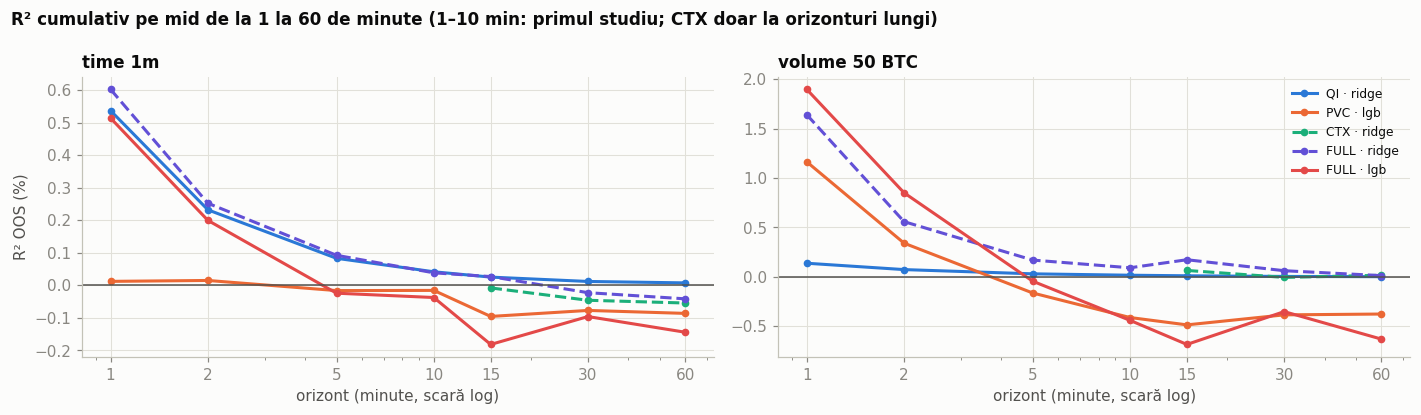

In [13]:
RES2 = cached("res_stage2", lambda: results_table2(SETS2, LONG_T + ["P30"], ["QI", "PVC", "CTX", "FULL"]))
V1N = pickle.loads((CACHE1 / "res_native_clock.pkl").read_bytes())
V1S = pickle.loads((CACHE1 / "res_segments.pkl").read_bytes())


def fmt(r):
    return f"{r['r2']:.3f} [{r['lo']:.2f}, {r['hi']:.2f}]"


rows = {}
for s in SETS2:
    for fs, m in [("QI", "ridge"), ("PVC", "lgb"), ("CTX", "ridge"), ("CTX", "lgb"), ("FULL", "ridge"), ("FULL", "lgb")]:
        r = {}
        for t in ["C1", "C2", "C5", "C10"]:
            v = V1N[(V1N["set"] == s) & (V1N["țintă"] == t) & (V1N["features"] == fs) & (V1N["model"] == m)]
            r[f"{t} (studiul 1)"] = fmt(v.iloc[0]) if len(v) else ""
        for t in LONG_T + ["P30"]:
            v = RES2[(RES2["set"] == s) & (RES2["țintă"] == t) & (RES2["features"] == fs) & (RES2["model"] == m)]
            r[t] = fmt(v.iloc[0]) if len(v) else ""
        rows[(LABEL[s], f"{fs} · {m}")] = r
display(Markdown("**R² OOS (%) [IC 95%, blocuri de 5 zile] pe mid: orizonturile scurte din primul studiu (referință, inventarul de atunci) și orizonturile lungi de aici.** "
                 "`S10_30` și `S30_60` sunt intervalele ulterioare, cu informația de la momentul inițial; `P30` este ținta placebo."))
display(pd.DataFrame(rows).T)
display(Markdown("**Aceleași celule pe ținta winsorizată la limitele din train** (robustețe la câteva mișcări extreme)."))
display(RES2.assign(v=RES2.apply(lambda r: f"{r['r2_clip']:.3f} [{r['lo_clip']:.2f}, {r['hi_clip']:.2f}]", axis=1))
        .pivot_table(index=["set", "features", "model"], columns="țintă", values="v", aggfunc="first")[LONG_T + ["P30"]])
display(Markdown("**IC, panta de calibrare și luni pozitive.**"))
display(RES2[RES2["features"].isin(["CTX", "FULL"])].set_index(["set", "features", "model", "țintă"])[["IC", "panta_calibrare", "luni_poz", "RMSE (bps)", "RMSE zero (bps)"]]
        .unstack("țintă").round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
HX = {"C1": 1, "C2": 2, "C5": 5, "C10": 10, "C15": 15, "C30": 30, "C60": 60}
for ax, s in zip(axes, SETS2):
    for (fs, m), col, ls in [(("QI", "ridge"), C["blue"], "-"), (("PVC", "lgb"), C["orange"], "-"), (("CTX", "ridge"), C["aqua"], "--"),
                             (("FULL", "ridge"), C["violet"], "--"), (("FULL", "lgb"), C["red"], "-")]:
        pts = []
        for t, h in HX.items():
            src = V1N if h <= 10 else RES2
            v = src[(src["set"] == s) & (src["țintă"] == t) & (src["features"] == fs) & (src["model"] == m)]
            if len(v):
                pts.append((h, v["r2"].iloc[0], v["lo"].iloc[0], v["hi"].iloc[0]))
        if pts:
            P = np.array(pts)
            ax.plot(P[:, 0], P[:, 1], color=col, ls=ls, marker="o", ms=4, label=f"{fs} · {m}")
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xscale("log")
    ax.set_xticks(list(HX.values()), [str(h) for h in HX.values()])
    ax.set_title(LABEL[s])
    ax.set_xlabel("orizont (minute, scară log)")
axes[0].set_ylabel("R² OOS (%)")
axes[1].legend(fontsize=8)
fig.suptitle("R² cumulativ pe mid de la 1 la 60 de minute (1–10 min: primul studiu; CTX doar la orizonturi lungi)", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
plt.show()

**Există avantaj predictiv la 15–60 de minute?** În configurațiile testate, aproape deloc:

* **`time_1m`:** singurul rezultat pozitiv cu interval care exclude zero este `qi_1` (ridge): 0,025% la 15 minute, 0,012% la 30 și 0,007% la 60, adică efectul permanent din primele secunde, diluat de varianța orizontului. Modelul complet ridge dă +0,027% la 15 minute (interval care include zero) și ≤ 0 mai departe; LightGBM complet este semnificativ negativ la toate orizonturile lungi.
* **`volume_50btc`:** ridge complet are +0,17% la 15 minute și +0,06% la 30 minute, cu intervale care includ zero; LightGBM și PVC sunt negative.
* **Contextul lent (`CTX`: bază, funding, OI, lichidări peste PVC):** ≤ 0 pe ambele seturi, la toate orizonturile.
* **Intervalele ulterioare 10–30 și 30–60 de minute:** R² ≈ 0 sau negativ pentru toate modelele, inclusiv `qi_1` (exact 0,000). Ce se vede cumulativ la 15–60 de minute este mișcarea inițială, nu o anticipare a perioadei de după.
* **Placebo `P30`:** ridge ≈ 0, LightGBM negativ (−0,18% pe `time_1m`), exact cât valorează „zgomotul de supra-ajustare” al LightGBM la aceste orizonturi.
* Pe ținta winsorizată, concluziile nu se schimbă; LightGBM rămâne negativ.

Calibrarea confirmă: pantele modelelor complete merg de la −0,05 la 0,93 (supra-încredere, uneori semn greșit), iar IC-urile sunt sub 0,045.

In [14]:
rows = []
for s in SETS2:
    for t in LONG_T:
        for m in ("ridge", "lgb"):
            for a_, b_ in [("FULL", "PVC"), ("CTX", "PVC"), ("FULL", "CTX"), ("PVC", "QI")]:
                st = paired(s, t, a_, b_, m)
                stc = paired(s, t, a_, b_, m, clip=True)
                rows.append({"set": LABEL[s], "țintă": t, "model": m, "comparație": f"{a_} − {b_}", **st,
                             "r2_clip": stc["r2"], "lo_clip": stc["lo"], "hi_clip": stc["hi"]})
INC2 = pd.DataFrame(rows)
INC2["p_holm"] = np.nan
for (m, cmp), g in INC2.groupby(["model", "comparație"]):
    INC2.loc[g.index, "p_holm"] = holm(g["p"].to_numpy())
INC2["ΔR²"] = INC2.apply(lambda r: f"{r['r2']:+.3f} [{r['lo']:+.2f}, {r['hi']:+.2f}]{'*' if r['p_holm'] < 0.05 else ''}", axis=1)
display(Markdown("**Increment de R² (pp) pe aceleași rânduri; `*` = Holm p < 0,05 în familia de 10 comparații (2 seturi × 5 ținte) a rândului.** "
                 "`CTX − PVC` = ce aduc baza, funding-ul, OI și lichidările peste preț-volum-calendar; `FULL − CTX` = ce aduc book-ul și fluxul rapid peste contextul lent."))
display(INC2.pivot_table(index=["comparație", "model", "set"], columns="țintă", values="ΔR²", aggfunc="first")[LONG_T])

**Increment de R² (pp) pe aceleași rânduri; `*` = Holm p < 0,05 în familia de 10 comparații (2 seturi × 5 ținte) a rândului.** `CTX − PVC` = ce aduc baza, funding-ul, OI și lichidările peste preț-volum-calendar; `FULL − CTX` = ce aduc book-ul și fluxul rapid peste contextul lent.

țintă                                             C15                    C30                    C60                  S10_30                 S30_60
comparație model set                                                                                                                              
CTX − PVC  lgb   time 1m        +0.080 [-0.05, +0.21]  -0.104 [-0.32, +0.11]  -0.204 [-0.50, +0.08]   -0.025 [-0.10, +0.06]  -0.051 [-0.14, +0.03]
                 volume 50 BTC  -0.500 [-1.27, +0.39]  -0.921 [-1.96, +0.20]  -0.041 [-0.58, +0.64]   -0.419 [-1.24, +0.46]  -0.004 [-0.23, +0.25]
           ridge time 1m        -0.002 [-0.04, +0.03]  +0.021 [-0.05, +0.09]  +0.033 [-0.09, +0.18]   +0.022 [-0.03, +0.07]  +0.052 [-0.03, +0.15]
                 volume 50 BTC  +0.090 [-0.12, +0.33]  +0.110 [-0.16, +0.36]  +0.185 [+0.00, +0.37]  +0.220 [+0.07, +0.37]*  -0.017 [-0.10, +0.06]
FULL − CTX lgb   time 1m        -0.166 [-0.29, -0.04]  +0.085 [-0.07, +0.24]  +0.146 [-0.09, +0.39]   -0.069 [-0.13, +0.01]  -0.048 [-0.12, +0.02]
                 volume 50 BTC  +0.302 [-0.20, +0.72]  +0.954 [+0.01, +1.72]  -0.213 [-0.78, +0.33]   -0.013 [-0.25, +0.20]  -0.013 [-0.27, +0.22]
           ridge time 1m        +0.035 [+0.00, +0.06]  +0.023 [-0.02, +0.06]  +0.013 [-0.03, +0.06]   +0.010 [-0.01, +0.03]  -0.003 [-0.01, +0.00]
                 volume 50 BTC  +0.108 [-0.09, +0.30]  +0.068 [-0.11, +0.30]  -0.004 [-0.15, +0.16]   -0.014 [-0.09, +0.08]  +0.061 [-0.01, +0.14]
FULL − PVC lgb   time 1m        -0.086 [-0.23, +0.04]  -0.019 [-0.21, +0.16]  -0.058 [-0.30, +0.19]   -0.095 [-0.18, -0.00]  -0.099 [-0.19, -0.01]
                 volume 50 BTC  -0.198 [-0.86, +0.58]  +0.033 [-0.66, +0.82]  -0.254 [-0.78, +0.36]   -0.431 [-1.22, +0.41]  -0.017 [-0.15, +0.13]
           ridge time 1m        +0.033 [-0.01, +0.08]  +0.044 [-0.03, +0.13]  +0.046 [-0.07, +0.19]   +0.032 [-0.02, +0.09]  +0.049 [-0.04, +0.15]
                 volume 50 BTC  +0.198 [-0.05, +0.50]  +0.177 [-0.07, +0.57]  +0.181 [-0.04, +0.48]  +0.207 [+0.08, +0.32]*  +0.045 [-0.01, +0.11]
PVC − QI   lgb   time 1m        -0.115 [-0.22, -0.00]  -0.083 [-0.27, +0.11]  -0.092 [-0.30, +0.10]   -0.008 [-0.08, +0.05]  +0.008 [-0.03, +0.05]
                 volume 50 BTC  -0.489 [-1.19, +0.16]  -0.381 [-1.25, +0.35]  -0.355 [-0.99, +0.13]   -1.873 [-3.13, -0.63]  -0.044 [-0.18, +0.06]
           ridge time 1m        -0.031 [-0.08, +0.01]  -0.078 [-0.20, +0.02]  -0.095 [-0.28, +0.04]   -0.048 [-0.13, +0.02]  -0.055 [-0.16, +0.04]
                 volume 50 BTC  -0.036 [-0.41, +0.26]  -0.119 [-0.59, +0.34]  -0.171 [-0.62, +0.27]   -0.385 [-0.74, -0.03]  -0.029 [-0.17, +0.09]

**Ce adaugă fiecare bloc.** Niciun increment nu este pozitiv și semnificativ, cu o singură excepție aparentă: pe `volume_50btc`, intervalul 10–30 de minute, `CTX − PVC` și `FULL − PVC` în ridge (+0,21–0,22 pp, Holm p < 0,05). Ambele modele au însă R² negativ acolo (PVC −0,32%, CTX −0,13%): incrementul măsoară cât de puțin greșește contextul lent față de un model PVC care supra-ajustează, nu o predicție. Microstructura rapidă peste contextul lent (`FULL − CTX`) este ≈ 0 la orizonturile lungi, cu excepția unui +0,04 pp ridge la 15 minute pe `time_1m` (rămășița imbalance-ului).

**Stabilitate: influența câtorva zile și împărțirea dezvoltare / perioadă târzie.**

R² (%)  fără cele 5 zile influente (%)  pondere 5 zile în Σy² (%)  R² dezvoltare (F1–F4)  R² târziu (F5–F7)
set           țintă  model                                                                                                                    
time 1m       C15    CTX · ridge   -0.008                          -0.007                      7.906                  0.001             -0.029
                     FULL · ridge   0.027                           0.033                      8.316                  0.020              0.042
                     FULL · lgb    -0.182                          -0.130                      3.750                 -0.179             -0.189
              C30    CTX · ridge   -0.046                          -0.004                      1.730                 -0.065             -0.003
                     FULL · ridge  -0.023                          -0.014                      7.817                 -0.042              0.020
                     FULL · lgb    -0.096                          -0.094                      5.558                 -0.100             -0.088
              C60    CTX · ridge   -0.054                          -0.028                      3.453                 -0.047             -0.071
                     FULL · ridge  -0.042                          -0.000                      2.290                 -0.060             -0.002
                     FULL · lgb    -0.144                          -0.070                      3.714                 -0.100             -0.240
              S10_30 CTX · ridge   -0.026                          -0.007                      2.267                 -0.036             -0.003
                     FULL · ridge  -0.016                           0.002                      1.518                 -0.023              0.001
                     FULL · lgb    -0.102                          -0.086                      5.319                 -0.103             -0.098
              S30_60 CTX · ridge   -0.003                          -0.005                      3.036                 -0.005              0.000
                     FULL · ridge  -0.006                          -0.000                      3.063                 -0.004             -0.010
                     FULL · lgb    -0.094                          -0.062                      4.027                 -0.084             -0.114
volume 50 BTC C15    CTX · ridge    0.065                           0.047                      9.008                 -0.004              0.209
                     FULL · ridge   0.173                           0.157                     16.631                  0.004              0.526
                     FULL · lgb    -0.683                          -0.319                     13.034                 -0.944             -0.138
              C30    CTX · ridge   -0.005                          -0.034                      7.517                 -0.096              0.200
                     FULL · ridge   0.063                           0.105                     19.228                 -0.186              0.628
                     FULL · lgb    -0.351                          -0.280                      5.210                 -0.697              0.435
              C60    CTX · ridge    0.016                           0.093                     17.221                 -0.088              0.266
                     FULL · ridge   0.013                           0.114                     17.221                 -0.105              0.293
                     FULL · lgb    -0.629                          -0.091                     20.310                 -0.599             -0.701
              S10_30 CTX · ridge   -0.165                          -0.085                     21.587                 -0.215             -0.041
                     FULL · ridge  -0.179                          -0.018                     21.085                 -0.275              0.061
                     FULL · lgb

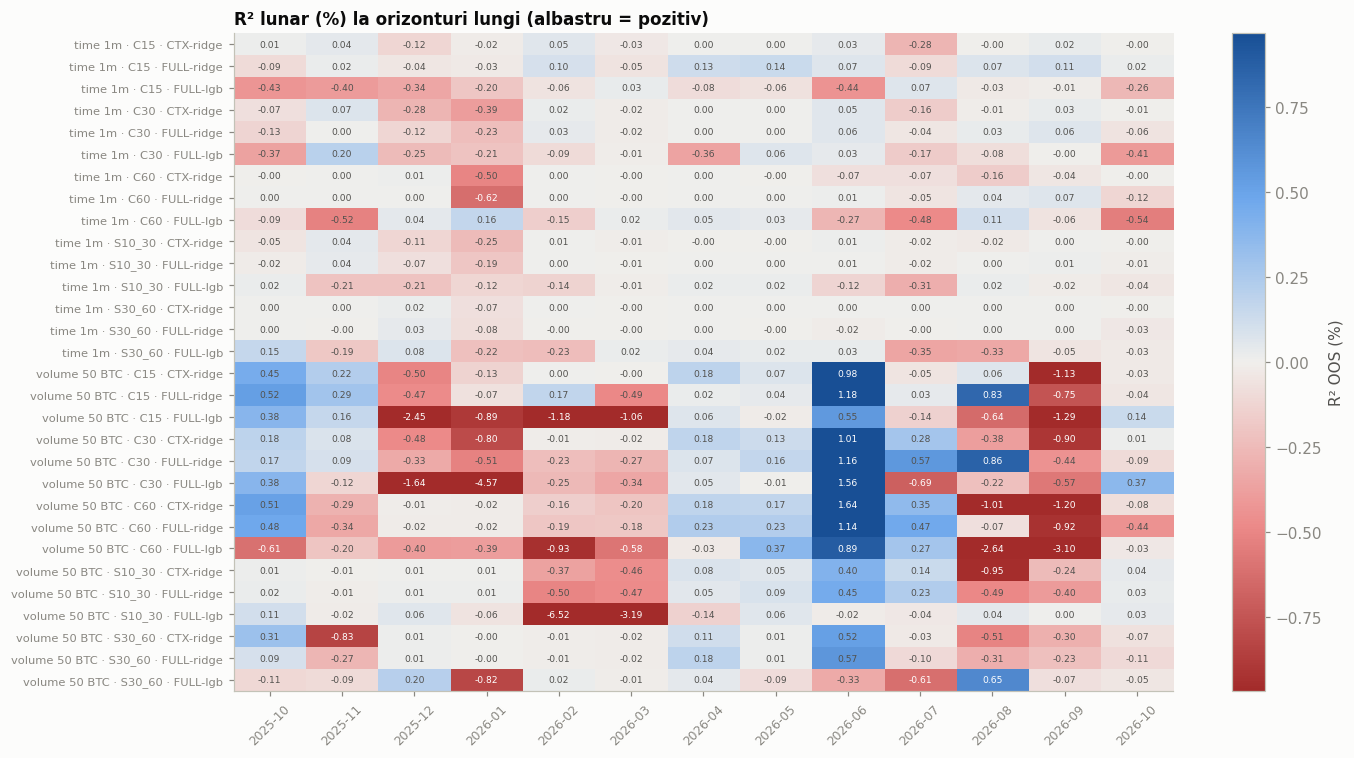

In [15]:
KEY2 = [(s, t, fs, m) for s in SETS2 for t in ["C15", "C30", "C60", "S10_30", "S30_60"] for fs, m in [("CTX", "ridge"), ("FULL", "ridge"), ("FULL", "lgb")]]
rows, mon = [], []
for s, t, fs, m in KEY2:
    d = cell_data2(s, t, fs)
    A, Bm = daily_sums(d, d[m].to_numpy())
    gain = A - Bm
    top = np.argsort(-np.abs(gain))[:5]
    keep = np.ones(ND, bool)
    keep[top] = False
    rows.append({"set": LABEL[s], "țintă": t, "model": f"{fs} · {m}", "R² (%)": 100 * gain.sum() / A.sum(),
                 "fără cele 5 zile influente (%)": 100 * gain[keep].sum() / A[keep].sum(), "pondere 5 zile în Σy² (%)": 100 * A[top].sum() / A.sum(),
                 "R² dezvoltare (F1–F4)": 100 * gain[:np.searchsorted(EVAL_DAYS, DEV_END)].sum() / A[:np.searchsorted(EVAL_DAYS, DEV_END)].sum(),
                 "R² târziu (F5–F7)": 100 * gain[np.searchsorted(EVAL_DAYS, DEV_END):].sum() / A[np.searchsorted(EVAL_DAYS, DEV_END):].sum()})
    mm = pd.DataFrame({"A": A, "B": Bm}, index=EVAL_DAYS).groupby(EVAL_DAYS.strftime("%Y-%m")).sum()
    for mo, r_ in mm.iterrows():
        mon.append({"celulă": f"{LABEL[s]} · {t} · {fs}-{m}", "luna": mo, "r2": 100 * (1 - r_["B"] / r_["A"])})
display(Markdown("**Stabilitate: influența câtorva zile și împărțirea dezvoltare / perioadă târzie.**"))
display(pd.DataFrame(rows).set_index(["set", "țintă", "model"]).round(3))
MON2 = pd.DataFrame(mon).pivot(index="celulă", columns="luna", values="r2")
MON2 = MON2.loc[[f"{LABEL[s]} · {t} · {fs}-{m}" for s, t, fs, m in KEY2]]
fig, ax = plt.subplots(figsize=(13, 7))
lim = np.nanpercentile(np.abs(MON2.to_numpy()), 95)
im = ax.imshow(MON2.to_numpy(), aspect="auto", cmap=DIVERGING, vmin=-lim, vmax=lim)
ax.set_yticks(range(len(MON2)), MON2.index, fontsize=7.5)
ax.set_xticks(range(MON2.shape[1]), MON2.columns, rotation=45, fontsize=8)
ax.grid(False)
for i in range(MON2.shape[0]):
    for j in range(MON2.shape[1]):
        v = MON2.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 0.6 * lim else INK2)
fig.colorbar(im, ax=ax, label="R² OOS (%)")
ax.set_title("R² lunar (%) la orizonturi lungi (albastru = pozitiv)")
fig.tight_layout()
plt.show()

**Stabilitate.** Pe `time_1m`, rezultatele sunt ≈ 0 în ambele perioade și nu depind de câteva zile. Pe `volume_50btc`, ridge complet este negativ pe dezvoltare și pozitiv pe perioada târzie (+0,5–0,6% la 15–30 de minute), iar cele 5 zile cele mai influente reprezintă 17–19% din Σy². Un astfel de rezultat, apărut doar în a doua jumătate și concentrat în câteva zile, nu este o dovadă; poate fi verificat doar pe date de după octombrie 2026.

### 4.4 Se schimbă familiile informative cu orizontul?

Trei surse, de la cea mai fină la cea mai robustă la substituție: (a) SFI exhaustiv pe toate features la orizonturile lungi (aceeași metodă ca în primul studiu: funcție în trepte învățată pe train, R² out-of-sample, BH pe fiecare țintă, 20 de features placebo); (b) importanța prin permutare pe familii și blocuri economice în modelul complet; (c) comparațiile de modele `CTX − PVC` și `FULL − CTX` de mai sus.

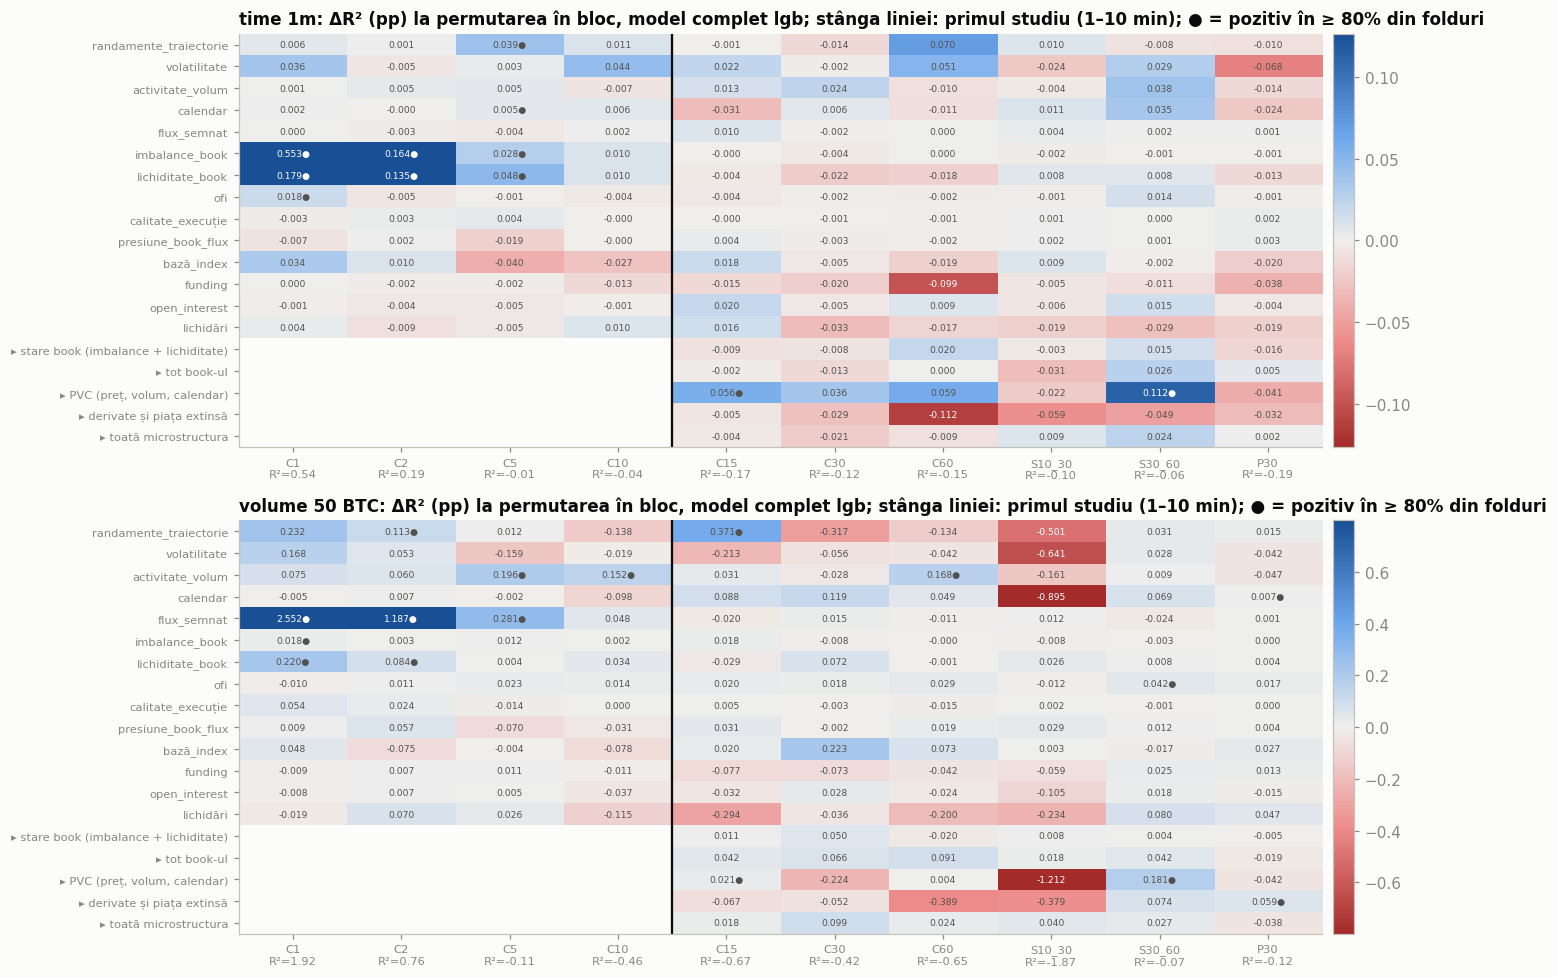

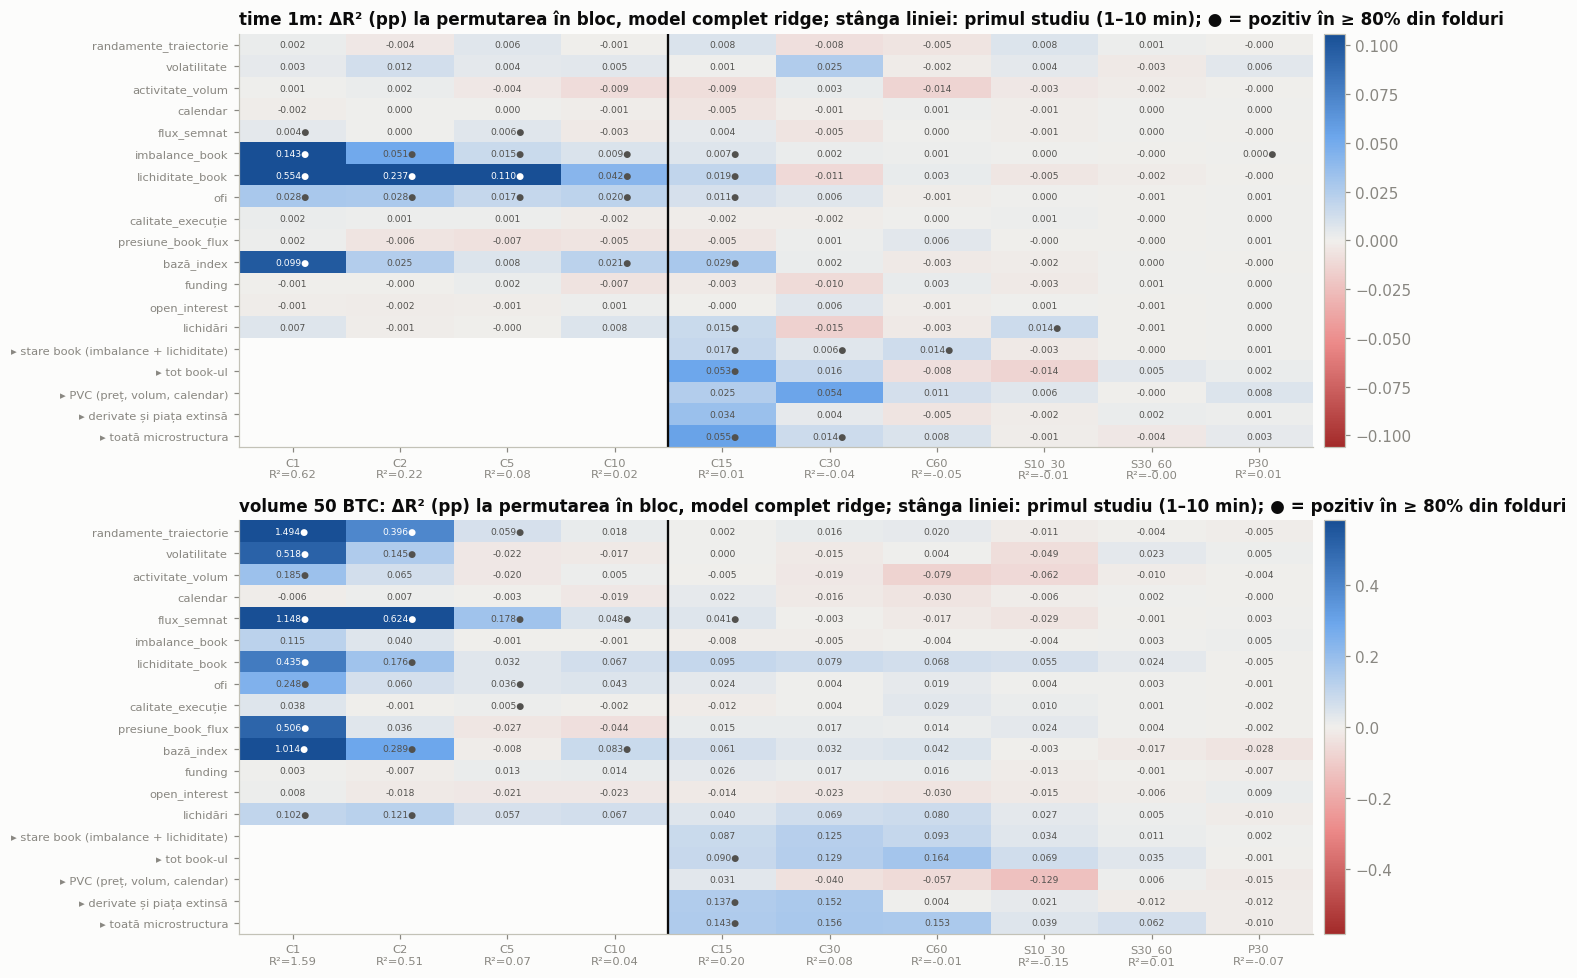

In [16]:
def mda_from(cellfile, model="lgb", key_prefix=""):
    r = pickle.loads(Path(cellfile).read_bytes())
    rec = [f for f in r["folds"] if ("mda_lgb" in f)]
    if not rec:
        return None, None
    key = "mda_lgb" if model == "lgb" else "mda_ridge"
    base = "mda_base_lgb" if model == "lgb" else "mda_base_ridge"
    y2 = np.array([f["mda_y2"] for f in rec])
    names = list(rec[0][key].keys())
    pooled = pd.Series({g: sum(np.mean(f[key][g]) for f in rec) / y2.sum() * 100 for g in names})
    share = pd.Series({g: np.mean([np.mean(f[key][g]) > 0 for f in rec]) for g in names})
    r2 = 100 * (1 - sum(f[base] for f in rec) / y2.sum())
    pooled.index = [key_prefix + (g if g.startswith(("familie", "bloc")) else f"familie: {g}") for g in pooled.index]
    share.index = pooled.index
    return pooled, (share, r2)


MAPS2 = {}
for s in SETS2:
    for model in ("lgb", "ridge"):
        P, S, R = {}, {}, {}
        for t in ["C1", "C2", "C5", "C10"]:
            p, (sh, r2) = mda_from(CACHE1 / "cells" / f"native__{s}__{t}__FULL.pkl", model)
            P[t], S[t], R[t] = p, sh, r2
        for t in LONG_T + ["P30"]:
            p, (sh, r2) = mda_from(CELLS2 / f"{s}__{t}__FULL.pkl", model)
            P[t], S[t], R[t] = p, sh, r2
        MAPS2[(s, model)] = (pd.DataFrame(P), pd.DataFrame(S), pd.Series(R))


def plot_map2(model):
    order = [f"familie: {g}" for g in FAMILY_DISPLAY_ORDER] + [f"bloc: {b}" for b in BLOCKS]
    fig, axes = plt.subplots(len(SETS2), 1, figsize=(13, 9))
    for ax, s in zip(axes, SETS2):
        P, S, R = MAPS2[(s, model)]
        P, S = P.reindex([o for o in order if o in P.index]), S.reindex([o for o in order if o in P.index])
        lim = max(np.nanpercentile(np.abs(P.to_numpy()), 98), 1e-3)
        im = ax.imshow(P.to_numpy(), aspect="auto", cmap=DIVERGING, vmin=-lim, vmax=lim)
        ax.set_yticks(range(len(P)), [i.replace("familie: ", "").replace("bloc: ", "▸ ") for i in P.index], fontsize=7.5)
        ax.set_xticks(range(P.shape[1]), [f"{c}\nR²={R[c]:.2f}" for c in P.columns], fontsize=7.5)
        ax.axvline(3.5, color=INK, lw=1.5)
        ax.grid(False)
        for i in range(P.shape[0]):
            for j in range(P.shape[1]):
                v = P.iat[i, j]
                if np.isfinite(v):
                    ax.text(j, i, f"{v:.3f}{'●' if S.iat[i, j] >= 0.8 and v > 0 else ''}", ha="center", va="center", fontsize=6,
                            color="white" if abs(v) > 0.6 * lim else INK2)
        ax.set_title(f"{LABEL[s]}: ΔR² (pp) la permutarea în bloc, model complet {model}; stânga liniei: primul studiu (1–10 min); ● = pozitiv în ≥ 80% din folduri")
        fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
    fig.tight_layout()
    plt.show()


plot_map2("lgb")
plot_map2("ridge")

**Harta familiilor până la 60 de minute.** În stânga liniei (1–10 minute, primul studiu), două familii poartă importanță robustă (● pe mai multe orizonturi): starea book-ului pe `time_1m` și fluxul semnat pe `volume_50btc`. În dreapta (15–60 de minute și intervalele ulterioare), modelele LightGBM au R² negativ, deci valorile lor descriu zgomotul pe care modelul îl folosește, nu informație; în ridge pe `volume_50btc` (R² 0,08–0,20% la 15–30 de minute), importanța este difuză între book, derivate și lichidări (0,04–0,16 pp fiecare), fără o familie dominantă și fără stabilitate între orizonturi. Familiile lente nu „preiau” informația la orizonturi lungi: ea dispare.

In [17]:
N_PLACEBO_FEAT, SFI_SUB = 20, 300_000
SFI_T2 = LONG_T + ["P30"]


def sfi_worker2(jlist):
    """Single-feature OOS importance (same method as the first notebook): 20-bin step function + linear slope per fold, train only."""
    threadpool_limits(1)
    X, tns, Y = CTX["XF"], CTX["tns"], CTX["Y"]
    day_all = (tns // (86400 * NS) - DAY0).astype(np.int64)
    out = {}
    for j in jlist:
        if j < X.shape[1]:
            x = X[:, j]
        else:
            src, sh = CTX["placebo"][j - X.shape[1]]
            x = np.roll(X[:, src], sh)
        for t in SFI_T2:
            yv = Y[t].astype(np.float64)
            Bb, Bl, betas = np.zeros(ND), np.zeros(ND), []
            for fi in range(len(FOLDS)):
                tr, te = CTX["rows"][(t, fi)]
                if len(tr) == 0:
                    continue
                trs = tr if len(tr) <= SFI_SUB else tr[np.linspace(0, len(tr) - 1, SFI_SUB).astype(np.int64)]
                lo, hi = CTX["clip"][(t, fi)]
                ytr = np.clip(yv[trs], lo, hi)
                xtr, xte, yte = x[trs], x[te], yv[te]
                fin, fte = np.isfinite(xtr), np.isfinite(xte)
                if fin.sum() < 1000:
                    betas.append(np.nan)
                    continue
                edges = np.unique(np.nanquantile(xtr[fin], np.linspace(0, 1, 21)[1:-1]))
                nb = len(edges) + 2
                btr = np.where(fin, np.searchsorted(edges, np.nan_to_num(xtr), side="right"), nb - 1)
                bte = np.where(fte, np.searchsorted(edges, np.nan_to_num(xte), side="right"), nb - 1)
                pb = (np.bincount(btr, ytr, nb) / (np.bincount(btr, minlength=nb) + 200))[bte]
                mu, sd = xtr[fin].mean(), xtr[fin].std() or 1.0
                beta = (((xtr[fin] - mu) / sd) * ytr[fin]).sum() / (((xtr[fin] - mu) / sd) ** 2).sum()
                pl = np.where(fte, beta * (np.nan_to_num(xte) - mu) / sd, 0.0)
                Bb += np.bincount(day_all[te], (yte - pb) ** 2, ND)
                Bl += np.bincount(day_all[te], (yte - pl) ** 2, ND)
                betas.append(beta)
            out[(j, t)] = (Bb.astype(np.float32), Bl.astype(np.float32), np.array(betas, np.float32))
    return out


def run_sfi2(s):
    tns = TNS[s]
    tg = TG2[s]
    XF = np.asfortranarray(np.load(CACHE2 / f"Xbase_{s}.npy"))
    ok = tg["elig"] & ~tg["crash"]
    rows, clip, A = {}, {}, {}
    day_all = (tns // (86400 * NS) - DAY0).astype(np.int64)
    for t in SFI_T2:
        Aa = np.zeros(ND)
        for fi, (a, b) in enumerate(FOLDS):
            tr, te = fold_rows(tns, tg["T1"][t], tg["Y"][t], ok, ok, a, b)
            rows[(t, fi)] = (tr, te)
            clip[(t, fi)] = tuple(np.percentile(tg["Y"][t][tr].astype(np.float64), [0.1, 99.9])) if len(tr) else (0, 0)
            Aa += np.bincount(day_all[te], tg["Y"][t][te].astype(np.float64) ** 2, ND)
        A[t] = Aa
    rng = np.random.default_rng(SEED + 7)
    cols = BASE[s]["columns"]
    src = rng.choice([i for i, c in enumerate(cols) if c != "qi_1"], N_PLACEBO_FEAT, replace=False)
    plc = [(int(j), int(rng.integers(int(0.3 * len(tns)), int(0.7 * len(tns))))) for j in src]
    CTX.clear()
    CTX.update({"XF": XF, "tns": tns, "Y": tg["Y"], "rows": rows, "clip": clip, "placebo": plc})
    ncol = XF.shape[1] + N_PLACEBO_FEAT
    chunks = [list(range(i, ncol, WORKERS * 3)) for i in range(WORKERS * 3)]
    res = {}
    with ProcessPoolExecutor(max_workers=WORKERS, mp_context=mp.get_context("fork")) as ex:
        for part in ex.map(sfi_worker2, chunks):
            res.update(part)
    names = cols + [f"PLACEBO_{k:02d}" for k in range(N_PLACEBO_FEAT)]
    CTX.clear()
    del XF
    gc.collect()
    return {"names": names, "A": A, "res": res}


def sfi_table2(S, targets):
    rows = []
    for t in targets:
        A = S["A"][t]
        Bb = np.stack([S["res"][(j, t)][0] for j in range(len(S["names"]))], 1).astype(np.float64)
        Bl = np.stack([S["res"][(j, t)][1] for j in range(len(S["names"]))], 1).astype(np.float64)
        gb = A[:, None] - Bb
        boot = (WBOOT @ gb) / (WBOOT @ A)[:, None]
        r2b, r2l, pb = gb.sum(0) / A.sum(), (A[:, None] - Bl).sum(0) / A.sum(), (boot <= 0).mean(0)
        betas = np.stack([S["res"][(j, t)][2] for j in range(len(S["names"]))], 0)
        for j, nm in enumerate(S["names"]):
            rows.append({"feature": nm, "țintă": t, "r2_bin": 100 * r2b[j], "p": pb[j], "r2_lin": 100 * r2l[j], "panta": np.nanmean(betas[j]),
                         "semn_stabil": np.nanmean(np.sign(betas[j]) == np.sign(np.nanmean(betas[j])))})
    T = pd.DataFrame(rows)
    T["placebo"] = T["feature"].str.startswith("PLACEBO_")
    T["familie"] = T["feature"].map(lambda c: FAMILY_LABEL.get(family_of(c), "placebo") if not c.startswith("PLACEBO") else "placebo")
    T["q"] = np.nan
    for t, g in T.groupby("țintă"):
        T.loc[g.index, "q"] = bh(g["p"].to_numpy())
    return T


t_ = time.time()
SFI2 = {s: cached(f"sfi2_{s}", lambda s=s: run_sfi2(s)) for s in SETS2}
SFI2T = {s: sfi_table2(SFI2[s], SFI_T2) for s in SETS2}
SFI1T = {}
for s in SETS2:                                  # the first notebook's SFI (1–10 min, segments up to 10 min), same method
    S1 = pickle.loads((CACHE1 / f"sfi_{s}.pkl").read_bytes())
    SFI1T[s] = sfi_table2({"names": S1["names"], "A": S1["A"], "res": S1["res"]}, ["C1", "C2", "C5", "C10", "S120_300", "S300_600"])
print(f"SFI pe orizonturile lungi: {(time.time() - t_) / 60:.1f} min.")
rows = []
for s in SETS2:
    for src, T in (("studiul 1", SFI1T[s]), ("aici", SFI2T[s])):
        for t, g in T.groupby("țintă", sort=False):
            real, plc = g[~g["placebo"]], g[g["placebo"]]
            best = real.sort_values("r2_bin").iloc[-1]
            rows.append({"set": LABEL[s], "țintă": t, "sursă": src, "reale q<0,05": int((real["q"] < 0.05).sum()), "din": len(real),
                         "placebo q<0,05": int((plc["q"] < 0.05).sum()), "cel mai bun": best["feature"], "familia": best["familie"],
                         "R² maxim (%)": best["r2_bin"], "R² maxim placebo (%)": plc["r2_bin"].max()})
display(Markdown("**SFI pe orizonturi (fiecare feature singur, out-of-sample): câte features au informație individuală semnificativă (BH q < 0,05).**"))
display(pd.DataFrame(rows).set_index(["set", "țintă"]).round(4))

SFI pe orizonturile lungi: 0.0 min.


**SFI pe orizonturi (fiecare feature singur, out-of-sample): câte features au informație individuală semnificativă (BH q < 0,05).**

sursă  reale q<0,05  din  placebo q<0,05                     cel mai bun                    familia  R² maxim (%)  R² maxim placebo (%)
set           țintă                                                                                                                                                
time 1m       C1        studiul 1            27  355               0                            qi_1          imbalance în book        0.5361               -0.0044
              C2        studiul 1            23  355               0                            qi_1          imbalance în book        0.2322               -0.0043
              C5        studiul 1            10  355               0                            qi_1          imbalance în book        0.0827               -0.0030
              C10       studiul 1             4  355               0                            qi_1          imbalance în book        0.0359               -0.0033
              S120_300  studiul 1             0  355               0           vwap_distance_15m_bps  randamente și traiectorie        0.0060               -0.0033
              S300_600  studiul 1             0  355               0             rebound_from_low_1h  randamente și traiectorie        0.0017               -0.0048
              C15            aici             0  368               0                    qty_ask1_btc  lichiditate și formă book        0.0190               -0.0043
              C30            aici             0  368               0                   ret_trade_15m  randamente și traiectorie        0.0135               -0.0089
              C60            aici             0  368               0                 trade_count_15m        activitate și volum        0.0323               -0.0064
              S10_30         aici             0  368               0                   ret_trade_15m  randamente și traiectorie        0.0073               -0.0049
              S30_60         aici             0  368               0            add_bid_10bps_2m_btc  OFI și adăugări/retrageri        0.0068               -0.0071
              P30            aici             0  368               0               cost_buy_5btc_bps  lichiditate și formă book        0.0100               -0.0029
volume 50 BTC C1        studiul 1            43  357               0                        run_sign  flux de tranzacții semnat        0.9956               -0.0050
              C2        studiul 1            31  357               0                        run_sign  flux de tranzacții semnat        0.5165               -0.0063
              C5        studiul 1             9  357               0                        run_sign  flux de tranzacții semnat        0.1938                0.0017
              C10       studiul 1             2  357               0       signed_large_flow_1h_usdt  flux de tranzacții semnat        0.1423               -0.0001
              S120_300  studiul 1             0  357               0       ret_trade_minus_index_15m          bază, mark, index        0.0259               -0.0079
              S300_600  studiul 1             0  357               0       signed_large_flow_1h_usdt  flux de tranzacții semnat        0.0661                0.0091
              C15            aici             1  370               0  ticker_vwap_distance_trade_bps  randamente și traiectorie        0.1149               -0.0277
              C30            aici             0  370               0       min_depth_bid_5bps_5s_btc  lichiditate și formă book        0.1068               -0.0233
              C60            aici             0  370               0  ticker_vwap_distance_trade_bps  randamente și traiectorie        0.1855               -0.0137
              S10_30         aici             0  370               0                        lrvb_24h               volatilitate        0.0172               -0.0335
              S30_60         aici             0  370               0                 trade_c

**Informația individuală la orizonturi lungi.** Numărul de features cu q < 0,05 scade de la 23–43 la 1–2 minute la 9–10 la 5 minute, 2–4 la 10 minute și la **zero** la 30 și 60 de minute și pe intervalele ulterioare, pe ambele seturi (o singură excepție: distanța față de VWAP-ul de 24 h la 15 minute pe `volume_50btc`). Niciun feature placebo nu trece. Cele mai bune R² individuale la orizonturi lungi sunt 0,01–0,03% pe `time_1m` și 0,1–0,19% pe `volume_50btc`, nesemnificative după corecție.

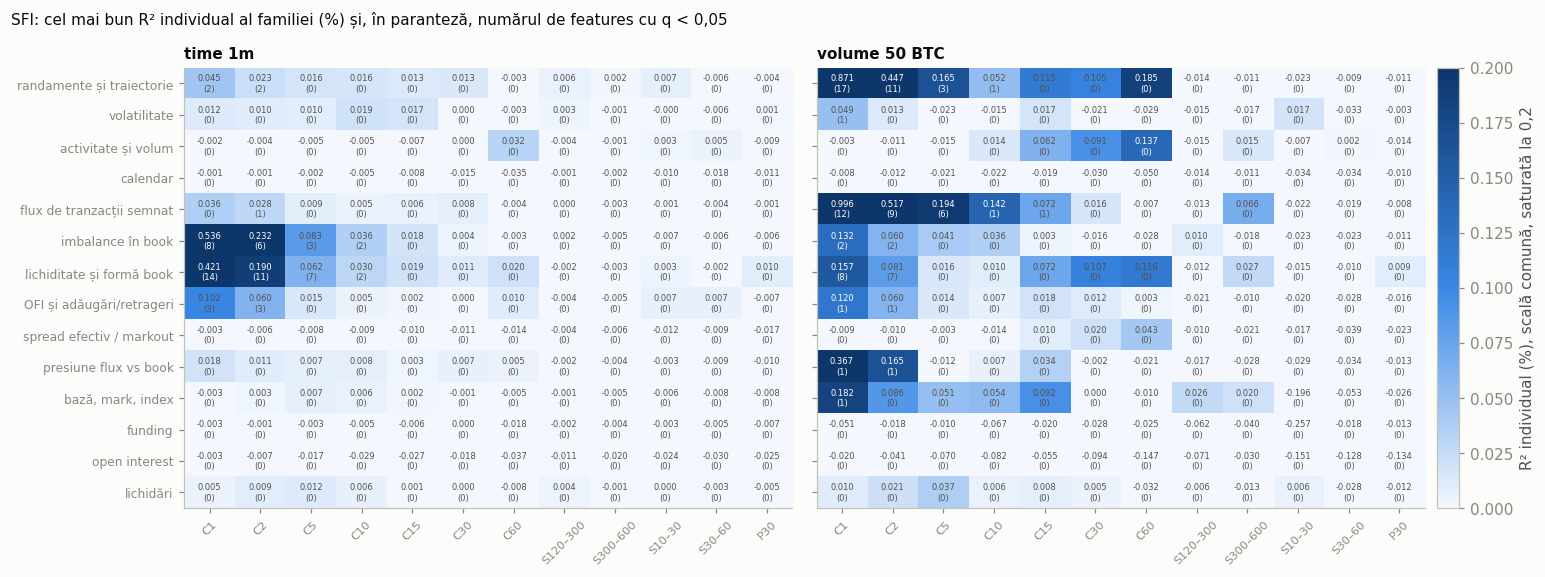

In [18]:
ORDER_T = ["C1", "C2", "C5", "C10", "C15", "C30", "C60", "S120_300", "S300_600", "S10_30", "S30_60", "P30"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"wspace": 0.04})
VMAX = 0.2                                          # common colour scale for both panels (% R², saturated)
for ax, s in zip(axes, SETS2):
    T = pd.concat([SFI1T[s], SFI2T[s]])
    T = T[~T["placebo"]]
    best = T.groupby(["familie", "țintă"])["r2_bin"].max().unstack().reindex(columns=ORDER_T)
    nsig = T[T["q"] < 0.05].groupby(["familie", "țintă"]).size().unstack().reindex(index=best.index, columns=ORDER_T).fillna(0)
    best = best.reindex([FAMILY_LABEL[g] for g in FAMILY_DISPLAY_ORDER])
    nsig = nsig.reindex(best.index).fillna(0)
    V = np.clip(best.to_numpy(), 0, None)
    im = ax.imshow(V, aspect="auto", cmap=LinearSegmentedColormap.from_list("b", ["#f4f8fe", "#3987e5", "#0d366b"]), vmin=0, vmax=VMAX)
    ax.set_yticks(range(len(best)), best.index if ax is axes[0] else [""] * len(best), fontsize=8)
    ax.set_xticks(range(len(ORDER_T)), [t.replace("_", "–") for t in ORDER_T], fontsize=7.5, rotation=45)
    ax.grid(False)
    for i in range(V.shape[0]):
        for j in range(V.shape[1]):
            ax.text(j, i, f"{best.iat[i, j]:.3f}\n({int(nsig.iat[i, j])})", ha="center", va="center", fontsize=5.5,
                    color="white" if V[i, j] > 0.6 * VMAX else INK2)
    ax.set_title(LABEL[s], fontsize=10, loc="left")
fig.suptitle("SFI: cel mai bun R² individual al familiei (%) și, în paranteză, numărul de features cu q < 0,05", fontsize=10, x=0.02, ha="left")
fig.colorbar(im, ax=axes.tolist(), fraction=0.02, pad=0.01, label="R² individual (%), scală comună, saturată la 0,2")
plt.show()

Graficul arată cel mai bun R² individual din fiecare familie și, în paranteză, câte features din familie au q < 0,05. Coloanele scurte sunt dominate de imbalance (time) și flux (volume); la orizonturile lungi, toate familiile au zero features semnificative, iar valorile maxime sunt mici și împrăștiate (prețul vs VWAP-ul de 24 h, activitatea pe 15 minute).

In [19]:
SLOW = ["open interest", "funding", "bază, mark, index", "lichidări", "randamente și traiectorie", "volatilitate", "activitate și volum"]
rows = []
for s in SETS2:
    T = SFI2T[s]
    T = T[~T["placebo"] & T["familie"].isin(SLOW)]
    for fam in SLOW:
        g = T[T["familie"] == fam]
        for t in LONG_T:
            gt = g[g["țintă"] == t].sort_values("r2_bin", ascending=False)
            if not len(gt):
                continue
            b = gt.iloc[0]
            rows.append({"set": LABEL[s], "familie": fam, "țintă": t, "cel mai bun feature": b["feature"], "R² trepte (%)": b["r2_bin"],
                         "R² liniar (%)": b["r2_lin"], "q": b["q"], "panta (bps/SD)": b["panta"], "semn stabil": b["semn_stabil"],
                         "features cu q<0,05": int((gt["q"] < 0.05).sum())})
SLOWT = pd.DataFrame(rows)
display(Markdown("**Familiile lente și contextul de preț/volum la orizonturi lungi (SFI): cel mai bun feature pe familie și țintă.**"))
display(SLOWT.pivot_table(index=["set", "familie"], columns="țintă", values="R² trepte (%)", aggfunc="first")[LONG_T].round(4))
display(SLOWT[SLOWT["features cu q<0,05"] > 0].set_index(["set", "familie", "țintă"]).round(4))

**Familiile lente și contextul de preț/volum la orizonturi lungi (SFI): cel mai bun feature pe familie și țintă.**

țintă                                       C15     C30     C60  S10_30  S30_60
set           familie                                                          
time 1m       activitate și volum       -0.0068  0.0004  0.0323  0.0028  0.0052
              bază, mark, index          0.0018 -0.0007 -0.0050 -0.0056 -0.0080
              funding                   -0.0059  0.0004 -0.0180 -0.0031 -0.0051
              lichidări                  0.0007  0.0005 -0.0077  0.0001 -0.0033
              open interest             -0.0270 -0.0184 -0.0374 -0.0244 -0.0296
              randamente și traiectorie  0.0128  0.0135 -0.0025  0.0073 -0.0057
              volatilitate               0.0171  0.0003 -0.0025 -0.0004 -0.0056
volume 50 BTC activitate și volum        0.0621  0.0911  0.1374 -0.0071  0.0017
              bază, mark, index          0.0918  0.0001 -0.0101 -0.1963 -0.0531
              funding                   -0.0201 -0.0278 -0.0254 -0.2575 -0.0176
              lichidări                  0.0079  0.0049 -0.0319  0.0060 -0.0278
              open interest             -0.0545 -0.0937 -0.1474 -0.1508 -0.1278
              randamente și traiectorie  0.1149  0.1047  0.1855 -0.0225 -0.0085
              volatilitate               0.0165 -0.0205 -0.0289  0.0172 -0.0333

,,,cel mai bun feature,R² trepte (%),R² liniar (%),q,panta (bps/SD),semn stabil,"features cu q<0,05"
set,familie,țintă,,,,,,,


**Familiile lente, explicit.** Open interest are R² individual negativ la toate orizonturile lungi pe ambele seturi; funding-ul, baza și lichidările stau în jurul lui zero. Contextul de preț și volum (distanța față de VWAP-ul de 24 h, activitatea pe 15 minute, randamentul pe 15 minute) are cele mai mari valori (până la 0,19% pe `volume_50btc`), dar niciuna nu trece corecția pentru comparații multiple. **Concluzia este limitată la 60 de minute:** nu spune nimic despre funding sau OI la orizonturi de ore sau zile.

In [20]:
DEV2 = cached("res_stage2_dev", lambda: results_table2(SETS2, ["C15", "C30", "C60"], ["FULL"], dev_only=True))
display(Markdown("**Regula de alegere a orizontului lung pentru etapa 3 (fixată înainte de rulare):** pe foldurile de dezvoltare (F1–F4), un orizont are avantaj dacă "
                 "ridge sau LightGBM FULL are R² > 0 cu limita inferioară a intervalului bootstrap > 0 pe cel puțin un set; dintre acestea se alege cel cu cea mai "
                 "mare limită inferioară; dacă niciunul nu are avantaj, se folosește 30 de minute drept control."))
display(DEV2[["set", "țintă", "model", "r2", "lo", "hi"]].round(4))
cand = DEV2[DEV2["lo"] > 0]
LONG_PICK = cand.sort_values("lo", ascending=False)["țintă"].iloc[0] if len(cand) else "C30"
LONG_ROLE = "orizontul cu avantaj pe dezvoltare" if len(cand) else "control (niciun orizont lung nu are avantaj pe dezvoltare)"
print(f"Orizontul lung ales pentru etapa 3: {LONG_PICK} — {LONG_ROLE}.")

**Regula de alegere a orizontului lung pentru etapa 3 (fixată înainte de rulare):** pe foldurile de dezvoltare (F1–F4), un orizont are avantaj dacă ridge sau LightGBM FULL are R² > 0 cu limita inferioară a intervalului bootstrap > 0 pe cel puțin un set; dintre acestea se alege cel cu cea mai mare limită inferioară; dacă niciunul nu are avantaj, se folosește 30 de minute drept control.

,set,țintă,model,r2,lo,hi
0,time_1m,C15,ridge,0.0199,-0.0594,0.0904
1,time_1m,C15,lgb,-0.1787,-0.3064,-0.0733
2,time_1m,C30,ridge,-0.0423,-0.1334,0.0317
3,time_1m,C30,lgb,-0.0999,-0.1871,-0.0215
4,time_1m,C60,ridge,-0.0597,-0.1474,0.0090
5,time_1m,C60,lgb,-0.1001,-0.3209,0.1019
6,volume_50btc,C15,ridge,0.0043,-0.2858,0.2591
7,volume_50btc,C15,lgb,-0.9443,-1.6255,-0.1629
8,volume_50btc,C30,ridge,-0.1864,-0.3706,0.0214
9,volume_50btc,C30,lgb,-0.6973,-1.6553,-0.0740


Orizontul lung ales pentru etapa 3: C30 — control (niciun orizont lung nu are avantaj pe dezvoltare).


Pe dezvoltare, niciun orizont lung nu are R² cu limita inferioară peste zero (cea mai bună: ridge la 15 minute pe `time_1m`, +0,02% [−0,06; +0,09]). Conform regulii, etapa 3 folosește **30 de minute drept control**, fără să caute alt câștigător.

## 5. Contribuția istoricului explicit

**Ce compar**, pe aceleași rânduri, ținte, folduri și cu același protocol: `FULL` (features curente, un singur rând) față de `FULL` plus **rezumate** ale evoluției recente (`R`) și `FULL` plus **valori anterioare ordonate** (`O`). Ținte: 2 minute și orizontul lung ales pe dezvoltare. Modele: ridge (baseline regularizat, care pe lag-uri echivalează cu un filtru liniar cu lag-uri distribuite) și LightGBM (neliniar).

**Canale** (șase, din fiecare bară a setului): randamentul mid-ului pe bară, imbalance-ul nivelului 1 la închidere, fluxul agresiv semnat al barei, intensitatea tranzacțiilor, adâncimea nivelului 1 și baza mid−index.

**Două lungimi de istoric, alese a priori:**

* **10 minute la rezoluția nativă a barei:** ultimele 10 bare `time_1m` (exact 10 minute) și ultimele 40 de bare `volume_50btc`, număr ales din durata mediană a unei bare (14,4 s × 40 ≈ 10 minute). Măsurat, intervalul real acoperit de cele 40 de bare are mediana 13,8 minute și variază între 2,7 și 43,8 minute (p10–p90), pentru că duratele barelor sunt foarte asimetrice: pe barele de volum, „același istoric” înseamnă câteva minute într-o piață activă și aproape o oră într-una liniștită. Justificare: informația de la 1–2 minute este în secundele și minutele recente; 10 minute acoperă de câteva ori durata tipică a fenomenelor găsite, fără a dilua.
* **60 de minute în 12 blocuri de 5 minute** (aceeași rezoluție în timp real pentru ambele seturi). Justificare: corespunde orizonturilor de 15–60 de minute și ferestrelor de 15 min – 1 h ale features-urilor care arătau reversie lentă.

`R` folosește aceeași fereastră ca `O`, dar o comprimă în medie, abatere standard, minim, maxim, panta în timp și diferența ultimă valoare − medie. Valorile ordonate exclud bara curentă (care este deja în features curente); totul este cunoscut la decizie.

In [21]:
K_SHORT = {"time_1m": 10, "volume_50btc": 40}      # native bars of the short history (10 min; for volume bars 40 × the median bar duration ≈ 10 min)
N_BLK, BLK_MIN = 12, 5                              # long history: 60 minutes as 12 consecutive 5-minute blocks, ending at the decision
CHANNELS = {"r": "randamentul mid-ului pe bară (bps)", "qi": "imbalance nivel 1 la închidere", "tfi": "fluxul agresiv semnat al barei (raport)",
            "act": "intensitatea tranzacțiilor (log tranzacții / minut)", "dep": "adâncimea nivelului 1 (log BTC)", "bas": "baza mid−index (bps)"}


def bar_channels(s):
    cols = ["decision_time_ns", "qi_1", "bar_tfi_ratio", "bar_n_trades", "bar_duration_s", "qty_bid1_btc", "qty_ask1_btc", "basis_mid_index_bps"]
    R = pd.concat([pq.read_table(f, columns=cols).to_pandas() for f in sorted((DATA / SID[s]).glob("*.parquet"))
                   if pd.Timestamp(f.stem + "-01", tz=UTC) < END], ignore_index=True)
    assert np.array_equal(R["decision_time_ns"].to_numpy(), TNS[s])
    lm0 = TG2[s]["lm0"]
    r = np.full(len(lm0), np.nan)
    r[1:] = 1e4 * np.diff(lm0)
    dur_min = np.maximum(R["bar_duration_s"].to_numpy(np.float64), 0.05) / 60
    ntr = R["bar_n_trades"].to_numpy(np.float64)
    ch = pd.DataFrame({"r": r, "qi": R["qi_1"].to_numpy(np.float64), "tfi": R["bar_tfi_ratio"].to_numpy(np.float64),
                       "act": np.log((ntr + 1) / dur_min), "dep": np.log(R["qty_bid1_btc"].to_numpy(np.float64) + R["qty_ask1_btc"].to_numpy(np.float64)),
                       "bas": R["basis_mid_index_bps"].to_numpy(np.float64)})
    return ch, ntr


def rolling_slope(x, pos, win):
    """OLS slope of x on position over a trailing window (NaN-aware, count-based window)."""
    v = np.isfinite(x)
    xs = pd.Series(np.where(v, x, 0.0))
    n = pd.Series(v.astype(float)).rolling(win, min_periods=1).sum()
    sx = xs.rolling(win, min_periods=1).sum()
    sp = pd.Series(np.where(v, pos, 0.0)).rolling(win, min_periods=1).sum()
    sxp = pd.Series(np.where(v, x * pos, 0.0)).rolling(win, min_periods=1).sum()
    spp = pd.Series(np.where(v, pos * pos, 0.0)).rolling(win, min_periods=1).sum()
    den = spp - sp ** 2 / n
    return np.where((n >= max(3, win // 2)) & (den > 0), (sxp - sx * sp / n) / den, np.nan)


def build_history(s):
    ch, ntr = bar_channels(s)
    tns = TNS[s]
    n = len(tns)
    K = K_SHORT[s]
    out = {}
    pos = np.arange(n, dtype=np.float64)
    # short history: the K previous bars (t-1 ... t-K), as order-free summaries and as ordered lags
    for c in CHANNELS:
        x = ch[c].shift(1)
        roll = x.rolling(K, min_periods=K // 2)
        mean = roll.mean().to_numpy()
        out[f"h10s_{c}_mean"], out[f"h10s_{c}_std"] = mean, roll.std().to_numpy()
        out[f"h10s_{c}_min"], out[f"h10s_{c}_max"] = roll.min().to_numpy(), roll.max().to_numpy()
        out[f"h10s_{c}_slope"] = rolling_slope(x.to_numpy(), pos, K)
        out[f"h10s_{c}_last_minus_mean"] = x.to_numpy() - mean
        for j in range(1, K + 1):
            out[f"h10l_{c}_{j:02d}"] = ch[c].shift(j).to_numpy()
    # long history: 60 minutes in 12 five-minute blocks (ordered) and summaries over the same 60 minutes
    bounds = [np.searchsorted(tns, tns - j * BLK_MIN * 60 * NS, side="right") - 1 for j in range(N_BLK + 1)]   # last bar at or before T - 5j min
    lm0 = TG2[s]["lm0"]
    csum = {c: np.r_[0.0, np.cumsum(np.nan_to_num(ch[c].to_numpy()))] for c in CHANNELS}
    ccnt = {c: np.r_[0, np.cumsum(np.isfinite(ch[c].to_numpy()))] for c in CHANNELS}
    ctr = np.r_[0.0, np.cumsum(np.nan_to_num(ntr))]
    for j in range(N_BLK):
        hi_, lo_ = bounds[j], bounds[j + 1]                       # bars in (T-5(j+1), T-5j] are positions lo_+1 .. hi_
        okb = (lo_ >= 0)
        r = 1e4 * (lm0[np.maximum(hi_, 0)] - lm0[np.maximum(lo_, 0)])
        out[f"h60l_r_{j:02d}"] = np.where(okb & (hi_ >= 0), r, np.nan)
        for c in ["qi", "tfi", "dep", "bas"]:
            cnt = ccnt[c][hi_ + 1] - ccnt[c][np.maximum(lo_, -1) + 1]
            sm = csum[c][hi_ + 1] - csum[c][np.maximum(lo_, -1) + 1]
            out[f"h60l_{c}_{j:02d}"] = np.where(okb & (cnt > 0), sm / np.maximum(cnt, 1), np.nan)
        trades = ctr[hi_ + 1] - ctr[np.maximum(lo_, -1) + 1]
        out[f"h60l_act_{j:02d}"] = np.where(okb, np.log((trades + 1) / BLK_MIN), np.nan)
    ti = pd.DatetimeIndex(pd.to_datetime(tns, utc=True))
    tmin = (tns - tns[0]) / 6e10
    for c in CHANNELS:
        x = pd.Series(ch[c].to_numpy(), index=ti)
        roll = x.rolling("60min", min_periods=3)
        mean = roll.mean().to_numpy()
        out[f"h60s_{c}_mean"], out[f"h60s_{c}_std"] = mean, roll.std().to_numpy()
        out[f"h60s_{c}_min"], out[f"h60s_{c}_max"] = roll.min().to_numpy(), roll.max().to_numpy()
        v = np.isfinite(x.to_numpy())
        xv = np.where(v, x.to_numpy(), 0.0)
        S = {k: pd.Series(a, index=ti).rolling("60min").sum().to_numpy() for k, a in
             {"n": v.astype(float), "x": xv, "t": np.where(v, tmin, 0), "xt": xv * tmin, "tt": np.where(v, tmin * tmin, 0)}.items()}
        den = S["tt"] - S["t"] ** 2 / np.maximum(S["n"], 1)
        out[f"h60s_{c}_slope"] = np.where((S["n"] >= 3) & (den > 1e-9), (S["xt"] - S["x"] * S["t"] / np.maximum(S["n"], 1)) / den, np.nan)
        out[f"h60s_{c}_last_minus_mean"] = x.to_numpy() - mean
    out = {k: np.asarray(v, np.float32) for k, v in out.items()}
    spans = {"bare K, durată reală (s)": np.nanpercentile((tns[K:] - tns[:-K]) / NS, [10, 25, 50, 75, 90]),
             "bare în ultimele 60 min": np.percentile(np.arange(n) - np.searchsorted(tns, tns - 3600 * NS), [10, 25, 50, 75, 90])}
    hcols = list(out)
    Xb = np.load(CACHE2 / f"Xbase_{s}.npy", mmap_mode="r")
    cols = BASE[s]["columns"] + hcols
    p = CACHE2 / f"Xhist_{s}.npy"
    Xo = np.lib.format.open_memmap(p.with_suffix(".tmp.npy"), mode="w+", dtype=np.float32, shape=(n, len(cols)))
    nb = Xb.shape[1]
    for a in range(0, n, 100_000):
        Xo[a:a + 100_000, :nb] = Xb[a:a + 100_000]
        Xo[a:a + 100_000, nb:] = np.stack([out[c][a:a + 100_000] for c in hcols], 1)
    Xo.flush()
    del Xo, out
    p.with_suffix(".tmp.npy").replace(p)
    return {"columns": cols, "hist_columns": hcols, "spans": spans}


HIST = {s: cached(f"hist_{s}", lambda s=s: build_history(s)) for s in SETS2}
rows = []
for s in SETS2:
    hc = HIST[s]["hist_columns"]
    sp = HIST[s]["spans"]
    rows.append({"set": LABEL[s], "istoric scurt": f"{K_SHORT[s]} bare anterioare",
                 "durata reală a celor K bare, p10 / mediană / p90 (min)": " / ".join(f"{v / 60:.1f}" for v in sp["bare K, durată reală (s)"][[0, 2, 4]]),
                 "bare în ultimele 60 min, p10 / mediană / p90": " / ".join(f"{v:.0f}" for v in sp["bare în ultimele 60 min"][[0, 2, 4]]),
                 "rezumate 10 min": sum(c.startswith("h10s_") for c in hc), "valori ordonate 10 min": sum(c.startswith("h10l_") for c in hc),
                 "rezumate 60 min": sum(c.startswith("h60s_") for c in hc), "blocuri ordonate 60 min": sum(c.startswith("h60l_") for c in hc)})
display(Markdown("**Istoricul construit.** Șase canale pe bară; două lungimi: 10 minute la rezoluția nativă a barei și 60 de minute în 12 blocuri de 5 minute."))
display(pd.DataFrame(rows).set_index("set"))
display(pd.DataFrame({"canal": CHANNELS}))

**Istoricul construit.** Șase canale pe bară; două lungimi: 10 minute la rezoluția nativă a barei și 60 de minute în 12 blocuri de 5 minute.

,istoric scurt,"durata reală a celor K bare, p10 / mediană / p90 (min)","bare în ultimele 60 min, p10 / mediană / p90",rezumate 10 min,valori ordonate 10 min,rezumate 60 min,blocuri ordonate 60 min
set,,,,,,,
time 1m,10 bare anterioare,10.0 / 10.0 / 10.0,60 / 60 / 60,36,60,36,72
volume 50 BTC,40 bare anterioare,2.7 / 13.8 / 43.8,55 / 158 / 484,36,240,36,72


,canal
r,randamentul mid-ului pe bară (bps)
qi,imbalance nivel 1 la închidere
tfi,fluxul agresiv semnat al barei (raport)
act,intensitatea tranzacțiilor (log tranzacții / m...
dep,adâncimea nivelului 1 (log BTC)
bas,baza mid−index (bps)


Pe `time_1m`, istoricul scurt înseamnă exact 10 minute și 10 bare; pe `volume_50btc`, cele 40 de bare acoperă în mediană 13,8 minute (2,7–43,8 minute între p10 și p90), iar ultimele 60 de minute conțin în mediană 158 de bare (55–484). Istoricul lung are aceeași rezoluție în timp real pe ambele seturi (12 blocuri de 5 minute).

In [22]:
STAGE3_T = ["C2", LONG_PICK]
HFS = ["FULL", "FULL+R10", "FULL+O10", "FULL+R60", "FULL+O60"]
JOBS3 = [(s, t, fs) for s in SETS2 for t in STAGE3_T for fs in HFS]
JOBS_LAT = [(s, t, fs) for s in SETS2 for t in ["C2", "D1_C2", "D5_C2"] for fs in ["QI", "FULL"]]
t_ = time.time()
for s in SETS2:
    set_context2(s, "hist")
    m = run_jobs2([j for j in JOBS3 if j[0] == s], workers=min(WORKERS, 6))
    set_context2(s, "base")
    m2 = run_jobs2([j for j in JOBS_LAT if j[0] == s])
    print(f"{LABEL[s]}: istoric {m:.1f} min, latență {m2:.1f} min")
CTX.clear()
gc.collect()
print(f"Etapa 3: {(time.time() - t_) / 60:.1f} min (0 dacă era deja în cache).")

time 1m: istoric 0.0 min, latență 0.0 min
volume 50 BTC: istoric 0.0 min, latență 0.0 min


Etapa 3: 0.0 min (0 dacă era deja în cache).


Etapa 3 a rulat în ~65 de minute (18 celule cu istoric pe 6 procese, plus latența). Varianta `FULL` pentru 30 de minute este reutilizată din etapa 2 (aceleași coloane, aceleași semințe).

In [23]:
RES3 = cached(f"res_stage3_{LONG_PICK}", lambda: results_table2(SETS2, STAGE3_T, HFS))
rows = {}
for s in SETS2:
    for fs in HFS:
        for m in ("ridge", "lgb"):
            r = {}
            for t in STAGE3_T:
                v = RES3[(RES3["set"] == s) & (RES3["țintă"] == t) & (RES3["features"] == fs) & (RES3["model"] == m)]
                r[t] = fmt(v.iloc[0]) if len(v) else ""
                r[f"{t} winsorizat"] = f"{v['r2_clip'].iloc[0]:.3f}" if len(v) else ""
            rows[(LABEL[s], fs, m)] = r
display(Markdown("**R² OOS (%) [IC 95%] pentru features curente (FULL) și cu istoric explicit.** R = rezumate, O = valori ordonate; 10 = istoric scurt (10 min), "
                 "60 = istoric lung (60 min în blocuri de 5 min). Aceleași rânduri și ținte în fiecare coloană."))
display(pd.DataFrame(rows).T)

rows = []
for s in SETS2:
    for t in STAGE3_T:
        for m in ("ridge", "lgb"):
            for a_, b_ in [("FULL+R10", "FULL"), ("FULL+O10", "FULL"), ("FULL+O10", "FULL+R10"), ("FULL+R60", "FULL"), ("FULL+O60", "FULL"),
                           ("FULL+O60", "FULL+R60")]:
                st = paired(s, t, a_, b_, m)
                stc = paired(s, t, a_, b_, m, clip=True)
                rows.append({"set": LABEL[s], "țintă": t, "model": m, "comparație": f"{a_} − {b_}", **st, "r2_clip": stc["r2"], "lo_clip": stc["lo"],
                             "hi_clip": stc["hi"]})
INC3 = pd.DataFrame(rows)
INC3["p_holm"] = np.nan
for (m, cmp), g in INC3.groupby(["model", "comparație"]):
    INC3.loc[g.index, "p_holm"] = holm(g["p"].to_numpy())
INC3["ΔR²"] = INC3.apply(lambda r: f"{r['r2']:+.3f} [{r['lo']:+.2f}, {r['hi']:+.2f}]{'*' if r['p_holm'] < 0.05 else ''} · {r['luni_poz']}", axis=1)
display(Markdown("**Contribuția istoricului: diferențe pereche de R² (pp) [IC 95%] · luni pozitive; `*` = Holm p < 0,05 în familia de 4 comparații (2 seturi × 2 ținte).**"))
display(INC3.pivot_table(index=["comparație", "model"], columns=["set", "țintă"], values="ΔR²", aggfunc="first"))
display(Markdown("**Aceleași diferențe pe ținta winsorizată la limitele din train.**"))
display(INC3.assign(v=INC3.apply(lambda r: f"{r['r2_clip']:+.3f} [{r['lo_clip']:+.2f}, {r['hi_clip']:+.2f}]", axis=1))
        .pivot_table(index=["comparație", "model"], columns=["set", "țintă"], values="v", aggfunc="first"))

**R² OOS (%) [IC 95%] pentru features curente (FULL) și cu istoric explicit.** R = rezumate, O = valori ordonate; 10 = istoric scurt (10 min), 60 = istoric lung (60 min în blocuri de 5 min). Aceleași rânduri și ținte în fiecare coloană.

C2 C2 winsorizat                    C30 C30 winsorizat
time 1m       FULL     ridge  0.263 [0.21, 0.32]         0.293   -0.023 [-0.09, 0.03]         -0.027
                       lgb    0.205 [0.16, 0.26]         0.237  -0.096 [-0.17, -0.03]         -0.112
              FULL+R10 ridge  0.268 [0.21, 0.33]         0.301   -0.033 [-0.10, 0.03]         -0.041
                       lgb    0.223 [0.18, 0.27]         0.252   -0.034 [-0.10, 0.03]         -0.048
              FULL+O10 ridge  0.263 [0.21, 0.32]         0.293   -0.039 [-0.11, 0.03]         -0.046
                       lgb    0.218 [0.17, 0.27]         0.253  -0.111 [-0.21, -0.01]         -0.127
              FULL+R60 ridge  0.250 [0.20, 0.31]         0.282   -0.040 [-0.11, 0.03]         -0.050
                       lgb    0.216 [0.16, 0.28]         0.250   -0.066 [-0.15, 0.02]         -0.085
              FULL+O60 ridge  0.251 [0.20, 0.31]         0.281   -0.089 [-0.19, 0.00]         -0.105
                       lgb    0.187 [0.13, 0.24]         0.219  -0.113 [-0.24, -0.02]         -0.136
volume 50 BTC FULL     ridge  0.651 [0.31, 0.98]         0.683    0.063 [-0.21, 0.39]          0.101
                       lgb    0.848 [0.59, 1.09]         0.904   -0.351 [-1.03, 0.27]         -0.392
              FULL+R10 ridge  0.485 [0.00, 0.88]         0.495    0.076 [-0.18, 0.37]          0.101
                       lgb    0.618 [0.30, 0.89]         0.652   -0.075 [-0.37, 0.29]         -0.084
              FULL+O10 ridge  0.616 [0.27, 0.93]         0.644    0.006 [-0.31, 0.37]          0.049
                       lgb    0.731 [0.32, 1.06]         0.761   -0.405 [-0.96, 0.08]         -0.502
              FULL+R60 ridge  0.690 [0.37, 0.97]         0.721   -0.267 [-0.85, 0.34]         -0.177
                       lgb    0.821 [0.37, 1.20]         0.844  -3.630 [-6.45, -1.02]         -3.573
              FULL+O60 ridge  0.522 [0.16, 0.84]         0.545    0.128 [-0.09, 0.40]          0.145
                       lgb    0.739 [0.40, 1.03]         0.780   -0.229 [-0.53, 0.13]         -0.243

**Contribuția istoricului: diferențe pereche de R² (pp) [IC 95%] · luni pozitive; `*` = Holm p < 0,05 în familia de 4 comparații (2 seturi × 2 ținte).**

set                                              time 1m                                               volume 50 BTC                                
țintă                                                 C2                           C30                            C2                             C30
comparație          model                                                                                                                           
FULL+O10 − FULL     lgb     +0.013 [-0.01, +0.04] · 7/13  -0.015 [-0.10, +0.07] · 7/13  -0.117 [-0.43, +0.09] · 6/13    -0.054 [-0.70, +0.50] · 5/13
                    ridge  +0.000 [-0.01, +0.01] · 10/13  -0.016 [-0.04, +0.01] · 7/13  -0.035 [-0.11, +0.04] · 4/13    -0.057 [-0.11, +0.00] · 6/13
FULL+O10 − FULL+R10 lgb     -0.005 [-0.03, +0.02] · 6/13  -0.078 [-0.19, +0.03] · 4/13  +0.113 [-0.11, +0.28] · 8/13    -0.331 [-0.85, +0.12] · 4/13
                    ridge   -0.005 [-0.02, +0.01] · 6/13  -0.006 [-0.02, +0.01] · 6/13  +0.131 [-0.01, +0.32] · 8/13    -0.071 [-0.18, +0.04] · 6/13
FULL+O60 − FULL     lgb     -0.017 [-0.05, +0.01] · 4/13  -0.017 [-0.13, +0.08] · 7/13  -0.108 [-0.31, +0.07] · 5/13    +0.122 [-0.40, +0.72] · 7/13
                    ridge   -0.012 [-0.02, -0.00] · 3/13  -0.067 [-0.14, -0.01] · 6/13  -0.128 [-0.23, -0.05] · 3/13    +0.066 [-0.05, +0.18] · 8/13
FULL+O60 − FULL+R60 lgb     -0.029 [-0.07, +0.01] · 6/13  -0.047 [-0.17, +0.06] · 7/13  -0.082 [-0.30, +0.11] · 3/13  +3.401 [+0.95, +6.17]* · 10/13
                    ridge   +0.001 [-0.01, +0.01] · 4/13  -0.049 [-0.10, -0.01] · 6/13  -0.168 [-0.28, -0.06] · 4/13   +0.396 [-0.01, +0.84] · 11/13
FULL+R10 − FULL     lgb     +0.019 [-0.01, +0.04] · 7/13  +0.062 [-0.00, +0.13] · 9/13  -0.230 [-0.38, -0.10] · 1/13   +0.276 [-0.30, +0.95] · 10/13
                    ridge   +0.005 [-0.01, +0.02] · 7/13  -0.010 [-0.03, +0.01] · 8/13  -0.166 [-0.36, -0.01] · 6/13    +0.014 [-0.07, +0.09] · 6/13
FULL+R60 − FULL     lgb     +0.012 [-0.02, +0.04] · 8/13  +0.030 [-0.05, +0.11] · 8/13  -0.027 [-0.31, +0.19] · 8/13    -3.279 [-6.22, -0.68] · 3/13
                    ridge   -0.012 [-0.02, -0.00] · 4/13  -0.018 [-0.05, +0.01] · 6/13  +0.039 [-0.06, +0.12] · 7/13    -0.330 [-0.68, -0.01] · 7/13

**Aceleași diferențe pe ținta winsorizată la limitele din train.**

set                                      time 1m                                 volume 50 BTC                       
țintă                                         C2                    C30                     C2                    C30
comparație          model                                                                                            
FULL+O10 − FULL     lgb    +0.016 [-0.01, +0.04]  -0.015 [-0.11, +0.08]  -0.143 [-0.43, +0.07]  -0.110 [-0.73, +0.47]
                    ridge  +0.000 [-0.01, +0.01]  -0.020 [-0.05, +0.01]  -0.038 [-0.12, +0.04]  -0.052 [-0.10, +0.00]
FULL+O10 − FULL+R10 lgb    +0.001 [-0.02, +0.02]  -0.079 [-0.18, +0.03]  +0.110 [-0.11, +0.28]  -0.418 [-0.89, -0.01]
                    ridge  -0.008 [-0.02, +0.00]  -0.005 [-0.02, +0.01]  +0.150 [-0.01, +0.37]  -0.052 [-0.15, +0.04]
FULL+O60 − FULL     lgb    -0.017 [-0.05, +0.01]  -0.024 [-0.15, +0.08]  -0.124 [-0.34, +0.06]  +0.149 [-0.41, +0.75]
                    ridge  -0.012 [-0.02, -0.00]  -0.079 [-0.15, -0.02]  -0.138 [-0.24, -0.06]  +0.044 [-0.06, +0.15]
FULL+O60 − FULL+R60 lgb    -0.030 [-0.08, +0.01]  -0.051 [-0.18, +0.06]  -0.064 [-0.27, +0.13]  +3.330 [+0.97, +6.26]
                    ridge  -0.001 [-0.01, +0.01]  -0.055 [-0.11, -0.01]  -0.176 [-0.29, -0.07]  +0.322 [+0.00, +0.69]
FULL+R10 − FULL     lgb    +0.016 [-0.01, +0.04]  +0.064 [-0.00, +0.13]  -0.252 [-0.40, -0.12]  +0.308 [-0.31, +1.00]
                    ridge  +0.008 [-0.00, +0.02]  -0.015 [-0.04, +0.01]  -0.188 [-0.42, -0.02]  -0.000 [-0.07, +0.07]
FULL+R60 − FULL     lgb    +0.013 [-0.02, +0.05]  +0.027 [-0.05, +0.11]  -0.060 [-0.36, +0.16]  -3.181 [-6.27, -0.71]
                    ridge  -0.011 [-0.03, +0.00]  -0.023 [-0.05, +0.01]  +0.038 [-0.06, +0.12]  -0.278 [-0.57, -0.03]

**Istoricul explicit nu îmbunătățește predicția în configurațiile testate.**

* **`time_1m`, 2 minute:** rezumatele de 10 minute aduc +0,005 pp (ridge) și +0,019 pp (LightGBM), valorile ordonate +0,000 și +0,013 pp; toate intervalele includ zero, iar valorile ordonate nu bat rezumatele (−0,005 pp). Istoricul de 60 de minute scade ușor R² (−0,012 pp în ridge, cu interval sub zero).
* **`volume_50btc`, 2 minute:** istoricul **strică**: rezumatele de 10 minute −0,17 pp (ridge) și −0,23 pp (LightGBM, negativ în 12 din 13 luni), blocurile de 60 de minute −0,13 pp în ridge. Valorile ordonate sunt ceva mai bune decât rezumatele (+0,13 pp ridge, interval care include zero), dar tot sub features curente.
* **30 de minute (control):** toate variantele rămân la R² ≤ 0 pe `time_1m`; pe `volume_50btc` ridge cu blocuri de 60 de minute ajunge la +0,13% (interval care include zero, +0,07 pp față de FULL, nesemnificativ), iar LightGBM cu rezumate de 60 de minute se prăbușește la −3,6%.
* Singurul increment care trece corecția Holm (ordonat 60 min − rezumat 60 min, LightGBM, volume, 30 de minute, +3,4 pp) există doar pentru că varianta cu rezumate a supra-ajustat catastrofal; nu este un câștig față de baseline.

Ce înseamnă: peste features curente, care conțin deja agregate pe ferestre de 5 s – 24 h, nici rezumatele, nici ordinea valorilor din ultimele 10 sau 60 de minute nu adaugă informație utilizabilă la rezoluția barelor agregate. Pe barele de volum, coloanele suplimentare cresc doar zgomotul de estimare.

In [24]:
rows = []
for s in SETS2:
    for t in STAGE3_T:
        for fs in HFS[1:]:
            for model in ("lgb", "ridge"):
                p, (sh, r2) = mda_from(CELLS2 / f"{s}__{t}__{fs}.pkl", model)
                hist_key = [k for k in p.index if k.startswith("familie: istoric")][0]
                top_cur = p[[k for k in p.index if k.startswith("familie:") and "istoric" not in k]].sort_values(ascending=False)
                rows.append({"set": LABEL[s], "țintă": t, "features": fs, "model": model, "R² model (%)": r2,
                             "ΔR² la permutarea istoricului (pp)": p[hist_key], "folduri pozitive": sh[hist_key],
                             "cea mai importantă familie curentă": top_cur.index[0].replace("familie: ", ""), "ΔR² ei (pp)": top_cur.iloc[0]})
display(Markdown("**Cât folosește modelul istoricul (permutarea în bloc a coloanelor de istoric, pe foldurile de test).** O valoare pozitivă înseamnă că modelul se "
                 "sprijină pe istoric; nu înseamnă automat că modelul e mai bun decât cel fără istoric (comparația pereche de mai sus răspunde la asta)."))
display(pd.DataFrame(rows).set_index(["set", "țintă", "features", "model"]).round(4))

**Cât folosește modelul istoricul (permutarea în bloc a coloanelor de istoric, pe foldurile de test).** O valoare pozitivă înseamnă că modelul se sprijină pe istoric; nu înseamnă automat că modelul e mai bun decât cel fără istoric (comparația pereche de mai sus răspunde la asta).

R² model (%)  ΔR² la permutarea istoricului (pp)  folduri pozitive cea mai importantă familie curentă  ΔR² ei (pp)
set           țintă features model                                                                                                                    
time 1m       C2    FULL+R10 lgb          0.2336                             -0.0016            0.4286                     imbalance_book       0.1678
                             ridge        0.2907                              0.0221            0.7143                   lichiditate_book       0.2583
                    FULL+O10 lgb          0.2168                             -0.0007            0.4286                     imbalance_book       0.1763
                             ridge        0.2809                              0.0136            0.8571                   lichiditate_book       0.2641
                    FULL+R60 lgb          0.2880                              0.0206            0.8571                     imbalance_book       0.1469
                             ridge        0.2998                             -0.0061            0.4286                   lichiditate_book       0.2159
                    FULL+O60 lgb          0.1878                              0.0049            0.7143                     imbalance_book       0.1654
                             ridge        0.2479                              0.0059            0.7143                   lichiditate_book       0.2239
              C30   FULL+R10 lgb         -0.0436                              0.0007            0.4286             randamente_traiectorie       0.0620
                             ridge       -0.0332                             -0.0019            0.5714                       volatilitate       0.0241
                    FULL+O10 lgb         -0.1322                             -0.0010            0.2857             randamente_traiectorie       0.0367
                             ridge       -0.0537                             -0.0130            0.1429             randamente_traiectorie       0.0133
                    FULL+R60 lgb         -0.0557                              0.0189            0.7143                   activitate_volum       0.0465
                             ridge       -0.0583                             -0.0230            0.2857                       volatilitate       0.0272
                    FULL+O60 lgb         -0.1591                             -0.0021            0.2857                   activitate_volum       0.0313
                             ridge       -0.0843                             -0.0348            0.1429                          lichidări       0.0329
volume 50 BTC C2    FULL+R10 lgb          0.5546                             -0.0557            0.1429                        flux_semnat       1.1906
                             ridge        0.5215                              0.0177            0.4286                        flux_semnat       0.6193
                    FULL+O10 lgb          0.7477                             -0.0032            0.1429                        flux_semnat       1.1178
                             ridge        0.6838                              0.1348            0.7143                        flux_semnat       0.5913
                    FULL+R60 lgb          0.7863                              0.0079            0.7143                        flux_semnat       1.2831
                             ridge        0.6763                              0.2494            1.0000                        flux_semnat       0.5903
                    FULL+O60 lgb          0.7372                              0.0007            0.4286                        flux_semnat       1.2025
                             ridge        0.5827                              0.0366            0.7143                        flux_semnat       0.7156
              C30   FULL+R10 lgb         -0.0057                             -0.0056            0.4286        

**Modelele folosesc istoricul, dar ca substitut.** Pe `volume_50btc` la 2 minute, ridge cu rezumate de 60 de minute se sprijină consecvent pe istoric (0,25 pp la permutare, pozitiv în toate foldurile), fără să fie mai bun decât modelul fără istoric: istoricul recent al fluxului și al randamentelor înlocuiește parțial informația din features curente cu ferestre lungi. Fluxul semnat curent rămâne familia dominantă în toate variantele (0,6–1,3 pp). La 30 de minute, importanța istoricului este ≤ 0.

In [25]:
lit = INC3[(INC3["comparație"].isin(["FULL+O10 − FULL+R10", "FULL+O60 − FULL+R60"])) & (INC3["p_holm"] < 0.05) & (INC3["r2"] > 0)].copy()
display(Markdown("**Regula pentru un model secvențial compact (scrisă înainte de rezultate):** îl introduc numai dacă valorile ordonate bat rezumatele aceleiași "
                 "ferestre (Holm p < 0,05, ridge sau LightGBM, pe cel puțin un set și o țintă)."))
checks = []
for _, r in lit.iterrows():
    o = r["comparație"].split(" − ")[0]
    vs_full = INC3[(INC3["set"] == r["set"]) & (INC3["țintă"] == r["țintă"]) & (INC3["model"] == r["model"]) & (INC3["comparație"] == f"{o} − FULL")].iloc[0]
    r_o = RES3[(RES3["set"] == [k for k, v in LABEL.items() if v == r["set"]][0]) & (RES3["țintă"] == r["țintă"]) & (RES3["features"] == o) &
               (RES3["model"] == r["model"])]["r2"].iloc[0]
    checks.append({"set": r["set"], "țintă": r["țintă"], "model": r["model"], "comparație": r["comparație"], "ΔR² (pp)": r["r2"], "p Holm": r["p_holm"],
                   f"R² al variantei ordonate (%)": r_o, "ordonat − FULL (pp)": vs_full["r2"], "p Holm ordonat − FULL": vs_full["p_holm"]})
CHK = pd.DataFrame(checks)
if len(CHK):
    display(Markdown("Condiția literală este îndeplinită în cazurile de mai jos. **Verificare adăugată după ce am văzut rezultatele:** varianta ordonată trebuie să "
                     "bată și features curente (FULL) și să aibă R² > 0; altfel câștigul față de rezumate vine din eșecul rezumatelor, nu din informația ordinii."))
    display(CHK.round(4))
SEQ_RUN = bool(len(CHK)) and bool(((CHK["ordonat − FULL (pp)"] > 0) & (CHK["p Holm ordonat − FULL"] < 0.05) & (CHK["R² al variantei ordonate (%)"] > 0)).any())
print("Rulez un model secvențial compact." if SEQ_RUN else
      "Nu rulez un model secvențial compact: nicio variantă ordonată nu bate features curente și nu are R² pozitiv; nu există o limită concretă a reprezentării de testat.")

**Regula pentru un model secvențial compact (scrisă înainte de rezultate):** îl introduc numai dacă valorile ordonate bat rezumatele aceleiași ferestre (Holm p < 0,05, ridge sau LightGBM, pe cel puțin un set și o țintă).

Condiția literală este îndeplinită în cazurile de mai jos. **Verificare adăugată după ce am văzut rezultatele:** varianta ordonată trebuie să bată și features curente (FULL) și să aibă R² > 0; altfel câștigul față de rezumate vine din eșecul rezumatelor, nu din informația ordinii.

,set,țintă,model,comparație,ΔR² (pp),p Holm,R² al variantei ordonate (%),ordonat − FULL (pp),p Holm ordonat − FULL
0,volume 50 BTC,C30,lgb,FULL+O60 − FULL+R60,3.4013,0.0,-0.2289,0.1221,1.0


Nu rulez un model secvențial compact: nicio variantă ordonată nu bate features curente și nu are R² pozitiv; nu există o limită concretă a reprezentării de testat.


**Fără model secvențial compact.** Condiția scrisă înainte de rezultate (valorile ordonate bat rezumatele) este îndeplinită formal într-un singur caz, care se dovedește degenerat: varianta ordonată are R² −0,23% și nu bate features curente; diferența vine din prăbușirea variantei cu rezumate. Verificarea suplimentară față de FULL a fost adăugată după ce am văzut rezultatele și o semnalez ca abatere de la regula inițială. Un model mai flexibil pe aceleași intrări nu ar testa aici o limită concretă a reprezentării: nici filtrul liniar cu lag-uri (ridge), nici arborii nu găsesc informație în ordinea valorilor la această rezoluție.

### 5.3 Latența: prognoză păstrată vs. țintă întârziată

În primul studiu, R² negativ după 1 s venea dintr-o prognoză făcută la `T` și evaluată pe intervalul `T + δ → T + h`. Acesta răspunde la „cât valorează prognoza dacă execuția întârzie”, nu la „există informație despre mișcarea de după δ”. Pentru al doilea, reantrenez modelul direct pe intervalul întârziat (1 s → 2 min și 5 s → 2 min), cu aceeași informație de la `T`.

In [26]:
def fixed_forecast_r2(s, fs, m, target):
    """The first notebook's 2-minute forecast (made at T, kept unchanged) scored on the delayed interval."""
    r = pickle.loads((CACHE1 / "cells" / f"native__{s}__C2__{fs}.pkl").read_bytes())
    P = r["pred"]
    rows_ = P["row"].to_numpy()
    y = TG2[s]["Y"][target][rows_].astype(np.float64)
    d = pd.DataFrame({"row": rows_, "tns": TNS[s][rows_], "y": y, m: P[m].astype(np.float64).to_numpy(), "crash": TG2[s]["crash"][rows_]})
    d["day"] = (d["tns"] // (86400 * NS) - DAY0).astype(int)
    d = d[np.isfinite(d["y"])]
    return r2_stats(d, m)


rows = []
for s in SETS2:
    for t, lab in [("C2", "0 → 2 min"), ("D1_C2", "1 s → 2 min"), ("D5_C2", "5 s → 2 min")]:
        for fs, m in [("QI", "ridge"), ("FULL", "ridge"), ("FULL", "lgb")]:
            st = r2_stats(cell_data2(s, t, fs), m)
            fx = fixed_forecast_r2(s, fs, m, t)
            rows.append({"set": LABEL[s], "interval": lab, "model": f"{fs} · {m}", "reantrenat pe interval (%)": st["r2"],
                         "IC reantrenat": f"[{st['lo']:.2f}, {st['hi']:.2f}]", "prognoza de la T neschimbată (%)": fx["r2"]})
LAT = pd.DataFrame(rows)
display(Markdown("**Latență: două întrebări diferite.** (1) *Prognoza de la T păstrată neschimbată* (cea din primul studiu) evaluată pe mișcarea dintre T+δ și T+2 min; "
                 "(2) *predictibilitatea țintei întârziate*: un model reantrenat direct pe acel interval, cu aceeași informație de la T. Primul poate fi negativ "
                 "chiar dacă al doilea arată informație: o prognoză construită pentru întreaga mișcare supraestimează restul intervalului."))
display(LAT.set_index(["set", "model", "interval"]).round(3).unstack("interval"))

**Latență: două întrebări diferite.** (1) *Prognoza de la T păstrată neschimbată* (cea din primul studiu) evaluată pe mișcarea dintre T+δ și T+2 min; (2) *predictibilitatea țintei întârziate*: un model reantrenat direct pe acel interval, cu aceeași informație de la T. Primul poate fi negativ chiar dacă al doilea arată informație: o prognoză construită pentru întreaga mișcare supraestimează restul intervalului.

reantrenat pe interval (%)                         IC reantrenat                               prognoza de la T neschimbată (%)                        
interval                                    0 → 2 min 1 s → 2 min 5 s → 2 min     0 → 2 min    1 s → 2 min    5 s → 2 min                        0 → 2 min 1 s → 2 min 5 s → 2 min
set           model                                                                                                                                                               
time 1m       FULL · lgb                        0.205       0.034      -0.015  [0.16, 0.26]  [-0.01, 0.08]  [-0.03, 0.00]                            0.200      -0.037      -0.256
              FULL · ridge                      0.263       0.073      -0.006  [0.21, 0.32]   [0.04, 0.11]  [-0.02, 0.01]                            0.252      -0.007      -0.240
              QI · ridge                        0.232       0.055      -0.001  [0.20, 0.28]   [0.04, 0.08]  [-0.01, 0.01]                            0.232      -0.007      -0.197
volume 50 BTC FULL · lgb                        0.848       0.073      -0.113  [0.59, 1.09]  [-0.24, 0.33]  [-0.38, 0.11]                            0.850      -0.641      -0.847
              FULL · ridge                      0.651       0.003      -0.062  [0.31, 0.98]  [-0.24, 0.20]  [-0.32, 0.15]                            0.558      -0.738      -0.945
              QI · ridge                        0.074       0.001      -0.000  [0.05, 0.10]  [-0.00, 0.00]  [-0.00, 0.00]                            0.074      -0.059      -0.089

**Latența: corecție față de primul studiu.** Pe `time_1m`, o prognoză reantrenată pe intervalul **1 s → 2 min** păstrează R² 0,073% [0,04; 0,11] (ridge complet) și 0,055% [0,04; 0,08] (doar `qi_1`), adică ~25–30% din R²-ul de la 0 la 2 minute, deși prognoza de la `T` păstrată neschimbată dă −0,007% pe același interval. Informația despre mișcarea de după prima secundă **există**; prognoza veche era doar calibrată pentru întreaga mișcare. La **5 s → 2 min**, ambele sunt ≈ 0 (−0,001 … −0,015%). Pe `volume_50btc`, după 1 s nu rămâne nimic nici prin reantrenare (ridge +0,003%, `qi_1` +0,001%; LightGBM +0,07% cu interval care include zero).

Concluzia „informația utilizabilă trăiește sub o secundă” din primul studiu trebuie deci nuanțată: pe barele de timp, informația se stinge între 1 și 5 secunde; pe barele de volum, în mai puțin de o secundă. R²-ul negativ al prognozei păstrate descrie costul execuției întârziate, nu absența informației.

In [27]:
KN = []
for s in SETS2:
    for t in LONG_T:
        for fs, m in [("CTX", "ridge"), ("FULL", "ridge"), ("FULL", "lgb")]:
            v = RES2[(RES2["set"] == s) & (RES2["țintă"] == t) & (RES2["features"] == fs) & (RES2["model"] == m)].iloc[0]
            KN.append({"set": LABEL[s], "țintă": t, "model": f"{fs} · {m}", "R² (%)": v["r2"], "lo": v["lo"], "hi": v["hi"], "R² winsorizat": v["r2_clip"]})
display(Markdown("**Cifrele-cheie folosite în rezumat.**"))
display(pd.DataFrame(KN).set_index(["set", "țintă", "model"]).round(3))

**Cifrele-cheie folosite în rezumat.**

R² (%)     lo     hi  R² winsorizat
set           țintă  model                                            
time 1m       C15    CTX · ridge   -0.008 -0.062  0.039         -0.004
                     FULL · ridge   0.027 -0.032  0.085          0.032
                     FULL · lgb    -0.182 -0.286 -0.090         -0.205
              C30    CTX · ridge   -0.046 -0.129  0.015         -0.051
                     FULL · ridge  -0.023 -0.090  0.033         -0.027
                     FULL · lgb    -0.096 -0.166 -0.032         -0.112
              C60    CTX · ridge   -0.054 -0.121  0.004         -0.059
                     FULL · ridge  -0.042 -0.104  0.013         -0.043
                     FULL · lgb    -0.144 -0.309 -0.002         -0.158
              S10_30 CTX · ridge   -0.026 -0.074  0.013         -0.029
                     FULL · ridge  -0.016 -0.048  0.009         -0.018
                     FULL · lgb    -0.102 -0.163 -0.044         -0.116
              S30_60 CTX · ridge   -0.003 -0.014  0.006         -0.004
                     FULL · ridge  -0.006 -0.019  0.006         -0.007
                     FULL · lgb    -0.094 -0.184 -0.003         -0.102
volume 50 BTC C15    CTX · ridge    0.065 -0.203  0.320          0.071
                     FULL · ridge   0.173 -0.147  0.496          0.175
                     FULL · lgb    -0.683 -1.269 -0.080         -0.737
              C30    CTX · ridge   -0.005 -0.266  0.270         -0.003
                     FULL · ridge   0.063 -0.212  0.394          0.101
                     FULL · lgb    -0.351 -1.032  0.271         -0.392
              C60    CTX · ridge    0.016 -0.339  0.442          0.040
                     FULL · ridge   0.013 -0.254  0.358          0.039
                     FULL · lgb    -0.629 -1.172  0.013         -0.666
              S10_30 CTX · ridge   -0.165 -0.382  0.062         -0.128
                     FULL · ridge  -0.179 -0.429  0.089         -0.127
                     FULL · lgb    -2.320 -4.231 -0.521         -2.121
              S30_60 CTX · ridge   -0.046 -0.212  0.125         -0.051
                     FULL · ridge   0.016 -0.109  0.159          0.016
                     FULL · lgb    -0.064 -0.240  0.107         -0.082

## 6. Concluzii

**Susținute (exploratoriu, pe istoricul deja folosit):**

1. Corelațiile care cresc sau își schimbă semnul la 10–20 de bare în notebook-urile tale sunt explicate de orizont, de prețul ultimului trade, de selecția dintre sute de coloane și de câteva zile dominante. Nu indică o informație predictivă nouă.
2. La 15–60 de minute, peste efectul diluat al imbalance-ului, modelele testate nu găsesc avantaj, iar mișcarea de după primele 10 minute nu este previzibilă cu informația de la decizie.
3. Familiile lente (open interest, funding, bază, lichidări) nu aduc informație robustă până la 60 de minute.
4. Istoricul explicit al barelor (10 și 60 de minute, ca rezumate sau ca valori ordonate) nu adaugă nimic peste features curente; pe barele de volum strică.
5. Pe barele de timp, informația despre mișcarea de după prima secundă există (R² 0,07% reantrenat), dar dispare până la 5 s. Pe barele de volum, dispare sub o secundă.

**Doar indicii:**

* Reversia lentă din randamentele și poziția prețului pe 15 min – 1 h: corelații stabile ca semn, prea mici pentru a deveni R² out-of-sample.
* Ridge complet pe `volume_50btc` la 15–30 de minute, pozitiv doar în perioada târzie și concentrat în câteva zile.
* Relația neliniară mică a lui `drawdown_from_high_2m` pe `volume_adapt60s`.

**„Nu am găsit” nu înseamnă „nu există”.** Negativele de mai sus sunt limitate la: orizonturi de cel mult 60 de minute; features agregate pe bare; istoric la rezoluția barelor (1 minut, ~15 s) sau în blocuri de 5 minute; ridge și LightGBM cu două capacități; perechea BTCUSDT pe o singură bursă; o perioadă de 13 luni de evaluare. Nu au fost testate orizonturi de ore, istoric sub-secundă, niveluri mai adânci ale book-ului ca secvență, modele condiționate de regim sau date de după octombrie 2026.

## 7. Singurul pas următor pe care îl justifică rezultatele

**Un experiment sub-secundă, îngust, la întârziere de 1 s.** Argumentul: (1) informația există doar în primele secunde; (2) pe `time_1m`, o parte supraviețuiește primei secunde și dispare până la 5 s; (3) istoricul la rezoluția barelor nu ajută, deci dacă ordinea evenimentelor contează, contează sub rezoluția barelor. Acesta este singurul loc rămas în care istoricul explicit poate adăuga ceva.

* **Date:** grila de 100 ms existentă (nivelul 1) plus tranzacțiile agregate pe aceeași grilă; momente de decizie pe ceas comun (aleatoare), nu închideri de bare.
* **Țintă:** mid de la `T + 1 s` la `T + 30 s` (și la `T + 2 min` ca verificare), adică exact intervalul unde informația s-a dovedit încă prezentă.
* **Comparație:** (A) starea curentă la `T` (snapshot + agregatele existente), (B) A + rezumate ale ultimelor 30 s, (C) A + ultimele 30 s ordonate la 100 ms, cu aceleași modele (ridge cu lag-uri, LightGBM).
* **Criteriu, fixat înainte:** C − B > 0 și C − A > 0 cu intervale bootstrap pe zile care exclud zero, apoi confirmare **numai pe date de după 2026-10-31**. Dacă C nu bate B, istoricul explicit nu merită un model secvențial la nicio rezoluție disponibilă, iar linia de cercetare pe predicție din microstructură ar trebui oprită pentru BTCUSDT la aceste orizonturi.

## 8. Reproductibilitate

In [28]:
FINGERPRINT_END = source_fingerprint()
peak_self = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024 ** 2
peak_child = resource.getrusage(resource.RUSAGE_CHILDREN).ru_maxrss / 1024 ** 2
print(f"Durata acestei execuții: {(time.time() - T0) / 60:.1f} min. Memorie maximă: proces principal {peak_self:.1f} GB, cel mai mare proces copil {peak_child:.1f} GB.")
print(f"Fișierele sursă (dataset, manifest, grila de 100 ms) sunt neschimbate: {FINGERPRINT_END == FINGERPRINT_START}")
assert FINGERPRINT_END == FINGERPRINT_START

Durata acestei execuții: 3.2 min. Memorie maximă: proces principal 1.2 GB, cel mai mare proces copil 0.2 GB.
Fișierele sursă (dataset, manifest, grila de 100 ms) sunt neschimbate: True
